Univariate analysis for the FLT 7T tone learning dataset. Features of this notebook include:
- `grouped_runs`: Early vs. middle vs. final learning stages
- across striatal and cortical regions of interest
- for both `sound-vs-baseline` and `fb-correct-vs-incorrect` BOLD contrasts
- brain–behavior correlations for each analysis

Runs for one participant group at a time, set by `analysis_group` in the setup cell:
- `'non-Mandarin'` (learners): the manuscript tables; outputs keep their original names
- `'Mandarin'` (native listeners): outputs get a `_group-Mandarin` suffix (tables, `stats_tables_group-Mandarin/`, `figures/group-Mandarin/`) so they never overwrite the learners'. Natives make ~1 error per run, so their feedback contrast is `fbcorrect` (correct feedback vs. baseline) instead of `fbcorrectvswrong`.

Per-ROI values come from `extract_roi_values.py` (run it first, after the first-level GLMs).


# Imports and definitions

In [1]:
import os
import sys
import json
import argparse

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import seaborn as sns

from glob import glob
from nilearn.glm.second_level import SecondLevelModel
from nilearn.glm.second_level import make_second_level_design_matrix
from nilearn.image import threshold_img, resample_to_img, binarize_img
from nilearn.glm import threshold_stats_img

In [2]:
from nilearn.masking import apply_mask
from scipy import stats

In [3]:
import statsmodels.api as sm
import pingouin as pg

from statsmodels.formula.api import ols
from statsmodels.stats.anova import AnovaRM

from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_1samp, ttest_rel

In [4]:
import sys
sys.path.insert(0, '..')   # where stats_fmt.py lives relative to the notebook
from stats_fmt import fmt_t, fmt_F, fmt_p, fmt_r, stat_str, stat_str_fdr, fmt_pingouin_anova
from stats_fmt import export_anova, export_posthoc, export_ttests, export_pg_anova

In [5]:
# print stats as human-readable
pd.set_option('display.float_format', '{:.4f}'.format)

In [6]:
from nilearn import plotting, datasets, surface

# for plotting slices
mni152_template = datasets.load_mni152_template(resolution=1)
# for plotting on surface
fsaverage = datasets.fetch_surf_fsaverage('fsaverage')

from roi_surface_plotting import plot_roi_surface_stat, build_mask_path_dict
from striatal_roi_plotting import plot_striatal_roi_stat


[fetch_surf_fsaverage] Dataset directory found: /ihome/bchandrasekaran/krs228/nilearn_data/fsaverage

In [7]:
task_label = 'tonecat'

# participant group to analyze: 'non-Mandarin' (learners -- the manuscript
# tables) or 'Mandarin' (native listeners). Natives' outputs get a
# '_group-Mandarin' suffix so they never overwrite the learners'
analysis_group = 'Mandarin' # 'non-Mandarin'
group_suffix = '' if analysis_group == 'non-Mandarin' else f'_group-{analysis_group}'
fwhm = 0.00
space_label = 'T1w' # 'MNI152NLin2009cAsym'

# define data directories
bidsroot = os.path.join('/ix1/bchandrasekaran/krs228/data/', 
                        'FLT/',
                        'data_denoised', #'data_bids'
                       )
nilearn_dir = os.path.join(bidsroot, 'derivatives', 'nilearn')
# must match univariate_glm.py's _fmriprep_tag(fmriprep_dir) output for whichever
# fmriprep run produced the inputs -- keeps T1w-space outputs from different
# fmriprep versions (which are NOT the same space) from colliding on disk
fmriprep_tag = 'fmriprep-25.2.5'
masks_dir = os.path.join(nilearn_dir, 'masks')

# vol_to_surf/fsaverage require MNI-space input (fsaverage's mesh is fixed at
# template coordinates -- see 05_masking/atlas_warp_qa.ipynb); T1w masks can't be
# used for surface geometry even though the underlying stats are computed in
# subject-space T1w. Surface plots below use this purely to find which vertices
# belong to each ROI -- the plotted values still come from T1w-space stat_dict/diff_stat_dict.
surf_space_label = 'MNI152NLin2009cAsym'

# must match univariate_glm.py's _variant_tag(no_scrubbing, event_type) output --
# every contrast now comes from one model (--event_type=feedback: sound/resp
# collapsed, feedback outcomes split), saved under 'scrubbed-splitfb' in
# per-stage folders named '{stage}_event-all'. Older outputs: 'scrubbed' (sound-only
# model) and 'collapsed-nuisance' (same design, feedback contrast only).
variant_tag_by_event_type = {
    'all': 'scrubbed-splitfb',
}

# define first-level directory where group-level inputs will be pulled from
# per-ROI values for both groups, written by extract_roi_values.py
roi_values_dir = os.path.join(nilearn_dir, 'group_space-%s_fwhm-%.02f'%(space_label, fwhm),
                              f"roi-values_{variant_tag_by_event_type['all']}")

def l1_dir_for(event_type):
    return os.path.join(nilearn_dir, fmriprep_tag, variant_tag_by_event_type[event_type],
                        'bids-deriv_level-1_fwhm-%.02f'%fwhm)

# create output directory
group_out_dir = os.path.join(nilearn_dir, 'group_space-%s_fwhm-%.02f'%(space_label, fwhm))
if not os.path.exists(group_out_dir):
        os.makedirs(group_out_dir)
        
deriv_dir = group_out_dir

stats_out_dir = os.path.join(deriv_dir, f'stats_tables{group_suffix}')
os.makedirs(stats_out_dir, exist_ok=True)

fig_out_dir = os.path.join(os.getcwd(), 'figures', *([f'group-{analysis_group}'] if group_suffix else []))
os.makedirs(fig_out_dir, exist_ok=True)

In [8]:
deriv_dir

'/ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn/group_space-T1w_fwhm-0.00'

In [9]:
bidsroot

'/ix1/bchandrasekaran/krs228/data/FLT/data_denoised'

In [10]:
# feedback contrast (contrast_list[2]): correct - wrong for learners. Natives
# make ~1 error per run, so for them it's correct feedback vs. baseline
# (09_integration/TWO_GROUP_MANUSCRIPT_PLAN.md, R3)
feedback_contrast = 'fbcorrectvswrong' if analysis_group == 'non-Mandarin' else 'fbcorrect'
contrast_list = ['sound', 'resp', feedback_contrast]

# all contrasts come from the same model, whose per-stage folders are
# '{stage}_event-all' -- kept as a mapping so the folder lookups below
# don't need to change if a contrast ever moves to a different model
contrast_event_type = {c: 'all' for c in contrast_list}

Based on [nilearn documentation](https://nilearn.github.io/stable/auto_examples/05_glm_second_level/plot_thresholding.html#statistical-testing-of-a-second-level-analysis)

### Build the group-level design matrix

#### Read the `participants.tsv` file from the BIDS root directory

In [11]:
participants_fpath = os.path.join(bidsroot, 'participants.tsv')
participants_df = pd.read_csv(participants_fpath, sep='\t')

# subjects to ignore (not fully processed, etc.)
ignore_subs = ['sub-FLT27', # always leave out FLT27 – did not participate
               'sub-FLT07', # bad QA 11/14/23
              ]
participants_df.drop(participants_df[participants_df.participant_id.isin(ignore_subs)].index, inplace=True)

# re-sort by participant ID
participants_df.sort_values(by=['participant_id'], ignore_index=True, inplace=True)

In [12]:
print(participants_df)

   participant_id  age sex         group    FFR_id
0       sub-FLT02   21   F  non-Mandarin 1002.0000
1       sub-FLT03   25   F      Mandarin 2002.0000
2       sub-FLT04   21   F  non-Mandarin 1003.0000
3       sub-FLT05   26   M      Mandarin 3010.0000
4       sub-FLT06   21   F  non-Mandarin 3001.0000
5       sub-FLT08   23   F      Mandarin 2005.0000
6       sub-FLT09   30   F  non-Mandarin 3002.0000
7       sub-FLT10   23   F      Mandarin 2006.0000
8       sub-FLT11   20   F  non-Mandarin 1005.0000
9       sub-FLT12   20   F  non-Mandarin 3004.0000
10      sub-FLT13   23   F  non-Mandarin 3005.0000
11      sub-FLT14   23   M  non-Mandarin 3006.0000
12      sub-FLT15   22   M      Mandarin 2010.0000
13      sub-FLT17   29   F      Mandarin       NaN
14      sub-FLT18   24   M      Mandarin 2016.0000
15      sub-FLT19   24   M      Mandarin 2018.0000
16      sub-FLT20   26   F  non-Mandarin 3008.0000
17      sub-FLT21   21   M      Mandarin 2011.0000
18      sub-FLT22   41   F     

In [13]:
participants_group_df = participants_df[participants_df.group == analysis_group].reset_index(drop=True)
print(participants_group_df)

   participant_id  age sex     group    FFR_id
0       sub-FLT03   25   F  Mandarin 2002.0000
1       sub-FLT05   26   M  Mandarin 3010.0000
2       sub-FLT08   23   F  Mandarin 2005.0000
3       sub-FLT10   23   F  Mandarin 2006.0000
4       sub-FLT15   22   M  Mandarin 2010.0000
5       sub-FLT17   29   F  Mandarin       NaN
6       sub-FLT18   24   M  Mandarin 2016.0000
7       sub-FLT19   24   M  Mandarin 2018.0000
8       sub-FLT21   21   M  Mandarin 2011.0000
9       sub-FLT22   41   F  Mandarin 2017.0000
10      sub-FLT23   26   F  Mandarin 2013.0000
11      sub-FLT24   20   M  Mandarin 2015.0000
12      sub-FLT26   23   M  Mandarin       NaN


In [14]:
# create group-specific lists of subject IDs
sub_list_mand = list(participants_df.participant_id[participants_df.group=='Mandarin'])
sub_list_nman = list(participants_df.participant_id[participants_df.group=='non-Mandarin'])

# the group this run of the notebook analyzes
sub_list = list(participants_group_df.participant_id)

In [15]:
print(analysis_group, len(sub_list), sub_list)

Mandarin 13 ['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17', 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24', 'sub-FLT26']


### Define region dictionary

In [16]:
region_dict = {'auditory': [
                        'L-HG', 'L-PT',  'L-PP', 
                        'L-STGp', 'L-STGa', 
                        'L-ParsOp', 'L-ParsTri',
                        'R-HG', 'R-PT',  'R-PP', 
                        'R-STGp', 'R-STGa', 
                        'R-ParsOp', 'R-ParsTri', 
                          ],
                'tian-S2': [
                    #'pGP-rh', 'pGP-lh',
                    #'aGP-rh', 'aGP-lh',
                    'aCAU-lh',
                    'pCAU-lh',
                    'aPUT-lh',
                    'pPUT-lh',
                    'NAc-shell-lh',
                    'NAc-core-lh',
                    'aCAU-rh',
                    'pCAU-rh',
                    'aPUT-rh',
                    'pPUT-rh',
                    'NAc-shell-rh',
                    'NAc-core-rh',
                    ],
                'tian-S3': [
                        'CAU-DA-lh', 'CAU-DA-rh', 
                        'CAU-VA-lh', 'CAU-VA-rh', 
                        'pCAU-lh', 'pCAU-rh', 
                        'PUT-DA-lh', 'PUT-DA-rh', 
                        'PUT-DP-lh', 'PUT-DP-rh', 
                        'PUT-VA-lh', 'PUT-VA-rh', 
                        'PUT-VP-lh', 'PUT-VP-rh',
                        'NAc-core-lh',  'NAc-core-rh', 
                        'NAc-shell-lh', 'NAc-shell-rh', 
                         #'aGP-lh', 'pGP-lh', 
                         #'aGP-rh', 'pGP-rh',         
                               ],
                'pfc': [
                        'L-FP',    'R-FP',
                        'L-SFG',   'R-SFG',
                        'L-MFG',   'R-MFG',
                        'L-IFGt',  'R-IFGt',
                        'L-IFGo',  'R-IFGo',
                        'L-PreCG', 'R-PreCG',
                        'L-FMC',   'R-FMC',
                        'L-PCG',   'R-PCG',
                        'L-ACC',   'R-ACC',
                        'L-OFC',   'R-OFC',
                        'L-FO',    'R-FO',
                          ],
           }
network_list  = list(region_dict.keys())
print('network_list:', network_list)

network_list: ['auditory', 'tian-S2', 'tian-S3', 'pfc']


### define key processing functions

In [17]:
# per-ROI mean effects for this group, as written by extract_roi_values.py
# (one long table per network x contrast, both groups). Same values the old
# masking cells computed -- checked in group_level_two_group.ipynb section 1b
def load_roi_values(network_name, contrast_label):
    fpath = os.path.join(roi_values_dir, f'roi-values_network-{network_name}_contrast-{contrast_label}.tsv')
    roi_df = pd.read_csv(fpath, sep='\t')
    roi_df = roi_df[roi_df.participant_id.isin(sub_list)].reset_index(drop=True)

    missing = sorted(set(sub_list) - set(roi_df.participant_id))
    if missing:
        print(f'WARNING: no {contrast_label} values for {missing} in {fpath}')
    incomplete = roi_df.groupby('participant_id').learning_stage.nunique() < 3
    if incomplete.any():
        print(f'WARNING: {contrast_label} is missing a learning stage for {list(incomplete[incomplete].index)}')
    return roi_df

`make_stats_df()` and the per-map masking are gone: `extract_roi_values.py` builds the long table (participant_id, participant_group, region, beta, region_hemi, hemisphere, learning_stage), with hemisphere `L`/`R` for cortical networks and `lh`/`rh` for Tian S2.

In [18]:
# Calculate hemisphere-averaged ROI beta values and create a new dataframe
def bilateral_mean(df):
    return (df.groupby(['participant_id', 'participant_group', 'region', 'learning_stage'], 
                       as_index=False)
              ['beta']
              .mean())

In [19]:
# plot ROI box plots
def plot_roi_box_plots(stats_df):
    fig, ax = plt.subplots(1, 1, figsize=(6,4), dpi=300)
    yrange = [-6, 4.5]

    # Define a color palette
    #palette = ['#e66101', '#5e3c99']  # Example colors, adjust as needed

    # Create the swarm plot with transparent dots
    sns.stripplot(data=stats_df, 
                  x='region', y='beta', 
                  hue='hemisphere',
                  dodge=True,
                  linewidth=0.5,
                  size=3,
                  #alpha=0.6,
                  #palette=palette,  # Use the defined color palette
                  legend=None,
                  ax=ax,
                  zorder=2)  # Lower zorder for the strip plot

    # Make the swarm plot dots transparent
    for collection in ax.collections:
        collection.set_facecolor('none')

    # Create the box plot with colors
    sns.boxplot(data=stats_df, 
                x='region', y='beta', 
                hue='hemisphere',
                dodge=True,
                linewidth=1,
                fliersize=0,
                #palette=palette,  # Use the same color palette
                #legend=None,
                ax=ax,
                zorder=1)  # Higher zorder for the box plot

    #ax.set_ylim(yrange)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
    ax.set_title(f'{contrast_label}')

    # Extend the horizontal dashed line at y=0
    ax.axhline(y=0, color='0.5', linestyle='--', linewidth=0.5)

    fig.tight_layout()
    
    return fig

In [20]:
# plot ROI-mean values on the brain
def plot_roi_slices(roi_mean_dict, mask_path_list, network_name, space_label):
    from nilearn.image import new_img_like
    from nilearn import plotting

    roi_stat_data_list = []
    for rx, region in enumerate(roi_mean_dict):
        print('region:', region)
        mask_fpath = glob(masks_dir + f'/*/space-{space_label}/masks-{network_name}/*{region}*.nii.gz')[0]
        #mask_fpath = region
        #roi_img = nib.load(mask_fpath)
        #roi_data = roi_img.get_fdata()
        
        #roi_img = resample_to_img(mask_fpath, stat_fpath, 
        #                           interpolation='nearest',
        #                           force_resample=True, 
        #                           copy_header=True)
        roi_img = binarize_img(mask_fpath, two_sided=False)
        #roi_data = apply_mask(stat_fpath, roi_img)
        roi_data = roi_img.get_fdata()
        
        roi_stat = np.mean(roi_mean_dict[region])
        #roi_stat = roi_mean_dict.loc[roi_mean_dict['region_hemi'] == 'region', 'beta'].mean()
        roi_stat_data = roi_data * roi_stat

        roi_stat_data_list.append(roi_stat_data)
    
    # add maps together and make nifti img
    roi_stat_map_data = sum(roi_stat_data_list)
    roi_stat_map_img = new_img_like(roi_img, roi_stat_map_data)

    fig, ax = plt.subplots(figsize=(8,3), dpi=300)
    plotting.plot_stat_map(roi_stat_map_img,
                           bg_img=mni152_template,
                           black_bg=False,
                           annotate=False, draw_cross=False,
                           symmetric_cbar=True,
                           cmap='coolwarm',
                           axes=ax)
    #fig.suptitle(title);
    
    return fig

In [21]:
def plot_roi_slices_avg(roi_mean_dict_list, mask_path_list, network_name, space_label):
    from nilearn.image import new_img_like
    from nilearn import plotting

    roi_stat_data_list = []
    all_regions = roi_mean_dict_list[0].keys()  # assumes all dicts share the same regions

    for region in all_regions:
        print('region:', region)
        mask_fpath = glob(masks_dir + f'/*/space-{space_label}/masks-{network_name}/*{region}*.nii.gz')[0]
        roi_img = binarize_img(mask_fpath, two_sided=False)
        roi_data = roi_img.get_fdata()

        # Compute mean across all stages for this region
        roi_stat_values = [roi_dict[region] for roi_dict in roi_mean_dict_list]
        roi_stat = np.mean(roi_stat_values)

        roi_stat_data = roi_data * roi_stat
        roi_stat_data_list.append(roi_stat_data)

    # Combine all ROI maps
    roi_stat_map_data = sum(roi_stat_data_list)
    roi_stat_map_img = new_img_like(roi_img, roi_stat_map_data)

    fig, ax = plt.subplots(figsize=(8,3), dpi=300)
    plotting.plot_stat_map(roi_stat_map_img,
                           bg_img=mni152_template,
                           black_bg=False,
                           annotate=False, draw_cross=False,
                           symmetric_cbar=True,
                           cmap='coolwarm',
                           axes=ax)
    ax.set_title('Mean response across learning stages')
    return fig


In [22]:
def plot_roi_slices_diff(roi_mean_dict_stage1, roi_mean_dict_stage2, mask_path_list, network_name, space_label):
    from nilearn.image import new_img_like
    from nilearn import plotting

    roi_stat_data_list = []
    all_regions = roi_mean_dict_stage1.keys()  # assumes both dicts share the same regions

    for region in all_regions:
        print('region:', region)
        mask_fpath = glob(masks_dir + f'/*/space-{space_label}/masks-{network_name}/*{region}*.nii.gz')[0]
        roi_img = binarize_img(mask_fpath, two_sided=False)
        roi_data = roi_img.get_fdata()

        # Compute difference between stages
        roi_stat_stage1 = np.mean(roi_mean_dict_stage1[region])
        roi_stat_stage2 = np.mean(roi_mean_dict_stage2[region])
        roi_stat_diff = roi_stat_stage2 - roi_stat_stage1


        roi_stat_data = roi_data * roi_stat_diff
        roi_stat_data_list.append(roi_stat_data)

    # Combine all ROI maps
    roi_stat_map_data = sum(roi_stat_data_list)
    roi_stat_map_img = new_img_like(roi_img, roi_stat_map_data)

    fig, ax = plt.subplots(figsize=(8,3), dpi=300)
    plotting.plot_stat_map(roi_stat_map_img,
                           bg_img=mni152_template,
                           black_bg=False,
                           annotate=False, draw_cross=False,
                           symmetric_cbar=True,
                           cmap='coolwarm',
                           axes=ax)
    ax.set_title('Response difference across learning stages')
    return fig


## Load behavioral accuracy outputs for brain-behavior correlations

In [23]:
beh_out_dir = os.path.join(bidsroot, 'derivatives', 'behavior')
acc_df = pd.read_csv(os.path.join(beh_out_dir, 'run_accuracies.tsv'), sep='\t')

In [24]:
acc_df.sort_values(by=['participant_id', 'run'], inplace=True)
acc_df.head(10)

,participant_id,run,accuracy
78,sub-FLT02,run-01,0.4028
79,sub-FLT02,run-02,0.8636
80,sub-FLT02,run-03,0.8500
81,sub-FLT02,run-04,0.8250
82,sub-FLT02,run-05,0.9129
83,sub-FLT02,run-06,0.8958
0,sub-FLT03,run-01,0.9792
1,sub-FLT03,run-02,1.0000
2,sub-FLT03,run-03,0.9792
3,sub-FLT03,run-04,1.0000


mean accuracy = 0.8352


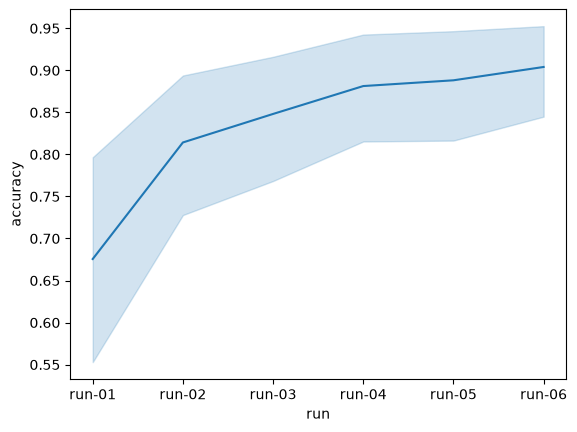

In [25]:
print(f'mean accuracy = {acc_df.accuracy.mean():.04f}')
sns.lineplot(acc_df, x='run', y='accuracy');

## `contrast-sound` for striatal network

In [26]:
# get the beta map for the contrast of interest for each subject
network_name = network_list[1]
contrast_label = contrast_list[0]
event_type = contrast_event_type[contrast_label]

In [27]:
sorted(glob(l1_dir_for(event_type)+f'/*/*event-{event_type}/sub*'))

['/ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn/fmriprep-25.2.5/scrubbed-splitfb/bids-deriv_level-1_fwhm-0.00/sub-FLT02_space-T1w/early_event-all/sub-FLT02',
 '/ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn/fmriprep-25.2.5/scrubbed-splitfb/bids-deriv_level-1_fwhm-0.00/sub-FLT02_space-T1w/final_event-all/sub-FLT02',
 '/ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn/fmriprep-25.2.5/scrubbed-splitfb/bids-deriv_level-1_fwhm-0.00/sub-FLT02_space-T1w/middle_event-all/sub-FLT02',
 '/ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn/fmriprep-25.2.5/scrubbed-splitfb/bids-deriv_level-1_fwhm-0.00/sub-FLT03_space-T1w/early_event-all/sub-FLT03',
 '/ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn/fmriprep-25.2.5/scrubbed-splitfb/bids-deriv_level-1_fwhm-0.00/sub-FLT03_space-T1w/final_event-all/sub-FLT03',
 '/ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn/fmriprep-25

In [28]:
sub_list

['sub-FLT03',
 'sub-FLT05',
 'sub-FLT08',
 'sub-FLT10',
 'sub-FLT15',
 'sub-FLT17',
 'sub-FLT18',
 'sub-FLT19',
 'sub-FLT21',
 'sub-FLT22',
 'sub-FLT23',
 'sub-FLT24',
 'sub-FLT26']

In [29]:
network_name

'tian-S2'

In [30]:
# per-group copy of the ROI table that the cells below (and robustness_checks.py) read
out_fname = f'univariate-results_network-{network_name}_contrast-{contrast_label}{group_suffix}.tsv'
combined_roi_df_fpath = os.path.join(group_out_dir, out_fname)

In [31]:
# this group's per-ROI values (from extract_roi_values.py), saved under the
# name the cells below and robustness_checks.py read
roi_df_long = load_roi_values(network_name, contrast_label)
roi_df_long.to_csv(combined_roi_df_fpath, sep='\t', index=False)
roi_df_long.groupby('learning_stage').participant_id.nunique()

learning_stage
early     13
final     13
middle    13
Name: participant_id, dtype: int64

In [32]:
# load the DataFrame if already exists
roi_df_long = pd.read_csv(combined_roi_df_fpath, sep='\t')

# create a bilateral-averaged dataframe (for across-contrast analysis)
sound_striatum_df = bilateral_mean(roi_df_long)


In [33]:
roi_df_long.participant_id.unique()

<StringArray>
['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17',
 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24',
 'sub-FLT26']
Length: 13, dtype: str

In [34]:
roi_df_long.region.unique()

<StringArray>
['aCAU', 'pCAU', 'aPUT', 'pPUT', 'NAc-shell', 'NAc-core']
Length: 6, dtype: str

In [35]:
print(network_name)
group_df = roi_df_long.copy()

# create a new column based on rostral–caudal axis
group_df['Axis'] = ''

if network_name == 'tian-S3':
    group_df.loc[(group_df['region']=='pCAU'),   'Axis'] = 'Caudal'
    group_df.loc[(group_df['region']=='PUT-VP'), 'Axis'] = 'Caudal'
    group_df.loc[(group_df['region']=='PUT-DP'), 'Axis'] = 'Caudal'

    group_df.loc[group_df['region']=='CAU-DA', 'Axis'] = 'Rostral'
    group_df.loc[group_df['region']=='CAU-VA', 'Axis'] = 'Rostral'
    group_df.loc[group_df['region']=='CAU-DP', 'Axis'] = 'Rostral'
    group_df.loc[group_df['region']=='CAU-VP', 'Axis'] = 'Rostral'

    group_df.loc[group_df['region']=='PUT-VA', 'Axis'] = 'Rostral'
    group_df.loc[group_df['region']=='PUT-DA', 'Axis'] = 'Rostral'

    group_df.loc[group_df['region']=='NAc-shell', 'Axis'] = 'Ventral'
    group_df.loc[group_df['region']=='NAc-core', 'Axis'] = 'Ventral'

elif network_name == 'tian-S2':
    group_df.loc[(group_df['region']=='pCAU'), 'Axis'] = 'Caudal'
    group_df.loc[(group_df['region']=='pPUT'), 'Axis'] = 'Caudal'    
    
    group_df.loc[(group_df['region']=='aCAU'), 'Axis'] = 'Rostral'
    group_df.loc[(group_df['region']=='aPUT'), 'Axis'] = 'Rostral'    

    group_df.loc[group_df['region']=='NAc-shell', 'Axis'] = 'Ventral'
    group_df.loc[group_df['region']=='NAc-core', 'Axis'] = 'Ventral'

group_df.head()

tian-S2


,participant_id,participant_group,region,beta,region_hemi,hemisphere,learning_stage,Axis
0,sub-FLT03,Mandarin,aCAU,-2.0616,aCAU-lh,lh,early,Rostral
1,sub-FLT03,Mandarin,aCAU,-4.8234,aCAU-lh,lh,middle,Rostral
2,sub-FLT03,Mandarin,aCAU,-1.9943,aCAU-lh,lh,final,Rostral
3,sub-FLT03,Mandarin,pCAU,1.6797,pCAU-lh,lh,early,Caudal
4,sub-FLT03,Mandarin,pCAU,-0.0898,pCAU-lh,lh,middle,Caudal


In [36]:
group_df.region_hemi.unique()

<StringArray>
[     'aCAU-lh',      'pCAU-lh',      'aPUT-lh',      'pPUT-lh',
 'NAc-shell-lh',  'NAc-core-lh',      'aCAU-rh',      'pCAU-rh',
      'aPUT-rh',      'pPUT-rh', 'NAc-shell-rh',  'NAc-core-rh']
Length: 12, dtype: str

In [37]:
group_df.participant_id.unique()

<StringArray>
['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17',
 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24',
 'sub-FLT26']
Length: 13, dtype: str

In [38]:
# right now, requires separate dictionaries per learning stage
# could be re-written to take roi_df_long or similar
'''
fig = plot_roi_slices_avg([roi_earlythird_mean_dict, roi_middlethird_mean_dict, roi_latethird_mean_dict],
                          mask_path_list, network_name, space_label)
'''

'\nfig = plot_roi_slices_avg([roi_earlythird_mean_dict, roi_middlethird_mean_dict, roi_latethird_mean_dict],\n                          mask_path_list, network_name, space_label)\n'

In [39]:
plot_order = ['aCAU', 'pCAU', 'aPUT', 'pPUT', 'NAc-core', 'NAc-shell']

/scratch/slurm-12192413/ipykernel_2562235/4213364461.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')


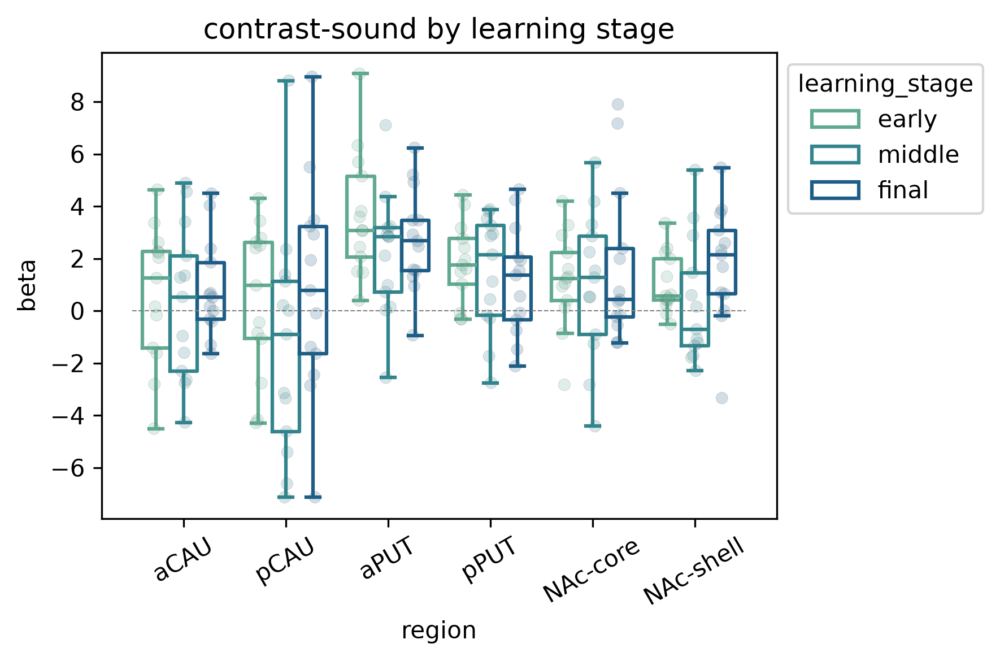

In [40]:
fig, ax = plt.subplots(1, 1, figsize=(6,4), dpi=300)

roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'learning_stage'], 
                                       as_index=False).agg({"beta": "mean"})

sns.boxplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='learning_stage', hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              fliersize = 0,            
              linewidth=1.5,
              fill=False,
              #legend=None,
              ax=ax);
sns.stripplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='learning_stage', hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              dodge=True,
              linewidth=0.2,
              alpha=.2,
              legend=None,
              ax=ax);


xmin, xmax = ax.get_xlim()
ax.hlines(y=0, xmin=xmin, xmax=xmax, color='0.5', linestyle='--', linewidth=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f'contrast-{contrast_label} by learning stage');
#ax.set_ylim([-5, 5])

fig.tight_layout()
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-stage.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-stage.png'))

/scratch/slurm-12192413/ipykernel_2562235/3292222178.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')


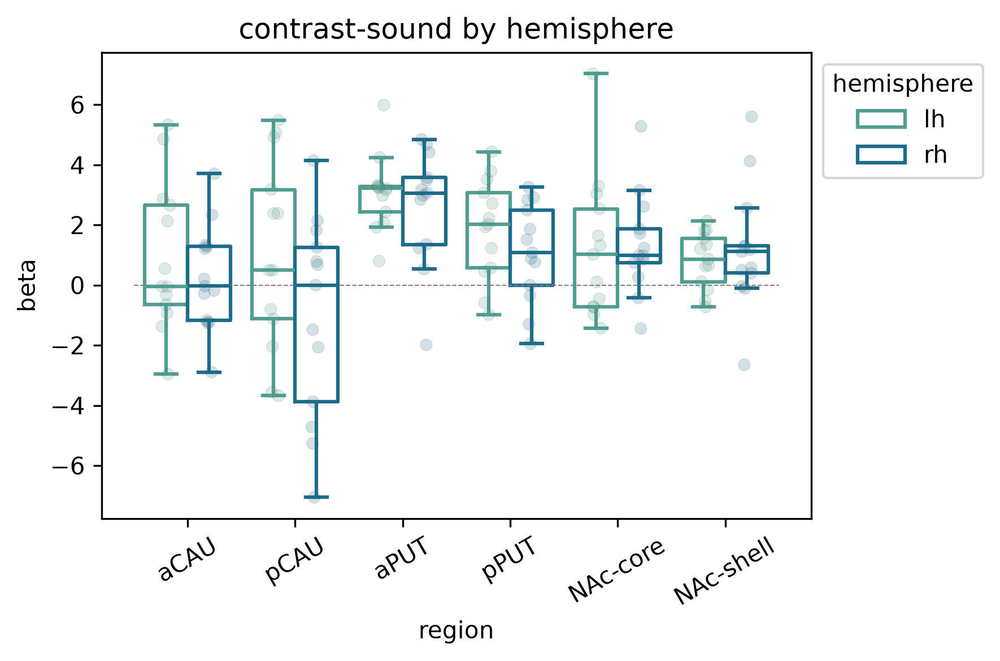

In [41]:
fig, ax = plt.subplots(1, 1, figsize=(6,4), dpi=300)

roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'hemisphere'], 
                                       as_index=False).agg({"beta": "mean"})

sns.boxplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='hemisphere', #hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              fliersize = 0,            
              linewidth=1.5,
              fill=False,
              #legend=None,
              ax=ax);
sns.stripplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='hemisphere', #hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              dodge=True,
              linewidth=0.2,
              alpha=.2,
              legend=None,
              ax=ax);


xmin, xmax = ax.get_xlim()
ax.hlines(y=0, xmin=xmin, xmax=xmax, color='0.5', linestyle='--', linewidth=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f'contrast-{contrast_label} by hemisphere');
#ax.set_ylim([-5, 5])

fig.tight_layout()

fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-hemisphere.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-hemisphere.png'))

### Brain-behavior correlations

In [42]:
# map runs to learning stages matching your thirds
stage_map = {'run-01': 'early', 'run-02': 'early',
             'run-03': 'middle', 'run-04': 'middle',
             'run-05': 'final', 'run-06': 'final'}

acc_df['learning_stage'] = acc_df['run'].map(stage_map)
acc_stage_df = acc_df.groupby(['participant_id', 'learning_stage'])['accuracy'].mean().reset_index()

In [43]:
# merge into roi_df_long — assumes participant_id and learning_stage columns exist in both
roi_df_bilateral = (roi_df_long.groupby(['participant_id', 'region', 'learning_stage'], as_index=False)['beta'].mean())
roi_behav_df = roi_df_bilateral.merge(acc_stage_df, on=['participant_id', 'learning_stage'])

# verify
roi_behav_df.groupby(['region', 'learning_stage']).size().unique()  # should be one row per participant


array([13])

In [44]:
roi_behav_df.columns

Index(['participant_id', 'region', 'learning_stage', 'beta', 'accuracy'], dtype='str')

In [45]:
roi_behav_df.participant_id.unique()

<StringArray>
['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17',
 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24',
 'sub-FLT26']
Length: 13, dtype: str

In [46]:
roi_behav_df.groupby(['region','learning_stage']).size().unique()


array([13])

In [47]:
results = []
for stage in ['early', 'middle', 'final']:
    stage_df = roi_behav_df[roi_behav_df['learning_stage'] == stage]
    for roi in stage_df['region'].unique():
        sub_df = stage_df[stage_df['region'] == roi]
        r = pg.corr(sub_df['accuracy'], sub_df['beta'], method='pearson')
        results.append({
            'roi': roi,
            'learning_stage': stage,
            'r': r['r'].values[0],
            'p': r['p_val'].values[0],
            'n': r['n'].values[0],
            'stat_str': stat_str('r', r['r'].values[0], r['p_val'].values[0])
        })

behav_corr_df = pd.DataFrame(results)

In [48]:
behav_corr_df

,roi,learning_stage,r,p,n,stat_str
0,NAc-core,early,-0.4709,0.1043,13,"r = -.47, p = .104"
1,NAc-shell,early,-0.0448,0.8844,13,"r = -.04, p = .884"
2,aCAU,early,-0.3848,0.1942,13,"r = -.38, p = .194"
3,aPUT,early,-0.5166,0.0707,13,"r = -.52, p = .071"
4,pCAU,early,-0.2790,0.3559,13,"r = -.28, p = .356"
5,pPUT,early,-0.1208,0.6942,13,"r = -.12, p = .694"
6,NAc-core,middle,0.0368,0.9051,13,"r = .04, p = .905"
7,NAc-shell,middle,-0.1752,0.5671,13,"r = -.18, p = .567"
8,aCAU,middle,-0.5835,0.0363,13,"r = -.58, p = .036"
9,aPUT,middle,-0.1567,0.6091,13,"r = -.16, p = .609"


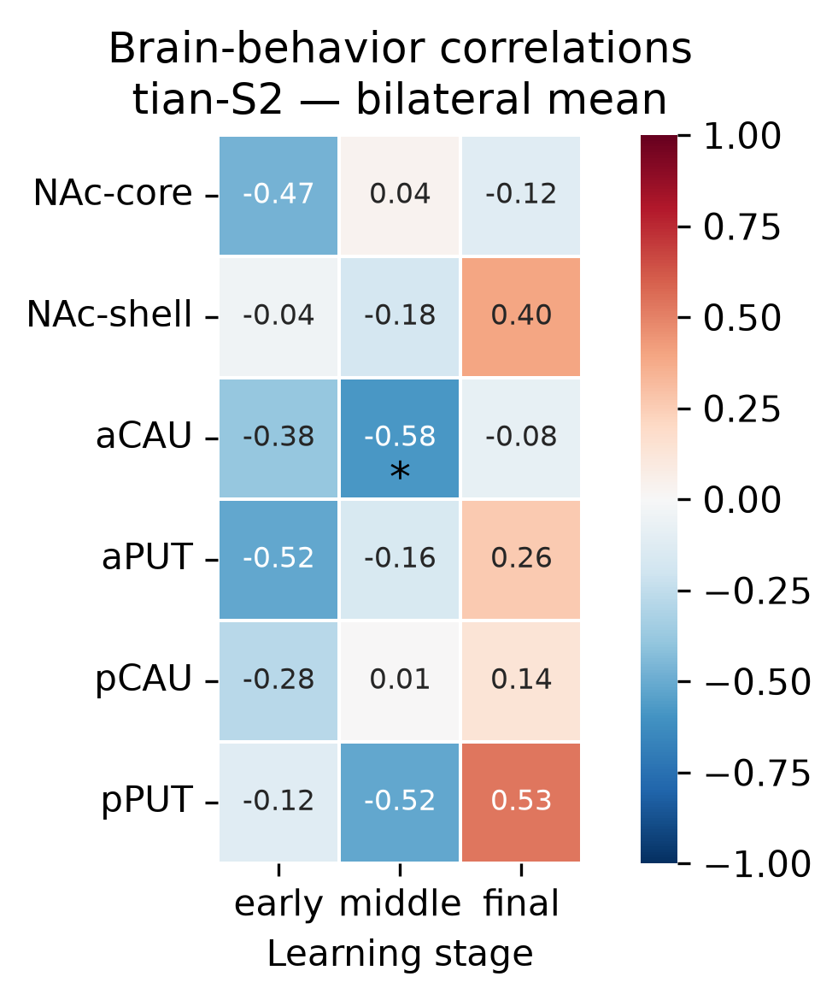

In [49]:
# pivot to ROI × stage matrix
r_matrix = behav_corr_df.pivot(index='roi', columns='learning_stage', values='r')[['early', 'middle', 'final']]
p_matrix = behav_corr_df.pivot(index='roi', columns='learning_stage', values='p')[['early', 'middle', 'final']]

fig, ax = plt.subplots(figsize=(5, len(r_matrix) * 0.5 + 1), dpi=300)
sns.heatmap(r_matrix, ax=ax, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot=True, fmt='.2f', annot_kws={'size': 8},
            square=True)

# mark significant cells with an asterisk
for i, roi in enumerate(r_matrix.index):
    for j, stage in enumerate(['early', 'middle', 'final']):
        p = p_matrix.loc[roi, stage]
        if p < 0.05:
            ax.text(j + 0.5, i + 0.85, '*', ha='center', va='center',
                    fontsize=12, color='black')

ax.set_title(f'Brain-behavior correlations\n{network_name} — bilateral mean')
ax.set_ylabel('')
ax.set_xlabel('Learning stage')
plt.tight_layout()
plt.savefig(os.path.join(fig_out_dir, f'brain-behav-corr_contrast-{contrast_label}_network-{network_name}_heatmap.svg'))

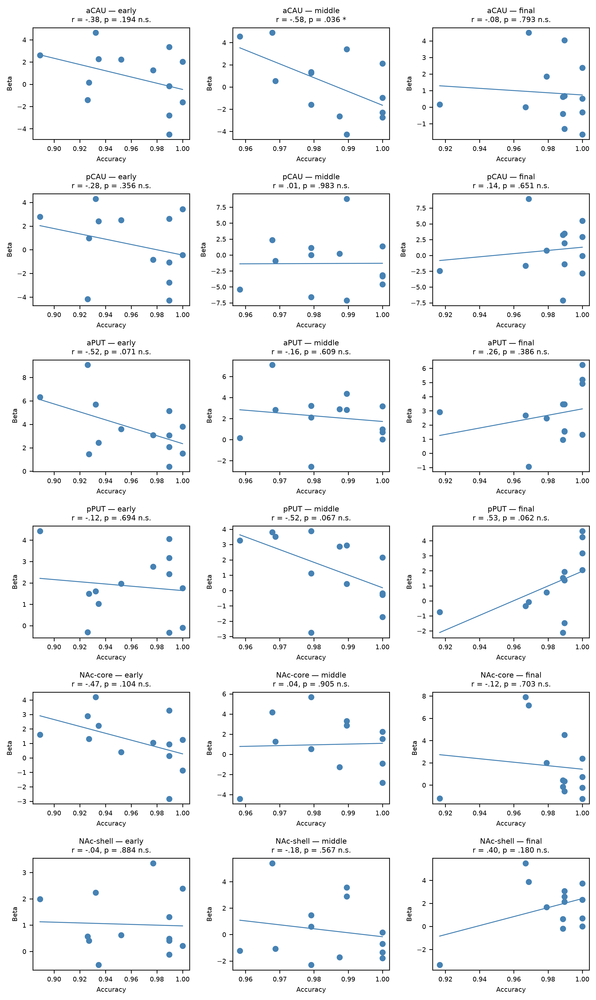

In [50]:
rois = behav_corr_df['roi'].unique()
stages = ['early', 'middle', 'final']

fig, axes = plt.subplots(len(rois), 3, figsize=(9, len(rois) * 2.5), dpi=300, sharex=False, sharey=False)

for ri, roi in enumerate(plot_order): # rois):
    for si, stage in enumerate(stages):
        ax = axes[ri, si]
        sub_df = roi_behav_df[(roi_behav_df['region'] == roi) & 
                              (roi_behav_df['learning_stage'] == stage)]
        
        ax.scatter(sub_df['accuracy'], sub_df['beta'], s=30, color='steelblue', zorder=3)
        
        # regression line
        m, b = np.polyfit(sub_df['accuracy'], sub_df['beta'], 1)
        x_range = np.linspace(sub_df['accuracy'].min(), sub_df['accuracy'].max(), 100)
        ax.plot(x_range, m * x_range + b, color='steelblue', linewidth=1)
        
        # stat annotation
        row = behav_corr_df[(behav_corr_df['roi'] == roi) & 
                            (behav_corr_df['learning_stage'] == stage)].iloc[0]
        p_str = '*' if row['p'] < 0.05 else 'n.s.'
        ax.set_title(f"{roi} — {stage}\n{row['stat_str']} {p_str}", fontsize=8)
        ax.set_xlabel('Accuracy', fontsize=7)
        ax.set_ylabel('Beta', fontsize=7)
        ax.tick_params(labelsize=7)

plt.tight_layout()
plt.savefig(os.path.join(fig_out_dir, f'brain-behav-corr_contrast-{contrast_label}_network-{network_name}_corr-plots.svg'))

NAc-core early: r = -.47, p = .104 n.s.
NAc-core middle: r = .04, p = .905 n.s.
NAc-core final: r = -.12, p = .703 n.s.
NAc-shell early: r = -.04, p = .884 n.s.
NAc-shell middle: r = -.18, p = .567 n.s.
NAc-shell final: r = .40, p = .180 n.s.
aCAU early: r = -.38, p = .194 n.s.
aCAU middle: r = -.58, p = .036 *
aCAU final: r = -.08, p = .793 n.s.
aPUT early: r = -.52, p = .071 n.s.
aPUT middle: r = -.16, p = .609 n.s.
aPUT final: r = .26, p = .386 n.s.
pCAU early: r = -.28, p = .356 n.s.
pCAU middle: r = .01, p = .983 n.s.
pCAU final: r = .14, p = .651 n.s.
pPUT early: r = -.12, p = .694 n.s.
pPUT middle: r = -.52, p = .067 n.s.
pPUT final: r = .53, p = .062 n.s.


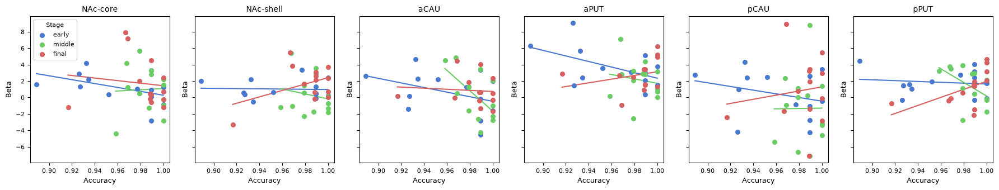

In [51]:
stage_colors = {'early': '#4878CF', 'middle': '#6ACC65', 'final': '#D65F5F'}
stages = ['early', 'middle', 'final']
rois = behav_corr_df['roi'].unique()

fig, axes = plt.subplots(1, len(rois), figsize=(3 * len(rois), 3.5), dpi=100, sharey=True)
if len(rois) == 1:
    axes = [axes]

for ri, roi in enumerate(rois):
    ax = axes[ri]
    for stage in stages:
        color = stage_colors[stage]
        sub_df = roi_behav_df[(roi_behav_df['region'] == roi) &
                              (roi_behav_df['learning_stage'] == stage)]

        ax.scatter(sub_df['accuracy'], sub_df['beta'], s=30,
                   color=color, label=stage, zorder=3)

        m, b = np.polyfit(sub_df['accuracy'], sub_df['beta'], 1)
        x_range = np.linspace(sub_df['accuracy'].min(), sub_df['accuracy'].max(), 100)
        ax.plot(x_range, m * x_range + b, color=color, linewidth=1.5)

        # stat annotation per stage
        row = behav_corr_df[(behav_corr_df['roi'] == roi) &
                            (behav_corr_df['learning_stage'] == stage)].iloc[0]
        p_str = '*' if row['p'] < 0.05 else 'n.s.'
        print(f"{roi} {stage}: {row['stat_str']} {p_str}")

    ax.set_title(roi, fontsize=10)
    ax.set_xlabel('Accuracy', fontsize=9)
    ax.set_ylabel('Beta', fontsize=9)
    ax.tick_params(labelsize=8)

axes[0].legend(title='Stage', fontsize=8, title_fontsize=8)
plt.tight_layout()


### omnibus ANOVA stats

In [52]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import AnovaRM
import pingouin as pg
import sys; sys.path.insert(0, '..')
from stats_fmt import export_anova, export_posthoc, export_ttests, export_pg_anova

In [53]:
group_df.head()

,participant_id,participant_group,region,beta,region_hemi,hemisphere,learning_stage,Axis
0,sub-FLT03,Mandarin,aCAU,-2.0616,aCAU-lh,lh,early,Rostral
1,sub-FLT03,Mandarin,aCAU,-4.8234,aCAU-lh,lh,middle,Rostral
2,sub-FLT03,Mandarin,aCAU,-1.9943,aCAU-lh,lh,final,Rostral
3,sub-FLT03,Mandarin,pCAU,1.6797,pCAU-lh,lh,early,Caudal
4,sub-FLT03,Mandarin,pCAU,-0.0898,pCAU-lh,lh,middle,Caudal


In [54]:
group_df.participant_id.unique()

<StringArray>
['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17',
 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24',
 'sub-FLT26']
Length: 13, dtype: str

#### Mixed-Effects ANOVA with Hemisphere, Axis, and Learning Stage

In [55]:
# Mixed-Effects ANOVA with Hemisphere, Axis, and Interaction
aov = AnovaRM(group_df, 
              aggregate_func='mean',
              depvar='beta', 
              subject='participant_id', 
              within=['hemisphere', 'learning_stage','Axis', ]).fit()

# Display results
print('network:', network_name)
print('contrast:', contrast_label)
aov.summary()

network: tian-S2
contrast: sound


,F Value,Num DF,Den DF,Pr > F
hemisphere,6.8663,1.0000,12.0000,0.0224
learning_stage,1.7745,2.0000,24.0000,0.1911
Axis,2.4617,2.0000,24.0000,0.1065
hemisphere:learning_stage,0.1758,2.0000,24.0000,0.8399
hemisphere:Axis,3.6846,2.0000,24.0000,0.0402
learning_stage:Axis,0.4797,4.0000,48.0000,0.7505
hemisphere:learning_stage:Axis,0.1293,4.0000,48.0000,0.9710


In [56]:
export_anova(aov, f'{contrast_label}_{network_name}_hemisphere_learning-stage_axis', stats_out_dir)

,source,F,df_num,df_den,p,stat_str
0,hemisphere,6.87,1.0000,12.0000,p = .022,"F(1, 12) = 6.87, p = .022"
1,learning_stage,1.77,2.0000,24.0000,p = .191,"F(2, 24) = 1.77, p = .191"
2,Axis,2.46,2.0000,24.0000,p = .107,"F(2, 24) = 2.46, p = .107"
3,hemisphere:learning_stage,0.18,2.0000,24.0000,p = .840,"F(2, 24) = 0.18, p = .840"
4,hemisphere:Axis,3.68,2.0000,24.0000,p = .040,"F(2, 24) = 3.68, p = .040"
5,learning_stage:Axis,0.48,4.0000,48.0000,p = .750,"F(4, 48) = 0.48, p = .750"
6,hemisphere:learning_stage:Axis,0.13,4.0000,48.0000,p = .971,"F(4, 48) = 0.13, p = .971"


In [57]:
# GG-corrected bilateral replication (learning_stage x Axis)
bilateral_df = (group_df
                .groupby(['participant_id', 'Axis', 'learning_stage'], as_index=False)['beta']
                .mean())
aov_pg = pg.rm_anova(data=bilateral_df, dv='beta',
                     within=['learning_stage', 'Axis'],
                     subject='participant_id',
                     detailed=True)
eta_col = 'np2' if 'np2' in aov_pg.columns else 'ng2'
print(aov_pg[['Source', 'F', 'ddof1', 'ddof2', 'p_unc', 'p_GG_corr', eta_col]])
export_pg_anova(aov_pg, f'{contrast_label}_{network_name}_learning-stage_axis_bilateral', stats_out_dir)

                  Source      F  ddof1  ddof2  p_unc  p_GG_corr    ng2
0         learning_stage 1.7745      2     24 0.1911     0.1912 0.0369
1                   Axis 2.4617      2     24 0.1065     0.1211 0.0377
2  learning_stage * Axis 0.4797      4     48 0.7505     0.6391 0.0073


/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/pingouin/distribution.py:514: UserWarning: Epsilon values might be innaccurate in two-way repeated measures design where each  factor has more than 2 levels. Please  double-check your results.
  warnings.warn(


,source,df_num,df_den,F,p_unc,p_GG_corr,eta_p2,stat_str
0,learning_stage,2,24,1.77,p = .191,p = .191,0.04,"F(2, 24) = 1.77, p = .191"
1,Axis,2,24,2.46,p = .107,p = .121,0.04,"F(2, 24) = 2.46, p = .121"
2,learning_stage * Axis,4,48,0.48,p = .750,p = .639,0.01,"F(4, 48) = 0.48, p = .639"


In [58]:
aov_pg

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,learning_stage,18.6389,2,24,9.3195,1.7745,0.1911,0.1912,0.0369,0.9972
1,Axis,19.0484,2,24,9.5242,2.4617,0.1065,0.1211,0.0377,0.7898
2,learning_stage * Axis,3.5635,4,48,0.8909,0.4797,0.7505,0.6391,0.0073,0.5411


In [59]:
# pairwise by Axis

# Pairwise comparisons for region with FDR correction
pairwise_by_region = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['hemisphere','Axis', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_region.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_region)
#pairwise_by_region[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_region[pairwise_by_region.Contrast.str.contains(' * ')].reset_index()
#pairwise_interaction = pairwise_interaction[pairwise_interaction['p_unc'] < 0.05]
pairwise_interaction[['Contrast', 'hemisphere','A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'hemisphere', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof',
       'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,hemisphere,A,B,T,dof,p_unc,p_corr,BF10
0,hemisphere * Axis,lh,Caudal,Rostral,-1.2863,12.0000,0.2226,0.3339,0.55
1,hemisphere * Axis,lh,Caudal,Ventral,0.7712,12.0000,0.4555,0.5466,0.359
2,hemisphere * Axis,lh,Rostral,Ventral,1.7446,12.0000,0.1066,0.2132,0.917
3,hemisphere * Axis,rh,Caudal,Rostral,-3.0250,12.0000,0.0106,0.0634,5.54
4,hemisphere * Axis,rh,Caudal,Ventral,-1.7551,12.0000,0.1047,0.2132,0.928
5,hemisphere * Axis,rh,Rostral,Ventral,0.2902,12.0000,0.7766,0.7766,0.289


In [60]:
export_posthoc(pairwise_by_region, f'{contrast_label}_{network_name}_hemisphere_axis', stats_out_dir)

,Contrast,hemisphere,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,hemisphere,-,lh,rh,2.62,12.0000,p = .022,p = nan,"t(12) = 2.62, p = .022","t(12) = 2.62, q = nan"
1,Axis,-,Caudal,Rostral,-2.63,12.0000,p = .022,p = .066,"t(12) = -2.63, p = .022","t(12) = -2.63, q = .066"
2,Axis,-,Caudal,Ventral,-0.78,12.0000,p = .452,p = .452,"t(12) = -0.78, p = .452","t(12) = -0.78, q = .452"
3,Axis,-,Rostral,Ventral,1.42,12.0000,p = .180,p = .270,"t(12) = 1.42, p = .180","t(12) = 1.42, q = .270"
4,hemisphere * Axis,lh,Caudal,Rostral,-1.29,12.0000,p = .223,p = .334,"t(12) = -1.29, p = .223","t(12) = -1.29, q = .334"
5,hemisphere * Axis,lh,Caudal,Ventral,0.77,12.0000,p = .456,p = .547,"t(12) = 0.77, p = .456","t(12) = 0.77, q = .547"
6,hemisphere * Axis,lh,Rostral,Ventral,1.74,12.0000,p = .107,p = .213,"t(12) = 1.74, p = .107","t(12) = 1.74, q = .213"
7,hemisphere * Axis,rh,Caudal,Rostral,-3.03,12.0000,p = .011,p = .063,"t(12) = -3.03, p = .011","t(12) = -3.03, q = .063"
8,hemisphere * Axis,rh,Caudal,Ventral,-1.76,12.0000,p = .105,p = .213,"t(12) = -1.76, p = .105","t(12) = -1.76, q = .213"
9,hemisphere * Axis,rh,Rostral,Ventral,0.29,12.0000,p = .777,p = .777,"t(12) = 0.29, p = .777","t(12) = 0.29, q = .777"


In [61]:
# pairwise by Axis

# Pairwise comparisons for region with FDR correction
pairwise_by_region = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['Axis', 'hemisphere',],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_region.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_region)
#pairwise_by_region[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_region[pairwise_by_region.Contrast.str.contains(' * ')].reset_index()
#pairwise_interaction = pairwise_interaction[pairwise_interaction['p_unc'] < 0.05]
pairwise_interaction[['Contrast', 'Axis', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'Axis', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof',
       'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,Axis,A,B,T,dof,p_unc,p_corr,BF10
0,Axis * hemisphere,Caudal,lh,rh,2.7481,12.0000,0.0177,0.0530,3.656
1,Axis * hemisphere,Rostral,lh,rh,1.8024,12.0000,0.0966,0.1450,0.984
2,Axis * hemisphere,Ventral,lh,rh,-0.6760,12.0000,0.5119,0.5119,0.339


In [62]:
export_posthoc(pairwise_by_region, f'{contrast_label}_{network_name}_axis_hemisphere', stats_out_dir)

,Contrast,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,Axis,Caudal,Rostral,-2.63,12.0000,p = .022,p = .066,"t(12) = -2.63, p = .022","t(12) = -2.63, q = .066"
1,Axis,Caudal,Ventral,-0.78,12.0000,p = .452,p = .452,"t(12) = -0.78, p = .452","t(12) = -0.78, q = .452"
2,Axis,Rostral,Ventral,1.42,12.0000,p = .180,p = .270,"t(12) = 1.42, p = .180","t(12) = 1.42, q = .270"
3,hemisphere,lh,rh,2.62,12.0000,p = .022,p = nan,"t(12) = 2.62, p = .022","t(12) = 2.62, q = nan"
4,Axis * hemisphere,lh,rh,2.75,12.0000,p = .018,p = .053,"t(12) = 2.75, p = .018","t(12) = 2.75, q = .053"
5,Axis * hemisphere,lh,rh,1.80,12.0000,p = .097,p = .145,"t(12) = 1.80, p = .097","t(12) = 1.80, q = .145"
6,Axis * hemisphere,lh,rh,-0.68,12.0000,p = .512,p = .512,"t(12) = -0.68, p = .512","t(12) = -0.68, q = .512"


In [63]:
# pairwise by region, no learning stage

# Pairwise comparisons for region with FDR correction
pairwise_by_region_only = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['Axis', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_region_only.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_region_only)
#pairwise_by_region_only = pairwise_by_region_only[pairwise_by_region_only['p_unc'] < 0.05]
pairwise_by_region_only#[['Contrast', 'Contrast', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns


Available columns: Index(['Contrast', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof', 'alternative',
       'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,Axis,Caudal,Rostral,True,True,-2.6294,12.0000,two-sided,0.0220,0.0660,fdr,3.068,-0.5655
1,Axis,Caudal,Ventral,True,True,-0.7769,12.0000,two-sided,0.4523,0.4523,fdr,0.36,-0.2472
2,Axis,Rostral,Ventral,True,True,1.4241,12.0000,two-sided,0.1799,0.2698,fdr,0.634,0.3928


In [64]:
export_posthoc(pairwise_by_region_only, f'{contrast_label}_{network_name}_axis', stats_out_dir)

,Contrast,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,Axis,Caudal,Rostral,-2.63,12.0000,p = .022,p = .066,"t(12) = -2.63, p = .022","t(12) = -2.63, q = .066"
1,Axis,Caudal,Ventral,-0.78,12.0000,p = .452,p = .452,"t(12) = -0.78, p = .452","t(12) = -0.78, q = .452"
2,Axis,Rostral,Ventral,1.42,12.0000,p = .180,p = .270,"t(12) = 1.42, p = .180","t(12) = 1.42, q = .270"


#### Mixed-Effects ANOVA with Hemisphere, Region, and Learning Stage

In [65]:
# Mixed-Effects ANOVA with Hemisphere, Region, and Interaction
aov = AnovaRM(group_df, 
              aggregate_func='mean',
              depvar='beta', 
              subject='participant_id', 
              within=['hemisphere', 'learning_stage','region', ]).fit()

# Display results
print('network:', network_name)
print('contrast:', contrast_label)
aov.summary()

network: tian-S2
contrast: sound


,F Value,Num DF,Den DF,Pr > F
hemisphere,6.8663,1.0000,12.0000,0.0224
learning_stage,1.7745,2.0000,24.0000,0.1911
region,5.0273,5.0000,60.0000,0.0007
hemisphere:learning_stage,0.1758,2.0000,24.0000,0.8399
hemisphere:region,2.9442,5.0000,60.0000,0.0192
learning_stage:region,0.9938,10.0000,120.0000,0.4527
hemisphere:learning_stage:region,0.5661,10.0000,120.0000,0.8387


In [66]:
export_anova(aov, f'{contrast_label}_{network_name}_hemisphere_learning-stage_region', stats_out_dir)

,source,F,df_num,df_den,p,stat_str
0,hemisphere,6.87,1.0000,12.0000,p = .022,"F(1, 12) = 6.87, p = .022"
1,learning_stage,1.77,2.0000,24.0000,p = .191,"F(2, 24) = 1.77, p = .191"
2,region,5.03,5.0000,60.0000,p < .001,"F(5, 60) = 5.03, p < .001"
3,hemisphere:learning_stage,0.18,2.0000,24.0000,p = .840,"F(2, 24) = 0.18, p = .840"
4,hemisphere:region,2.94,5.0000,60.0000,p = .019,"F(5, 60) = 2.94, p = .019"
5,learning_stage:region,0.99,10.0000,120.0000,p = .453,"F(10, 120) = 0.99, p = .453"
6,hemisphere:learning_stage:region,0.57,10.0000,120.0000,p = .839,"F(10, 120) = 0.57, p = .839"


In [67]:
# GG-corrected bilateral replication (learning_stage x region)
bilateral_df = (group_df
                .groupby(['participant_id', 'region', 'learning_stage'], as_index=False)['beta']
                .mean())
aov_pg = pg.rm_anova(data=bilateral_df, dv='beta',
                     within=['learning_stage', 'region'],
                     subject='participant_id',
                     detailed=True)
eta_col = 'np2' if 'np2' in aov_pg.columns else 'ng2'
print(aov_pg[['Source', 'F', 'ddof1', 'ddof2', 'p_unc', 'p_GG_corr', eta_col]])
export_pg_anova(aov_pg, f'{contrast_label}_{network_name}_learning-stage_region_bilateral', stats_out_dir)

                    Source      F  ddof1  ddof2  p_unc  p_GG_corr    ng2
0           learning_stage 1.7745      2     24 0.1911     0.1912 0.0246
1                   region 5.0273      5     60 0.0007     0.0074 0.1107
2  learning_stage * region 0.9938     10    120 0.4527     0.4103 0.0235


/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/pingouin/distribution.py:514: UserWarning: Epsilon values might be innaccurate in two-way repeated measures design where each  factor has more than 2 levels. Please  double-check your results.
  warnings.warn(


,source,df_num,df_den,F,p_unc,p_GG_corr,eta_p2,stat_str
0,learning_stage,2,24,1.77,p = .191,p = .191,0.02,"F(2, 24) = 1.77, p = .191"
1,region,5,60,5.03,p < .001,p = .007,0.11,"F(5, 60) = 5.03, p = .007"
2,learning_stage * region,10,120,0.99,p = .453,p = .410,0.02,"F(10, 120) = 0.99, p = .410"


In [68]:
# Pairwise comparisons for region with FDR correction
pairwise_by_learning_stage = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['hemisphere','region', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_learning_stage.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_learning_stage)
#pairwise_by_learning_stage[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_learning_stage[pairwise_by_learning_stage.Contrast.str.contains(' * ')].reset_index()
pairwise_interaction = pairwise_interaction[pairwise_interaction['p_corr'] < 0.05].reset_index()
pairwise_interaction[['Contrast', 'hemisphere', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'hemisphere', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof',
       'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,hemisphere,A,B,T,dof,p_unc,p_corr,BF10
0,hemisphere * region,lh,NAc-core,aPUT,-3.2022,12.0000,0.0076,0.0456,7.251
1,hemisphere * region,lh,NAc-shell,aPUT,-5.7826,12.0000,0.0001,0.0026,325.35
2,hemisphere * region,lh,aCAU,aPUT,-3.5181,12.0000,0.0042,0.0318,11.749
3,hemisphere * region,rh,aCAU,aPUT,-3.7265,12.0000,0.0029,0.0289,16.161
4,hemisphere * region,rh,aPUT,pCAU,3.9728,12.0000,0.0019,0.0278,23.525


In [69]:
export_posthoc(pairwise_by_learning_stage, f'{contrast_label}_{network_name}_hemisphere_region', stats_out_dir)

,Contrast,hemisphere,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,hemisphere,-,lh,rh,2.62,12.0000,p = .022,p = nan,"t(12) = 2.62, p = .022","t(12) = 2.62, q = nan"
1,region,-,NAc-core,NAc-shell,0.63,12.0000,p = .538,p = .576,"t(12) = 0.63, p = .538","t(12) = 0.63, q = .576"
2,region,-,NAc-core,aCAU,1.05,12.0000,p = .313,p = .392,"t(12) = 1.05, p = .313","t(12) = 1.05, q = .392"
3,region,-,NAc-core,aPUT,-3.55,12.0000,p = .004,p = .014,"t(12) = -3.55, p = .004","t(12) = -3.55, q = .014"
4,region,-,NAc-core,pCAU,1.45,12.0000,p = .171,p = .323,"t(12) = 1.45, p = .171","t(12) = 1.45, q = .323"
5,region,-,NAc-core,pPUT,-0.31,12.0000,p = .760,p = .760,"t(12) = -0.31, p = .760","t(12) = -0.31, q = .760"
6,region,-,NAc-shell,aCAU,0.78,12.0000,p = .449,p = .518,"t(12) = 0.78, p = .449","t(12) = 0.78, q = .518"
7,region,-,NAc-shell,aPUT,-4.16,12.0000,p = .001,p = .014,"t(12) = -4.16, p = .001","t(12) = -4.16, q = .014"
8,region,-,NAc-shell,pCAU,1.38,12.0000,p = .194,p = .323,"t(12) = 1.38, p = .194","t(12) = 1.38, q = .323"
9,region,-,NAc-shell,pPUT,-1.10,12.0000,p = .293,p = .392,"t(12) = -1.10, p = .293","t(12) = -1.10, q = .392"


In [70]:
# Pairwise comparisons for region with FDR correction
pairwise_by_learning_stage = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['region', 'hemisphere',],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_learning_stage.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_learning_stage)
#pairwise_by_learning_stage[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_learning_stage[pairwise_by_learning_stage.Contrast.str.contains(' * ')].reset_index()
#pairwise_interaction = pairwise_interaction[pairwise_interaction['p_corr'] < 0.05].reset_index()
pairwise_interaction[['Contrast', 'region', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'region', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof',
       'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,region,A,B,T,dof,p_unc,p_corr,BF10
0,region * hemisphere,NAc-core,lh,rh,-0.2929,12.0000,0.7746,0.7746,0.289
1,region * hemisphere,NAc-shell,lh,rh,-0.7785,12.0000,0.4514,0.5416,0.361
2,region * hemisphere,aCAU,lh,rh,2.1664,12.0000,0.0511,0.1534,1.587
3,region * hemisphere,aPUT,lh,rh,1.1785,12.0000,0.2614,0.3922,0.496
4,region * hemisphere,pCAU,lh,rh,2.7032,12.0000,0.0192,0.1152,3.421
5,region * hemisphere,pPUT,lh,rh,1.9161,12.0000,0.0795,0.1589,1.137


In [71]:
export_posthoc(pairwise_by_learning_stage, f'{contrast_label}_{network_name}_region_hemisphere', stats_out_dir)

,Contrast,region,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,region,-,NAc-core,NAc-shell,0.63,12.0000,p = .538,p = .576,"t(12) = 0.63, p = .538","t(12) = 0.63, q = .576"
1,region,-,NAc-core,aCAU,1.05,12.0000,p = .313,p = .392,"t(12) = 1.05, p = .313","t(12) = 1.05, q = .392"
2,region,-,NAc-core,aPUT,-3.55,12.0000,p = .004,p = .014,"t(12) = -3.55, p = .004","t(12) = -3.55, q = .014"
3,region,-,NAc-core,pCAU,1.45,12.0000,p = .171,p = .323,"t(12) = 1.45, p = .171","t(12) = 1.45, q = .323"
4,region,-,NAc-core,pPUT,-0.31,12.0000,p = .760,p = .760,"t(12) = -0.31, p = .760","t(12) = -0.31, q = .760"
5,region,-,NAc-shell,aCAU,0.78,12.0000,p = .449,p = .518,"t(12) = 0.78, p = .449","t(12) = 0.78, q = .518"
6,region,-,NAc-shell,aPUT,-4.16,12.0000,p = .001,p = .014,"t(12) = -4.16, p = .001","t(12) = -4.16, q = .014"
7,region,-,NAc-shell,pCAU,1.38,12.0000,p = .194,p = .323,"t(12) = 1.38, p = .194","t(12) = 1.38, q = .323"
8,region,-,NAc-shell,pPUT,-1.10,12.0000,p = .293,p = .392,"t(12) = -1.10, p = .293","t(12) = -1.10, q = .392"
9,region,-,aCAU,aPUT,-3.73,12.0000,p = .003,p = .014,"t(12) = -3.73, p = .003","t(12) = -3.73, q = .014"


In [72]:
# pairwise by region, no learning stage

# Pairwise comparisons for region with FDR correction
pairwise_by_region_only = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['region', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_region_only.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_region_only)
pairwise_by_region_only = pairwise_by_region_only[pairwise_by_region_only['p_unc'] < 0.05]
pairwise_by_region_only[['Contrast', 'Contrast', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns


Available columns: Index(['Contrast', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof', 'alternative',
       'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,Contrast,A,B,T,dof,p_unc,p_corr,BF10
2,region,region,NAc-core,aPUT,-3.5485,12.0000,0.0040,0.0139,12.309
6,region,region,NAc-shell,aPUT,-4.1602,12.0000,0.0013,0.0139,31.251
9,region,region,aCAU,aPUT,-3.7288,12.0000,0.0029,0.0139,16.219
12,region,region,aPUT,pCAU,3.6237,12.0000,0.0035,0.0139,13.81
13,region,region,aPUT,pPUT,3.4703,12.0000,0.0046,0.0139,10.921


In [73]:
export_posthoc(pairwise_by_region_only, f'{contrast_label}_{network_name}_region', stats_out_dir)

,Contrast,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
2,region,NAc-core,aPUT,-3.55,12.0000,p = .004,p = .014,"t(12) = -3.55, p = .004","t(12) = -3.55, q = .014"
6,region,NAc-shell,aPUT,-4.16,12.0000,p = .001,p = .014,"t(12) = -4.16, p = .001","t(12) = -4.16, q = .014"
9,region,aCAU,aPUT,-3.73,12.0000,p = .003,p = .014,"t(12) = -3.73, p = .003","t(12) = -3.73, q = .014"
12,region,aPUT,pCAU,3.62,12.0000,p = .003,p = .014,"t(12) = 3.62, p = .003","t(12) = 3.62, q = .014"
13,region,aPUT,pPUT,3.47,12.0000,p = .005,p = .014,"t(12) = 3.47, p = .005","t(12) = 3.47, q = .014"


In [74]:
# pairwise by region, no learning stage

# Pairwise comparisons for region with FDR correction
pairwise_by_region_only = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['learning_stage', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_region_only.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_region_only)
#pairwise_by_region_only = pairwise_by_region_only[pairwise_by_region_only['p_unc'] < 0.05]
pairwise_by_region_only[['Contrast', 'Contrast', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns


Available columns: Index(['Contrast', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof', 'alternative',
       'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,Contrast,A,B,T,dof,p_unc,p_corr,BF10
0,learning_stage,learning_stage,early,final,-0.0892,12.0000,0.9304,0.9304,0.279
1,learning_stage,learning_stage,early,middle,1.5677,12.0000,0.1429,0.2144,0.743
2,learning_stage,learning_stage,final,middle,1.7204,12.0000,0.1110,0.2144,0.89


In [75]:
export_posthoc(pairwise_by_region_only, f'{contrast_label}_{network_name}_learning-stage', stats_out_dir)

,Contrast,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,learning_stage,early,final,-0.09,12.0000,p = .930,p = .930,"t(12) = -0.09, p = .930","t(12) = -0.09, q = .930"
1,learning_stage,early,middle,1.57,12.0000,p = .143,p = .214,"t(12) = 1.57, p = .143","t(12) = 1.57, q = .214"
2,learning_stage,final,middle,1.72,12.0000,p = .111,p = .214,"t(12) = 1.72, p = .111","t(12) = 1.72, q = .214"


### Collapse (average) over non-significant factors

In [76]:
roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'learning_stage'], 
                                       as_index=False).agg({"beta": "mean"})


In [77]:
# Collect results
results = []

# average within participant first: one value per participant, so n (and df) = number of participants
for region, data in (roi_df_collapsed.groupby(["participant_id", "region"], as_index=False)["beta"].mean()
                     .groupby("region")):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    results.append({
        "region": region,
        "t_stat": t_stat,
        "p_val": p_val
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Apply FDR correction
results_df["p_val_fdr"] = multipletests(results_df["p_val"], method="fdr_bh")[1]

# Print or export the table
results_df

# Optional: export
# results_df.to_csv("roi_stats.csv", index=False)
# results_df.to_excel("roi_stats.xlsx", index=False)


,region,t_stat,p_val,p_val_fdr
0,NAc-core,2.6212,0.0223,0.0335
1,NAc-shell,2.8626,0.0143,0.0286
2,aCAU,1.0193,0.3282,0.3938
3,aPUT,7.0532,0.0000,0.0001
4,pCAU,-0.0190,0.9851,0.9851
5,pPUT,3.6174,0.0035,0.0106


In [78]:
_export = results_df.rename(columns={'t_stat': 't', 'p_val': 'p'}).copy()
_export['df'] = len(sub_list) - 1
export_ttests(_export.to_dict('records'), f'{contrast_label}_{network_name}_baseline_by_region', stats_out_dir)

,region,t,p,p_val_fdr,df,p_fdr,stat_str,stat_str_fdr
0,NAc-core,2.62,p = .022,0.0335,12,p = .034,"t(12) = 2.62, p = .022","t(12) = 2.62, q = .034"
1,NAc-shell,2.86,p = .014,0.0286,12,p = .029,"t(12) = 2.86, p = .014","t(12) = 2.86, q = .029"
2,aCAU,1.02,p = .328,0.3938,12,p = .394,"t(12) = 1.02, p = .328","t(12) = 1.02, q = .394"
3,aPUT,7.05,p < .001,0.0001,12,p < .001,"t(12) = 7.05, p < .001","t(12) = 7.05, q < .001"
4,pCAU,-0.02,p = .985,0.9851,12,p = .985,"t(12) = -0.02, p = .985","t(12) = -0.02, q = .985"
5,pPUT,3.62,p = .004,0.0106,12,p = .011,"t(12) = 3.62, p = .004","t(12) = 3.62, q = .011"


### Make 3D plots

In [79]:

roi_df_collapsed = roi_df_long.groupby(["participant_id", "region_hemi"], 
                                       as_index=False).agg({"beta": "mean"})

# Collect p-values
p_values = []
t_stats = []
comparisons = []

for region, data in roi_df_collapsed.groupby(["region_hemi"]):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    p_values.append(p_val)
    comparisons.append((region[0], t_stat))
    t_stats.append(t_stat)

# Apply FDR correction
_, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Print corrected results
for (region, t_stat), p_val_corr in zip(comparisons, p_corrected):
    print(f"Region: {region}, t = {t_stat:.2f}; corrected p = {p_val_corr:.4f}")


Region: NAc-core-lh, t = 1.85; corrected p = 0.1347
Region: NAc-core-rh, t = 2.95; corrected p = 0.0290
Region: NAc-shell-lh, t = 3.20; corrected p = 0.0230
Region: NAc-shell-rh, t = 2.17; corrected p = 0.0869
Region: aCAU-lh, t = 1.36; corrected p = 0.2663
Region: aCAU-rh, t = 0.48; corrected p = 0.6375
Region: aPUT-lh, t = 9.06; corrected p = 0.0000
Region: aPUT-rh, t = 4.96; corrected p = 0.0020
Region: pCAU-lh, t = 1.15; corrected p = 0.3072
Region: pCAU-rh, t = -1.13; corrected p = 0.3072
Region: pPUT-lh, t = 4.05; corrected p = 0.0064
Region: pPUT-rh, t = 2.38; corrected p = 0.0701


In [80]:

_records = [{'region_hemi': c[0], 't': c[1], 'df': len(sub_list) - 1, 'p': p}
            for c, p in zip(comparisons, p_values)]
export_ttests(_records, f'{contrast_label}_{network_name}_baseline_by_region_hemi', stats_out_dir)

,region_hemi,t,df,p,p_fdr,stat_str,stat_str_fdr
0,NAc-core-lh,1.85,12,p = .090,p = .135,"t(12) = 1.85, p = .090","t(12) = 1.85, q = .135"
1,NAc-core-rh,2.95,12,p = .012,p = .029,"t(12) = 2.95, p = .012","t(12) = 2.95, q = .029"
2,NAc-shell-lh,3.20,12,p = .008,p = .023,"t(12) = 3.20, p = .008","t(12) = 3.20, q = .023"
3,NAc-shell-rh,2.17,12,p = .051,p = .087,"t(12) = 2.17, p = .051","t(12) = 2.17, q = .087"
4,aCAU-lh,1.36,12,p = .200,p = .266,"t(12) = 1.36, p = .200","t(12) = 1.36, q = .266"
5,aCAU-rh,0.48,12,p = .638,p = .638,"t(12) = 0.48, p = .638","t(12) = 0.48, q = .638"
6,aPUT-lh,9.06,12,p < .001,p < .001,"t(12) = 9.06, p < .001","t(12) = 9.06, q < .001"
7,aPUT-rh,4.96,12,p < .001,p = .002,"t(12) = 4.96, p < .001","t(12) = 4.96, q = .002"
8,pCAU-lh,1.15,12,p = .271,p = .307,"t(12) = 1.15, p = .271","t(12) = 1.15, q = .307"
9,pCAU-rh,-1.13,12,p = .282,p = .307,"t(12) = -1.13, p = .282","t(12) = -1.13, q = .307"


### Striatal ROI plot (t-statistic)

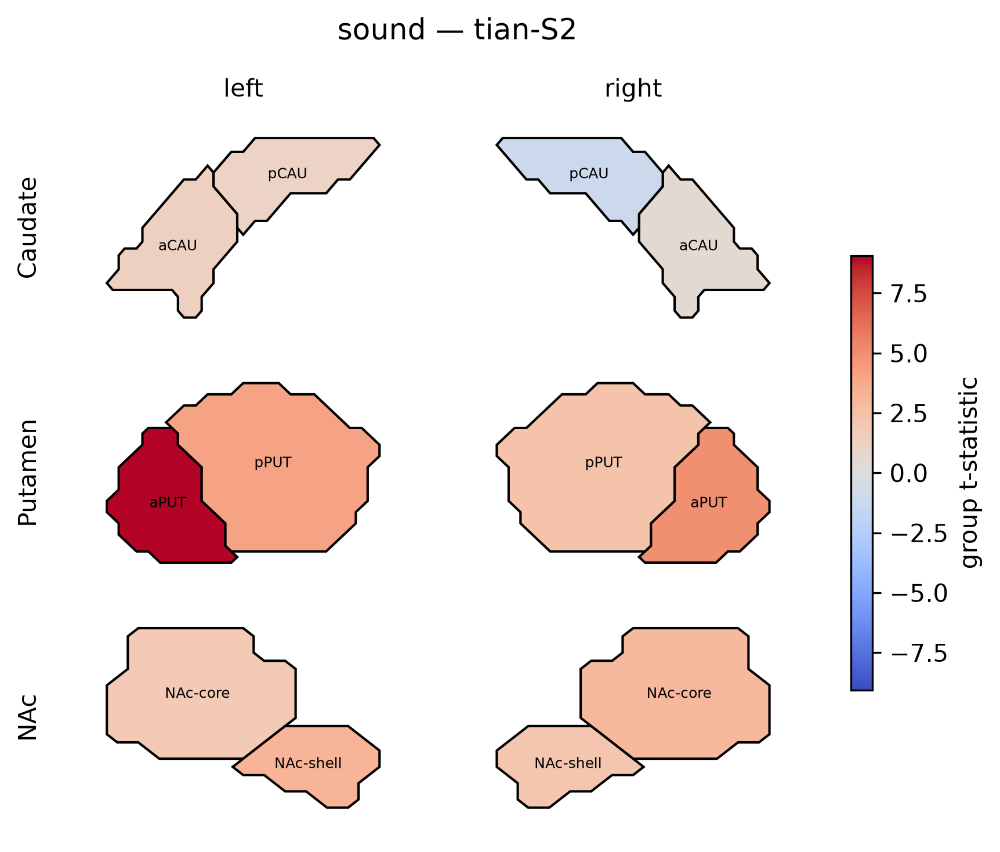

In [81]:
structure_groups = {
    'Caudate': ['aCAU', 'pCAU'],
    'Putamen': ['aPUT', 'pPUT'],
    'NAc': ['NAc-core', 'NAc-shell'],
}
stat_dict = {c[0]: c[1] for c in comparisons}
mask_path_dict = build_mask_path_dict(list(stat_dict.keys()), masks_dir, network_name, surf_space_label)

fig = plot_striatal_roi_stat(stat_dict, mask_path_dict, structure_groups, title=f'{contrast_label} — {network_name}')
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_striatal-tstat.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_striatal-tstat.png'))


### Striatal ROI plot (t-statistic) — yabplot alternative

2026-11-12 17:01:44.258 (   5.086s) [    7FE796AAB740]vtkXOpenGLRenderWindow.:1460  WARN| bad X server connection. DISPLAY=


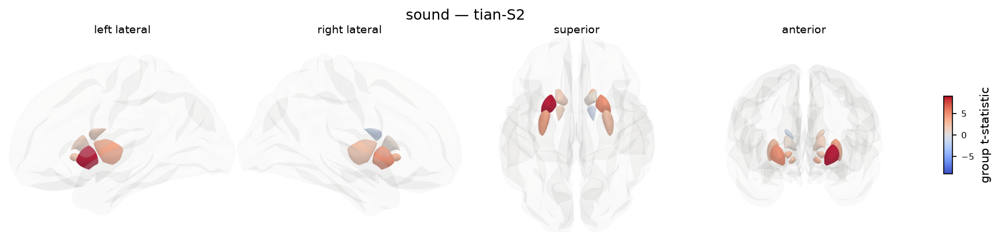

In [82]:
# yabplot 3D rendering of the same stat_dict, as an alternative to the
# 2D contour schematic above. See 05_masking/build_yabplot_tian_s2_atlas.py
# for building the atlas this depends on.
from striatal_yabplot import plot_striatal_roi_stat_yabplot

yabplot_out_png = os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_striatal-tstat_yabplot.png')
yabplot_atlas_dir = os.path.join(os.getcwd(), '..', '05_masking', 'yabplot_atlases', 'tian_S2')

fig = plot_striatal_roi_stat_yabplot(stat_dict, atlas_dir=yabplot_atlas_dir,
                                      title=f'{contrast_label} — {network_name}')
fig.savefig(yabplot_out_png)

In [83]:
#from IPython.display import Image
#Image(filename=yabplot_out_png)


### Striatal ROI plot (t-statistic, final vs. early)

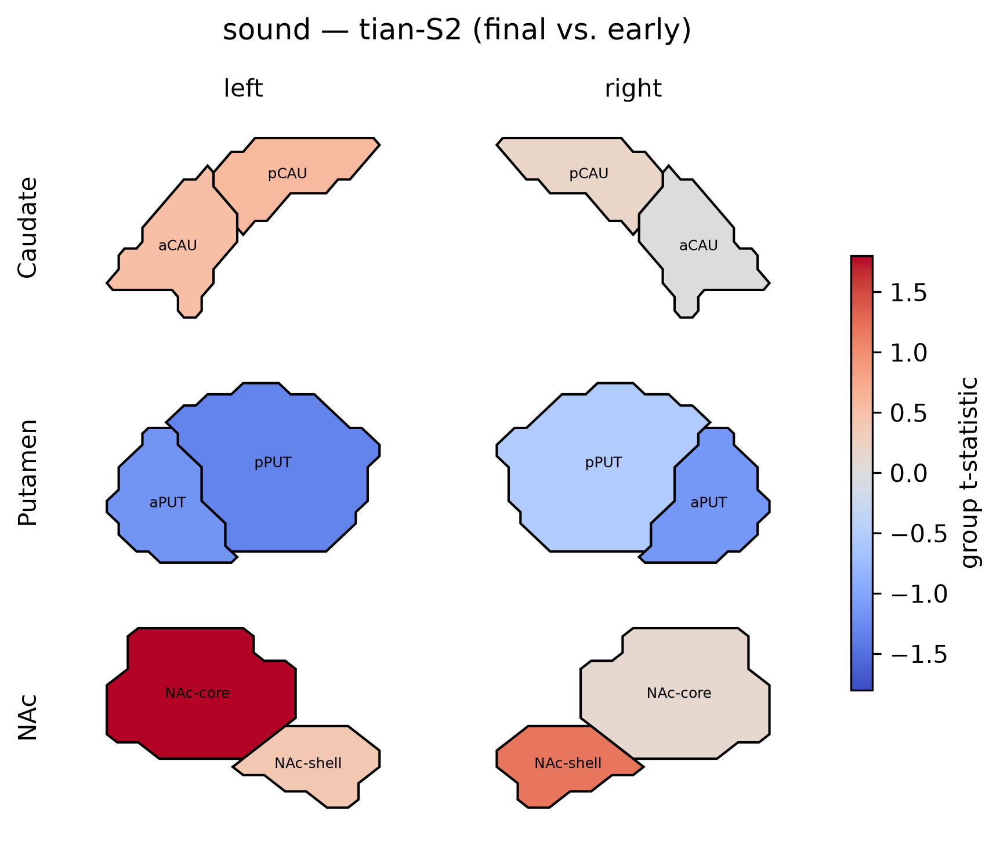

In [84]:
# Learning-stage difference (final vs. early)
_diff_df = (group_df[group_df['learning_stage'].isin(['early', 'final'])]
            .groupby(['participant_id', 'region_hemi', 'learning_stage'], as_index=False)['beta'].mean()
            .pivot(index=['participant_id', 'region_hemi'], columns='learning_stage', values='beta')
            .dropna()
            .reset_index())

diff_stat_dict = {}
for region_hemi, data in _diff_df.groupby('region_hemi'):
    t_stat, _ = ttest_rel(data['final'], data['early'])
    diff_stat_dict[region_hemi] = t_stat

structure_groups = {
    'Caudate': ['aCAU', 'pCAU'],
    'Putamen': ['aPUT', 'pPUT'],
    'NAc': ['NAc-core', 'NAc-shell'],
}
mask_path_dict_diff = build_mask_path_dict(list(diff_stat_dict.keys()), masks_dir, network_name, surf_space_label)
fig_diff = plot_striatal_roi_stat(diff_stat_dict, mask_path_dict_diff, structure_groups,
                                   title=f'{contrast_label} — {network_name} (final vs. early)')
fig_diff.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_striatal-tstat_diff-final-early.svg'))
fig_diff.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_striatal-tstat_diff-final-early.png'))


### Striatal ROI plot (t-statistic, final vs. early) — yabplot alternative

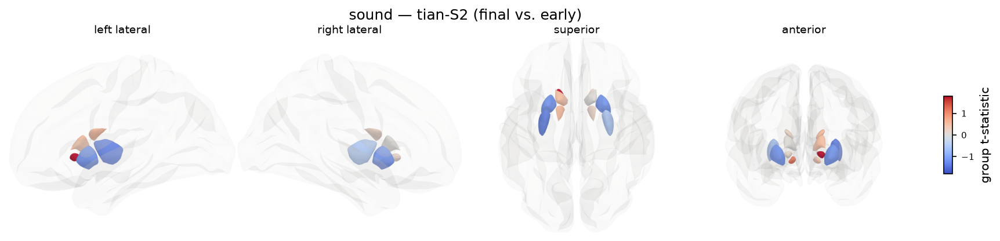

In [85]:
# yabplot 3D rendering of diff_stat_dict (final vs. early).
from striatal_yabplot import plot_striatal_roi_stat_yabplot

yabplot_out_png_diff = os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_striatal-tstat_diff-final-early_yabplot.png')
yabplot_atlas_dir = os.path.join(os.getcwd(), '..', '05_masking', 'yabplot_atlases', 'tian_S2')

fig = plot_striatal_roi_stat_yabplot(diff_stat_dict, atlas_dir=yabplot_atlas_dir,
                                      title=f'{contrast_label} — {network_name} (final vs. early)')
fig.savefig(yabplot_out_png_diff)

In [86]:
#from IPython.display import Image
#Image(filename=yabplot_out_png_diff)


## `contrast-sound` for cortical network

In [87]:
# get the beta map for the contrast of interest for each subject
network_name = network_list[0]
contrast_label = contrast_list[0]
event_type = contrast_event_type[contrast_label]
print('network_name:', network_name)
print('contrast_label:', contrast_label)

network_name: auditory
contrast_label: sound


In [88]:
# per-group copy of the ROI table that the cells below (and robustness_checks.py) read
out_fname = f'univariate-results_network-{network_name}_contrast-{contrast_label}{group_suffix}.tsv'
combined_roi_df_fpath = os.path.join(group_out_dir, out_fname)

In [89]:
# this group's per-ROI values (from extract_roi_values.py), saved under the
# name the cells below and robustness_checks.py read
roi_df_long = load_roi_values(network_name, contrast_label)
roi_df_long.to_csv(combined_roi_df_fpath, sep='\t', index=False)
roi_df_long.groupby('learning_stage').participant_id.nunique()

learning_stage
early     13
final     13
middle    13
Name: participant_id, dtype: int64

In [90]:
# load the DataFrame if already exists
roi_df_long = pd.read_csv(combined_roi_df_fpath, sep='\t')

# create a bilateral-averaged dataframe (for across-contrast analysis)
sound_cortex_df = bilateral_mean(roi_df_long)


In [91]:
roi_df_long.participant_id.unique()

<StringArray>
['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17',
 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24',
 'sub-FLT26']
Length: 13, dtype: str

In [92]:
roi_df_long.region.unique()

<StringArray>
['HG', 'PT', 'PP', 'STGp', 'STGa', 'ParsOp', 'ParsTri']
Length: 7, dtype: str

In [93]:
group_df = roi_df_long

In [94]:
# right now, requires separate dictionaries per learning stage
# could be re-written to take roi_df_long or similar
'''fig = plot_roi_slices_avg([roi_earlythird_mean_dict, roi_middlethird_mean_dict, roi_latethird_mean_dict],
                          mask_path_list, 'dseg', space_label)
'''

"fig = plot_roi_slices_avg([roi_earlythird_mean_dict, roi_middlethird_mean_dict, roi_latethird_mean_dict],\n                          mask_path_list, 'dseg', space_label)\n"

In [95]:
plot_order = ['HG', 'PT', 'PP', 'STGp', 'STGa', 'ParsOp', 'ParsTri', ]

/scratch/slurm-12192413/ipykernel_2562235/276266010.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')


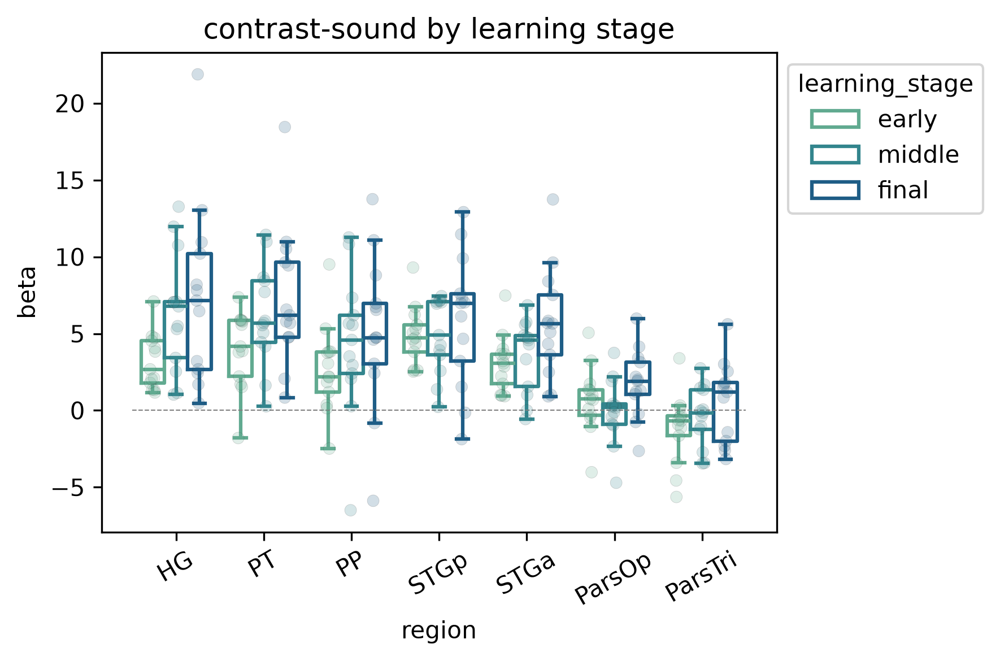

In [96]:
fig, ax = plt.subplots(1, 1, figsize=(6,4), dpi=300)

roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'learning_stage'], 
                                       as_index=False).agg({"beta": "mean"})

sns.boxplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='learning_stage', hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              fliersize = 0,            
              linewidth=1.5,
              fill=False,
              #legend=None,
              ax=ax);
sns.stripplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='learning_stage', hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              dodge=True,
              linewidth=0.2,
              alpha=.2,
              legend=None,
              ax=ax);


xmin, xmax = ax.get_xlim()
ax.hlines(y=0, xmin=xmin, xmax=xmax, color='0.5', linestyle='--', linewidth=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f'contrast-{contrast_label} by learning stage');
#ax.set_ylim([-5, 5])

fig.tight_layout()

fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-stage.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-stage.png'))

/scratch/slurm-12192413/ipykernel_2562235/3292222178.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')


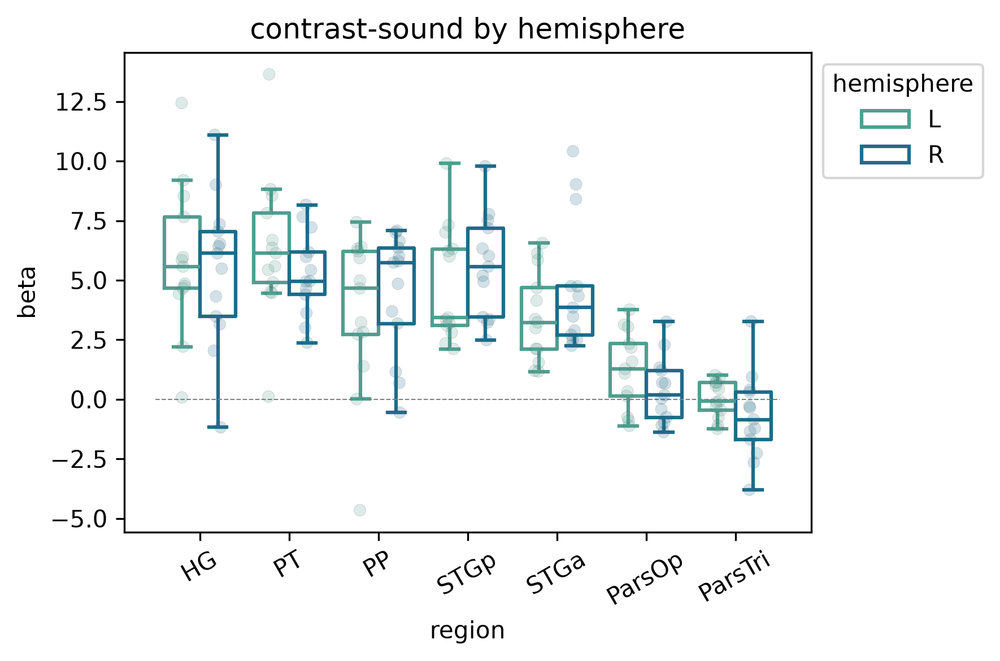

In [97]:
fig, ax = plt.subplots(1, 1, figsize=(6,4), dpi=300)

roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'hemisphere'], 
                                       as_index=False).agg({"beta": "mean"})

sns.boxplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='hemisphere', #hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              fliersize = 0,            
              linewidth=1.5,
              fill=False,
              #legend=None,
              ax=ax);
sns.stripplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='hemisphere', #hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              dodge=True,
              linewidth=0.2,
              alpha=.2,
              legend=None,
              ax=ax);


xmin, xmax = ax.get_xlim()
ax.hlines(y=0, xmin=xmin, xmax=xmax, color='0.5', linestyle='--', linewidth=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f'contrast-{contrast_label} by hemisphere');
#ax.set_ylim([-5, 5])

fig.tight_layout()

fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-hemisphere.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-hemisphere.png'))

### Brain-behavior correlations

In [98]:
# map runs to learning stages matching your thirds
stage_map = {'run-01': 'early', 'run-02': 'early',
             'run-03': 'middle', 'run-04': 'middle',
             'run-05': 'final', 'run-06': 'final'}

acc_df['learning_stage'] = acc_df['run'].map(stage_map)
acc_stage_df = acc_df.groupby(['participant_id', 'learning_stage'])['accuracy'].mean().reset_index()

In [99]:
# merge into roi_df_long — assumes participant_id and learning_stage columns exist in both
roi_df_bilateral = (roi_df_long.groupby(['participant_id', 'region', 'learning_stage'], as_index=False)['beta'].mean())
roi_behav_df = roi_df_bilateral.merge(acc_stage_df, on=['participant_id', 'learning_stage'])

# verify
roi_behav_df.groupby(['region', 'learning_stage']).size().unique()  # should be one row per participant


array([13])

In [100]:
roi_behav_df.columns

Index(['participant_id', 'region', 'learning_stage', 'beta', 'accuracy'], dtype='str')

In [101]:
roi_behav_df.participant_id.unique()

<StringArray>
['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17',
 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24',
 'sub-FLT26']
Length: 13, dtype: str

In [102]:
results = []
for stage in ['early', 'middle', 'final']:
    stage_df = roi_behav_df[roi_behav_df['learning_stage'] == stage]
    for roi in plot_order: # stage_df['region'].unique():
        sub_df = stage_df[stage_df['region'] == roi]
        r = pg.corr(sub_df['accuracy'], sub_df['beta'], method='pearson')
        results.append({
            'roi': roi,
            'learning_stage': stage,
            'r': r['r'].values[0],
            'p': r['p_val'].values[0],
            'n': r['n'].values[0],
            'stat_str': stat_str('r', r['r'].values[0], r['p_val'].values[0])
        })

behav_corr_df = pd.DataFrame(results)

In [103]:
behav_corr_df

,roi,learning_stage,r,p,n,stat_str
0,HG,early,-0.0367,0.9053,13,"r = -.04, p = .905"
1,PT,early,-0.0958,0.7555,13,"r = -.10, p = .756"
2,PP,early,-0.0806,0.7935,13,"r = -.08, p = .794"
3,STGp,early,0.0748,0.8082,13,"r = .07, p = .808"
4,STGa,early,0.1971,0.5187,13,"r = .20, p = .519"
5,ParsOp,early,-0.1049,0.7330,13,"r = -.10, p = .733"
6,ParsTri,early,0.0097,0.9749,13,"r = .01, p = .975"
7,HG,middle,0.2688,0.3746,13,"r = .27, p = .375"
8,PT,middle,0.1462,0.6335,13,"r = .15, p = .634"
9,PP,middle,0.2806,0.3530,13,"r = .28, p = .353"


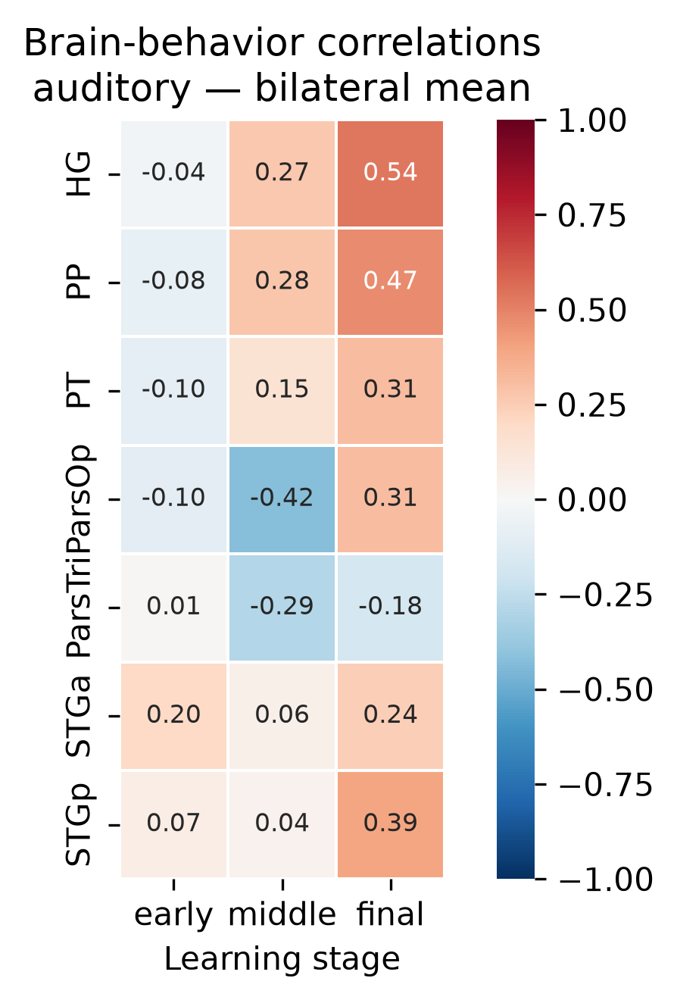

In [104]:
# pivot to ROI × stage matrix
r_matrix = behav_corr_df.pivot(index='roi', columns='learning_stage', values='r')[['early', 'middle', 'final']]
p_matrix = behav_corr_df.pivot(index='roi', columns='learning_stage', values='p')[['early', 'middle', 'final']]

fig, ax = plt.subplots(figsize=(5, len(r_matrix) * 0.5 + 1), dpi=300)
sns.heatmap(r_matrix, ax=ax, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot=True, fmt='.2f', annot_kws={'size': 8},
            square=True)

# mark significant cells with an asterisk
for i, roi in enumerate(r_matrix.index):
    for j, stage in enumerate(['early', 'middle', 'final']):
        p = p_matrix.loc[roi, stage]
        if p < 0.05:
            ax.text(j + 0.5, i + 0.85, '*', ha='center', va='center',
                    fontsize=12, color='black')

ax.set_title(f'Brain-behavior correlations\n{network_name} — bilateral mean')
ax.set_ylabel('')
ax.set_xlabel('Learning stage')
plt.tight_layout()
plt.savefig(os.path.join(fig_out_dir, f'brain-behav-corr_contrast-{contrast_label}_network-{network_name}_heatmap.svg'))

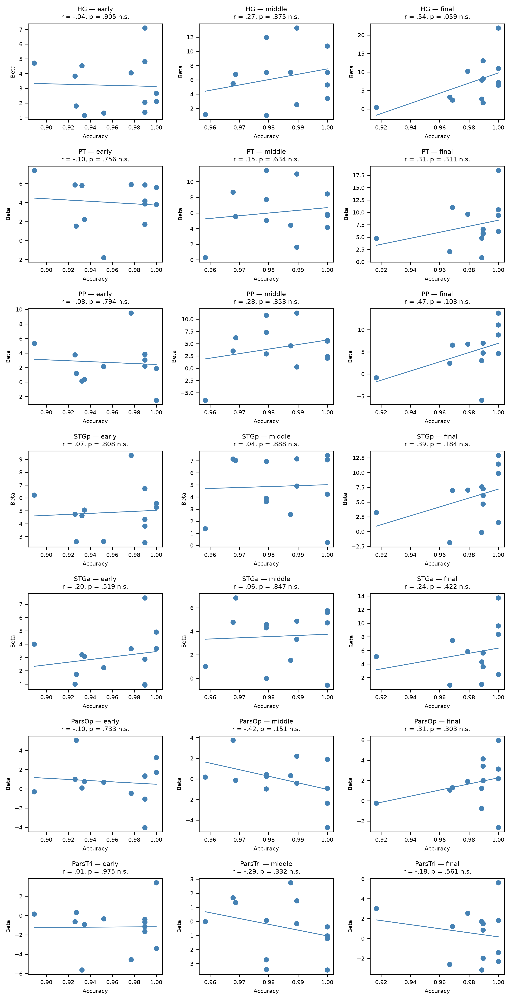

In [105]:
rois = behav_corr_df['roi'].unique()
stages = ['early', 'middle', 'final']

fig, axes = plt.subplots(len(rois), 3, figsize=(9, len(rois) * 2.5), dpi=300, sharex=False, sharey=False)

for ri, roi in enumerate(plot_order): # rois):
    for si, stage in enumerate(stages):
        ax = axes[ri, si]
        sub_df = roi_behav_df[(roi_behav_df['region'] == roi) & 
                              (roi_behav_df['learning_stage'] == stage)]
        
        ax.scatter(sub_df['accuracy'], sub_df['beta'], s=30, color='steelblue', zorder=3)
        
        # regression line
        m, b = np.polyfit(sub_df['accuracy'], sub_df['beta'], 1)
        x_range = np.linspace(sub_df['accuracy'].min(), sub_df['accuracy'].max(), 100)
        ax.plot(x_range, m * x_range + b, color='steelblue', linewidth=1)
        
        # stat annotation
        row = behav_corr_df[(behav_corr_df['roi'] == roi) & 
                            (behav_corr_df['learning_stage'] == stage)].iloc[0]
        p_str = '*' if row['p'] < 0.05 else 'n.s.'
        ax.set_title(f"{roi} — {stage}\n{row['stat_str']} {p_str}", fontsize=8)
        ax.set_xlabel('Accuracy', fontsize=7)
        ax.set_ylabel('Beta', fontsize=7)
        ax.tick_params(labelsize=7)

plt.tight_layout()
plt.savefig(os.path.join(fig_out_dir, f'brain-behav-corr_contrast-{contrast_label}_network-{network_name}_corr-plots.svg'))

HG early: r = -.04, p = .905 n.s.
HG middle: r = .27, p = .375 n.s.
HG final: r = .54, p = .059 n.s.
PT early: r = -.10, p = .756 n.s.
PT middle: r = .15, p = .634 n.s.
PT final: r = .31, p = .311 n.s.
PP early: r = -.08, p = .794 n.s.
PP middle: r = .28, p = .353 n.s.
PP final: r = .47, p = .103 n.s.
STGp early: r = .07, p = .808 n.s.
STGp middle: r = .04, p = .888 n.s.
STGp final: r = .39, p = .184 n.s.
STGa early: r = .20, p = .519 n.s.
STGa middle: r = .06, p = .847 n.s.
STGa final: r = .24, p = .422 n.s.
ParsOp early: r = -.10, p = .733 n.s.
ParsOp middle: r = -.42, p = .151 n.s.
ParsOp final: r = .31, p = .303 n.s.
ParsTri early: r = .01, p = .975 n.s.
ParsTri middle: r = -.29, p = .332 n.s.
ParsTri final: r = -.18, p = .561 n.s.


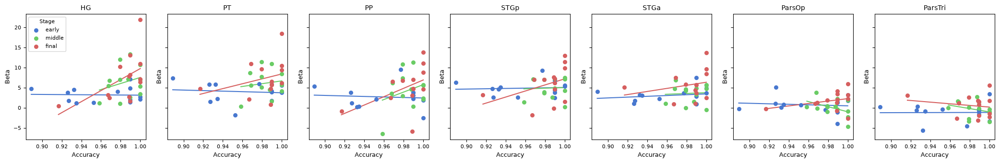

In [106]:
stage_colors = {'early': '#4878CF', 'middle': '#6ACC65', 'final': '#D65F5F'}
stages = ['early', 'middle', 'final']
rois = behav_corr_df['roi'].unique()

fig, axes = plt.subplots(1, len(rois), figsize=(3 * len(rois), 3.5), dpi=100, sharey=True)
if len(rois) == 1:
    axes = [axes]

for ri, roi in enumerate(plot_order): # rois):
    ax = axes[ri]
    for stage in stages:
        color = stage_colors[stage]
        sub_df = roi_behav_df[(roi_behav_df['region'] == roi) &
                              (roi_behav_df['learning_stage'] == stage)]

        ax.scatter(sub_df['accuracy'], sub_df['beta'], s=30,
                   color=color, label=stage, zorder=3)

        m, b = np.polyfit(sub_df['accuracy'], sub_df['beta'], 1)
        x_range = np.linspace(sub_df['accuracy'].min(), sub_df['accuracy'].max(), 100)
        ax.plot(x_range, m * x_range + b, color=color, linewidth=1.5)

        # stat annotation per stage
        row = behav_corr_df[(behav_corr_df['roi'] == roi) &
                            (behav_corr_df['learning_stage'] == stage)].iloc[0]
        p_str = '*' if row['p'] < 0.05 else 'n.s.'
        print(f"{roi} {stage}: {row['stat_str']} {p_str}")

    ax.set_title(roi, fontsize=10)
    ax.set_xlabel('Accuracy', fontsize=9)
    ax.set_ylabel('Beta', fontsize=9)
    ax.tick_params(labelsize=8)

axes[0].legend(title='Stage', fontsize=8, title_fontsize=8)
plt.tight_layout()


### omnibus ANOVA stats

In [107]:
# Mixed-Effects ANOVA with Hemisphere, Region, and Interaction
aov = AnovaRM(group_df, 
              aggregate_func='mean',
              depvar='beta', 
              subject='participant_id', 
              within=['hemisphere', 'learning_stage','region', ]).fit()

# Display results
print('network:', network_name)
print('contrast:', contrast_label)
print(aov)


network: auditory
contrast: sound
                             Anova
                                 F Value  Num DF  Den DF  Pr > F
----------------------------------------------------------------
hemisphere                        0.0432  1.0000  12.0000 0.8389
learning_stage                    3.3815  2.0000  24.0000 0.0508
region                           33.2438  6.0000  72.0000 0.0000
hemisphere:learning_stage         0.1463  2.0000  24.0000 0.8647
hemisphere:region                 1.8894  6.0000  72.0000 0.0943
learning_stage:region             1.4496 12.0000 144.0000 0.1502
hemisphere:learning_stage:region  0.8387 12.0000 144.0000 0.6106



In [108]:
export_anova(aov, f'{contrast_label}_{network_name}_hemisphere_learning-stage_region', stats_out_dir)

,source,F,df_num,df_den,p,stat_str
0,hemisphere,0.04,1.0000,12.0000,p = .839,"F(1, 12) = 0.04, p = .839"
1,learning_stage,3.38,2.0000,24.0000,p = .051,"F(2, 24) = 3.38, p = .051"
2,region,33.24,6.0000,72.0000,p < .001,"F(6, 72) = 33.24, p < .001"
3,hemisphere:learning_stage,0.15,2.0000,24.0000,p = .865,"F(2, 24) = 0.15, p = .865"
4,hemisphere:region,1.89,6.0000,72.0000,p = .094,"F(6, 72) = 1.89, p = .094"
5,learning_stage:region,1.45,12.0000,144.0000,p = .150,"F(12, 144) = 1.45, p = .150"
6,hemisphere:learning_stage:region,0.84,12.0000,144.0000,p = .611,"F(12, 144) = 0.84, p = .611"


In [109]:
# GG-corrected bilateral replication (learning_stage x region)
bilateral_df = (group_df
                .groupby(['participant_id', 'region', 'learning_stage'], as_index=False)['beta']
                .mean())
aov_pg = pg.rm_anova(data=bilateral_df, dv='beta',
                     within=['learning_stage', 'region'],
                     subject='participant_id',
                     detailed=True)
eta_col = 'np2' if 'np2' in aov_pg.columns else 'ng2'
print(aov_pg[['Source', 'F', 'ddof1', 'ddof2', 'p_unc', 'p_GG_corr', eta_col]])
export_pg_anova(aov_pg, f'{contrast_label}_{network_name}_learning-stage_region_bilateral', stats_out_dir)

                    Source       F  ddof1  ddof2  p_unc  p_GG_corr    ng2
0           learning_stage  3.3815      2     24 0.0508     0.0684 0.0853
1                   region 33.2438      6     72 0.0000     0.0000 0.3410
2  learning_stage * region  1.4496     12    144 0.1502     0.2493 0.0322


/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/pingouin/distribution.py:514: UserWarning: Epsilon values might be innaccurate in two-way repeated measures design where each  factor has more than 2 levels. Please  double-check your results.
  warnings.warn(


,source,df_num,df_den,F,p_unc,p_GG_corr,eta_p2,stat_str
0,learning_stage,2,24,3.38,p = .051,p = .068,0.09,"F(2, 24) = 3.38, p = .068"
1,region,6,72,33.24,p < .001,p < .001,0.34,"F(6, 72) = 33.24, p < .001"
2,learning_stage * region,12,144,1.45,p = .150,p = .249,0.03,"F(12, 144) = 1.45, p = .249"


In [110]:
aov.summary().tables[0]

,F Value,Num DF,Den DF,Pr > F
hemisphere,0.0432,1.0000,12.0000,0.8389
learning_stage,3.3815,2.0000,24.0000,0.0508
region,33.2438,6.0000,72.0000,0.0000
hemisphere:learning_stage,0.1463,2.0000,24.0000,0.8647
hemisphere:region,1.8894,6.0000,72.0000,0.0943
learning_stage:region,1.4496,12.0000,144.0000,0.1502
hemisphere:learning_stage:region,0.8387,12.0000,144.0000,0.6106


In [111]:
import pingouin as pg

# Pairwise comparisons for region with FDR correction
pairwise_by_learning_stage = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['hemisphere','region', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_learning_stage.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_learning_stage)
#pairwise_by_learning_stage[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_learning_stage[pairwise_by_learning_stage.Contrast.str.contains(' * ')].reset_index()
pairwise_interaction = pairwise_interaction[pairwise_interaction['p_corr'] < 0.05].reset_index()
pairwise_interaction[['Contrast', 'hemisphere', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'hemisphere', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof',
       'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,hemisphere,A,B,T,dof,p_unc,p_corr,BF10
0,hemisphere * region,L,HG,PP,2.6127,12.0000,0.0227,0.0381,2.994
1,hemisphere * region,L,HG,ParsOp,4.9108,12.0000,0.0004,0.0012,95.168
2,hemisphere * region,L,HG,ParsTri,6.9920,12.0000,0.0000,0.0001,1570.856
3,hemisphere * region,L,HG,STGa,3.5661,12.0000,0.0039,0.0078,12.645
4,hemisphere * region,L,PP,PT,-3.2003,12.0000,0.0076,0.0139,7.23
5,hemisphere * region,L,PP,ParsTri,3.7625,12.0000,0.0027,0.0060,17.074
6,hemisphere * region,L,PT,ParsOp,7.7755,12.0000,0.0000,0.0000,4019.51
7,hemisphere * region,L,PT,ParsTri,8.1584,12.0000,0.0000,0.0000,6225.353
8,hemisphere * region,L,PT,STGa,4.1120,12.0000,0.0014,0.0034,29.053
9,hemisphere * region,L,ParsOp,ParsTri,3.3176,12.0000,0.0061,0.0117,8.646


In [112]:
# pairwise by region

# Pairwise comparisons for region with FDR correction
pairwise_by_region = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['region', 'hemisphere',],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_region.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_region)
#pairwise_by_region[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_region[pairwise_by_region.Contrast.str.contains(' * ')].reset_index()
#pairwise_interaction = pairwise_interaction[pairwise_interaction['p_unc'] < 0.05]
pairwise_interaction[['Contrast', 'region', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'region', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof',
       'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,region,A,B,T,dof,p_unc,p_corr,BF10
0,region * hemisphere,HG,L,R,0.5714,12.0000,0.5783,0.5783,0.321
1,region * hemisphere,PP,L,R,-0.9522,12.0000,0.3598,0.4197,0.409
2,region * hemisphere,PT,L,R,1.3811,12.0000,0.1924,0.3367,0.606
3,region * hemisphere,ParsOp,L,R,1.4293,12.0000,0.1784,0.3367,0.638
4,region * hemisphere,ParsTri,L,R,1.4555,12.0000,0.1712,0.3367,0.656
5,region * hemisphere,STGa,L,R,-2.0702,12.0000,0.0607,0.3367,1.393
6,region * hemisphere,STGp,L,R,-1.2215,12.0000,0.2454,0.3435,0.516


In [113]:
export_posthoc(pairwise_by_region, f'{contrast_label}_{network_name}_region_hemisphere', stats_out_dir)

,Contrast,region,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,region,-,HG,PP,2.96,12.0000,p = .012,p = .017,"t(12) = 2.96, p = .012","t(12) = 2.96, q = .017"
1,region,-,HG,PT,-0.34,12.0000,p = .738,p = .775,"t(12) = -0.34, p = .738","t(12) = -0.34, q = .775"
2,region,-,HG,ParsOp,5.35,12.0000,p < .001,p < .001,"t(12) = 5.35, p < .001","t(12) = 5.35, q < .001"
3,region,-,HG,ParsTri,7.94,12.0000,p < .001,p < .001,"t(12) = 7.94, p < .001","t(12) = 7.94, q < .001"
4,region,-,HG,STGa,2.55,12.0000,p = .025,p = .033,"t(12) = 2.55, p = .025","t(12) = 2.55, q = .033"
5,region,-,HG,STGp,0.61,12.0000,p = .555,p = .614,"t(12) = 0.61, p = .555","t(12) = 0.61, q = .614"
6,region,-,PP,PT,-3.75,12.0000,p = .003,p = .005,"t(12) = -3.75, p = .003","t(12) = -3.75, q = .005"
7,region,-,PP,ParsOp,3.89,12.0000,p = .002,p = .004,"t(12) = 3.89, p = .002","t(12) = 3.89, q = .004"
8,region,-,PP,ParsTri,6.10,12.0000,p < .001,p < .001,"t(12) = 6.10, p < .001","t(12) = 6.10, q < .001"
9,region,-,PP,STGa,-0.11,12.0000,p = .913,p = .913,"t(12) = -0.11, p = .913","t(12) = -0.11, q = .913"


In [114]:

# Pairwise comparisons for region with FDR correction
pairwise_by_learning_stage = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['hemisphere','learning_stage', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_learning_stage.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_learning_stage)
#pairwise_by_learning_stage[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_learning_stage[pairwise_by_learning_stage.Contrast.str.contains(' * ')].reset_index()
#pairwise_interaction = pairwise_interaction[pairwise_interaction['p_corr'] < 0.05].reset_index()
pairwise_interaction[['Contrast', 'hemisphere', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'hemisphere', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof',
       'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,hemisphere,A,B,T,dof,p_unc,p_corr,BF10
0,hemisphere * learning_stage,L,early,final,-2.9428,12.0000,0.0123,0.0738,4.893
1,hemisphere * learning_stage,L,early,middle,-1.5561,12.0000,0.1457,0.2250,0.734
2,hemisphere * learning_stage,L,final,middle,1.1837,12.0000,0.2595,0.3113,0.498
3,hemisphere * learning_stage,R,early,final,-2.0014,12.0000,0.0685,0.2055,1.271
4,hemisphere * learning_stage,R,early,middle,-1.5379,12.0000,0.1500,0.2250,0.719
5,hemisphere * learning_stage,R,final,middle,0.9753,12.0000,0.3487,0.3487,0.416


In [115]:
export_posthoc(pairwise_by_learning_stage, f'{contrast_label}_{network_name}_hemisphere_learning-stage', stats_out_dir)

,Contrast,hemisphere,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,hemisphere,-,L,R,0.21,12.0000,p = .839,p = nan,"t(12) = 0.21, p = .839","t(12) = 0.21, q = nan"
1,learning_stage,-,early,final,-2.67,12.0000,p = .021,p = .062,"t(12) = -2.67, p = .021","t(12) = -2.67, q = .062"
2,learning_stage,-,early,middle,-1.66,12.0000,p = .122,p = .184,"t(12) = -1.66, p = .122","t(12) = -1.66, q = .184"
3,learning_stage,-,final,middle,1.13,12.0000,p = .280,p = .280,"t(12) = 1.13, p = .280","t(12) = 1.13, q = .280"
4,hemisphere * learning_stage,L,early,final,-2.94,12.0000,p = .012,p = .074,"t(12) = -2.94, p = .012","t(12) = -2.94, q = .074"
5,hemisphere * learning_stage,L,early,middle,-1.56,12.0000,p = .146,p = .225,"t(12) = -1.56, p = .146","t(12) = -1.56, q = .225"
6,hemisphere * learning_stage,L,final,middle,1.18,12.0000,p = .259,p = .311,"t(12) = 1.18, p = .259","t(12) = 1.18, q = .311"
7,hemisphere * learning_stage,R,early,final,-2.00,12.0000,p = .068,p = .205,"t(12) = -2.00, p = .068","t(12) = -2.00, q = .205"
8,hemisphere * learning_stage,R,early,middle,-1.54,12.0000,p = .150,p = .225,"t(12) = -1.54, p = .150","t(12) = -1.54, q = .225"
9,hemisphere * learning_stage,R,final,middle,0.98,12.0000,p = .349,p = .349,"t(12) = 0.98, p = .349","t(12) = 0.98, q = .349"


In [116]:

# Pairwise comparisons for region with FDR correction
pairwise_by_learning_stage = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['learning_stage','hemisphere', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_learning_stage.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_learning_stage)
#pairwise_by_learning_stage[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_learning_stage[pairwise_by_learning_stage.Contrast.str.contains(' * ')].reset_index()
#pairwise_interaction = pairwise_interaction[pairwise_interaction['p_corr'] < 0.05].reset_index()
pairwise_interaction[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'learning_stage', 'A', 'B', 'Paired', 'Parametric', 'T',
       'dof', 'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,learning_stage,A,B,T,dof,p_unc,p_corr,BF10
0,learning_stage * hemisphere,early,L,R,-0.2149,12.0000,0.8335,0.9215,0.284
1,learning_stage * hemisphere,final,L,R,0.4484,12.0000,0.6618,0.9215,0.304
2,learning_stage * hemisphere,middle,L,R,-0.1006,12.0000,0.9215,0.9215,0.279


In [117]:
export_posthoc(pairwise_by_learning_stage, f'{contrast_label}_{network_name}_learning-stage_hemisphere', stats_out_dir)

,Contrast,learning_stage,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,learning_stage,-,early,final,-2.67,12.0000,p = .021,p = .062,"t(12) = -2.67, p = .021","t(12) = -2.67, q = .062"
1,learning_stage,-,early,middle,-1.66,12.0000,p = .122,p = .184,"t(12) = -1.66, p = .122","t(12) = -1.66, q = .184"
2,learning_stage,-,final,middle,1.13,12.0000,p = .280,p = .280,"t(12) = 1.13, p = .280","t(12) = 1.13, q = .280"
3,hemisphere,-,L,R,0.21,12.0000,p = .839,p = nan,"t(12) = 0.21, p = .839","t(12) = 0.21, q = nan"
4,learning_stage * hemisphere,early,L,R,-0.21,12.0000,p = .833,p = .921,"t(12) = -0.21, p = .833","t(12) = -0.21, q = .921"
5,learning_stage * hemisphere,final,L,R,0.45,12.0000,p = .662,p = .921,"t(12) = 0.45, p = .662","t(12) = 0.45, q = .921"
6,learning_stage * hemisphere,middle,L,R,-0.10,12.0000,p = .921,p = .921,"t(12) = -0.10, p = .921","t(12) = -0.10, q = .921"


In [118]:
# pairwise by region, no learning stage

# Pairwise comparisons for region with FDR correction
pairwise_by_region_only = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['region', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_region_only.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_region_only)
pairwise_by_region_only = pairwise_by_region_only[pairwise_by_region_only['p_unc'] < 0.05]
pairwise_by_region_only[['Contrast', 'Contrast', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns


Available columns: Index(['Contrast', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof', 'alternative',
       'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,Contrast,A,B,T,dof,p_unc,p_corr,BF10
0,region,region,HG,PP,2.9566,12.0000,0.0120,0.0168,4.996
2,region,region,HG,ParsOp,5.3533,12.0000,0.0002,0.0004,179.304
3,region,region,HG,ParsTri,7.9423,12.0000,0.0000,0.0000,4871.419
4,region,region,HG,STGa,2.5523,12.0000,0.0254,0.0333,2.741
6,region,region,PP,PT,-3.7530,12.0000,0.0028,0.0048,16.828
7,region,region,PP,ParsOp,3.8856,12.0000,0.0022,0.0044,20.602
8,region,region,PP,ParsTri,6.0988,12.0000,0.0001,0.0002,498.4
11,region,region,PT,ParsOp,8.4432,12.0000,0.0000,0.0000,8543.825
12,region,region,PT,ParsTri,12.4182,12.0000,0.0000,0.0000,3.664e+05
13,region,region,PT,STGa,3.8559,12.0000,0.0023,0.0044,19.688


In [119]:
export_posthoc(pairwise_by_region_only, f'{contrast_label}_{network_name}_region', stats_out_dir)

,Contrast,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,region,HG,PP,2.96,12.0000,p = .012,p = .017,"t(12) = 2.96, p = .012","t(12) = 2.96, q = .017"
2,region,HG,ParsOp,5.35,12.0000,p < .001,p < .001,"t(12) = 5.35, p < .001","t(12) = 5.35, q < .001"
3,region,HG,ParsTri,7.94,12.0000,p < .001,p < .001,"t(12) = 7.94, p < .001","t(12) = 7.94, q < .001"
4,region,HG,STGa,2.55,12.0000,p = .025,p = .033,"t(12) = 2.55, p = .025","t(12) = 2.55, q = .033"
6,region,PP,PT,-3.75,12.0000,p = .003,p = .005,"t(12) = -3.75, p = .003","t(12) = -3.75, q = .005"
7,region,PP,ParsOp,3.89,12.0000,p = .002,p = .004,"t(12) = 3.89, p = .002","t(12) = 3.89, q = .004"
8,region,PP,ParsTri,6.10,12.0000,p < .001,p < .001,"t(12) = 6.10, p < .001","t(12) = 6.10, q < .001"
11,region,PT,ParsOp,8.44,12.0000,p < .001,p < .001,"t(12) = 8.44, p < .001","t(12) = 8.44, q < .001"
12,region,PT,ParsTri,12.42,12.0000,p < .001,p < .001,"t(12) = 12.42, p < .001","t(12) = 12.42, q < .001"
13,region,PT,STGa,3.86,12.0000,p = .002,p = .004,"t(12) = 3.86, p = .002","t(12) = 3.86, q = .004"


### Collapse (average) over non-significant factors

In [120]:
roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'hemisphere'], 
                                       as_index=False).agg({"beta": "mean"})


In [121]:
roi_df_collapsed.head()

,participant_id,region,hemisphere,beta
0,sub-FLT03,HG,L,4.8509
1,sub-FLT03,HG,R,7.0467
2,sub-FLT03,PP,L,6.3168
3,sub-FLT03,PP,R,4.8490
4,sub-FLT03,PT,L,5.4352


In [122]:
# Collect results
results = []

for (region, hemi), data in roi_df_collapsed.groupby(["region", "hemisphere"]):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    results.append({
        "region": region,
        "hemisphere": hemi,
        "t_stat": t_stat,
        "p_val": p_val
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Apply FDR correction
results_df["p_val_fdr"] = multipletests(results_df["p_val"], method="fdr_bh")[1]

# Print or export the table
results_df

# Optional: export
# results_df.to_csv("roi_stats.csv", index=False)
# results_df.to_excel("roi_stats.xlsx", index=False)


,region,hemisphere,t_stat,p_val,p_val_fdr
0,HG,L,6.7573,0.0000,0.0001
1,HG,R,6.2361,0.0000,0.0001
2,PP,L,3.9573,0.0019,0.0027
3,PP,R,6.1880,0.0000,0.0001
4,PT,L,7.4146,0.0000,0.0000
5,PT,R,10.8607,0.0000,0.0000
6,ParsOp,L,2.7561,0.0174,0.0222
7,ParsOp,R,1.0128,0.3311,0.3566
8,ParsTri,L,0.1033,0.9194,0.9194
9,ParsTri,R,-1.4778,0.1652,0.1928


In [123]:
_export = results_df.rename(columns={'t_stat': 't', 'p_val': 'p'}).copy()
_export['df'] = len(sub_list) - 1
export_ttests(_export.to_dict('records'), f'{contrast_label}_{network_name}_baseline_by_region_hemi', stats_out_dir)

,region,hemisphere,t,p,p_val_fdr,df,p_fdr,stat_str,stat_str_fdr
0,HG,L,6.76,p < .001,0.0001,12,p < .001,"t(12) = 6.76, p < .001","t(12) = 6.76, q < .001"
1,HG,R,6.24,p < .001,0.0001,12,p < .001,"t(12) = 6.24, p < .001","t(12) = 6.24, q < .001"
2,PP,L,3.96,p = .002,0.0027,12,p = .003,"t(12) = 3.96, p = .002","t(12) = 3.96, q = .003"
3,PP,R,6.19,p < .001,0.0001,12,p < .001,"t(12) = 6.19, p < .001","t(12) = 6.19, q < .001"
4,PT,L,7.41,p < .001,0.0000,12,p < .001,"t(12) = 7.41, p < .001","t(12) = 7.41, q < .001"
5,PT,R,10.86,p < .001,0.0000,12,p < .001,"t(12) = 10.86, p < .001","t(12) = 10.86, q < .001"
6,ParsOp,L,2.76,p = .017,0.0222,12,p = .022,"t(12) = 2.76, p = .017","t(12) = 2.76, q = .022"
7,ParsOp,R,1.01,p = .331,0.3566,12,p = .357,"t(12) = 1.01, p = .331","t(12) = 1.01, q = .357"
8,ParsTri,L,0.10,p = .919,0.9194,12,p = .919,"t(12) = 0.10, p = .919","t(12) = 0.10, q = .919"
9,ParsTri,R,-1.48,p = .165,0.1928,12,p = .193,"t(12) = -1.48, p = .165","t(12) = -1.48, q = .193"


In [124]:
# Collect results
results = []

# average within participant first: one value per participant, so n (and df) = number of participants
for region, data in (roi_df_collapsed.groupby(["participant_id", "region"], as_index=False)["beta"].mean()
                     .groupby("region")):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    results.append({
        "region": region,
        "t_stat": t_stat,
        "p_val": p_val
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Apply FDR correction
results_df["p_val_fdr"] = multipletests(results_df["p_val"], method="fdr_bh")[1]

# Print or export the table
results_df

# Optional: export
# results_df.to_csv("roi_stats.csv", index=False)
# results_df.to_excel("roi_stats.xlsx", index=False)


,region,t_stat,p_val,p_val_fdr
0,HG,7.1228,0.0000,0.0000
1,PP,5.6473,0.0001,0.0002
2,PT,10.1961,0.0000,0.0000
3,ParsOp,2.7783,0.0167,0.0195
4,ParsTri,-1.2727,0.2272,0.2272
5,STGa,7.1813,0.0000,0.0000
6,STGp,9.4714,0.0000,0.0000


In [125]:
_export = results_df.rename(columns={'t_stat': 't', 'p_val': 'p'}).copy()
_export['df'] = len(sub_list) - 1
export_ttests(_export.to_dict('records'), f'{contrast_label}_{network_name}_baseline_by_region', stats_out_dir)

,region,t,p,p_val_fdr,df,p_fdr,stat_str,stat_str_fdr
0,HG,7.12,p < .001,0.0000,12,p < .001,"t(12) = 7.12, p < .001","t(12) = 7.12, q < .001"
1,PP,5.65,p < .001,0.0002,12,p < .001,"t(12) = 5.65, p < .001","t(12) = 5.65, q < .001"
2,PT,10.20,p < .001,0.0000,12,p < .001,"t(12) = 10.20, p < .001","t(12) = 10.20, q < .001"
3,ParsOp,2.78,p = .017,0.0195,12,p = .019,"t(12) = 2.78, p = .017","t(12) = 2.78, q = .019"
4,ParsTri,-1.27,p = .227,0.2272,12,p = .227,"t(12) = -1.27, p = .227","t(12) = -1.27, q = .227"
5,STGa,7.18,p < .001,0.0000,12,p < .001,"t(12) = 7.18, p < .001","t(12) = 7.18, q < .001"
6,STGp,9.47,p < .001,0.0000,12,p < .001,"t(12) = 9.47, p < .001","t(12) = 9.47, q < .001"


In [126]:
# Collect p-values
p_values = []
t_stats = []
comparisons = []

for region_stage, data in roi_df_collapsed.groupby(["region",'hemisphere']):
    #print(region_stage)
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    p_values.append(p_val)
    comparisons.append((region_stage[0], region_stage[1], t_stat))
    t_stats.append(t_stat)

# Apply FDR correction
_, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Print corrected results
for (region, hemisphere, t_stat), p_val_corr in zip(comparisons, p_corrected):
    print(f"Region: {region}, stage: {hemisphere}, t = {t_stat:.2f}; corrected p = {p_val_corr:.4f}")


Region: HG, stage: L, t = 6.76; corrected p = 0.0001
Region: HG, stage: R, t = 6.24; corrected p = 0.0001
Region: PP, stage: L, t = 3.96; corrected p = 0.0027
Region: PP, stage: R, t = 6.19; corrected p = 0.0001
Region: PT, stage: L, t = 7.41; corrected p = 0.0000
Region: PT, stage: R, t = 10.86; corrected p = 0.0000
Region: ParsOp, stage: L, t = 2.76; corrected p = 0.0222
Region: ParsOp, stage: R, t = 1.01; corrected p = 0.3566
Region: ParsTri, stage: L, t = 0.10; corrected p = 0.9194
Region: ParsTri, stage: R, t = -1.48; corrected p = 0.1928
Region: STGa, stage: L, t = 6.66; corrected p = 0.0001
Region: STGa, stage: R, t = 6.25; corrected p = 0.0001
Region: STGp, stage: L, t = 7.26; corrected p = 0.0000
Region: STGp, stage: R, t = 9.45; corrected p = 0.0000


In [127]:
_records = [{'region': c[0], 'hemisphere': c[1], 't': c[2], 'df': len(sub_list) - 1, 'p': p}
            for c, p in zip(comparisons, p_values)]
export_ttests(_records, f'{contrast_label}_{network_name}_baseline_by_region_hemi', stats_out_dir)

,region,hemisphere,t,df,p,p_fdr,stat_str,stat_str_fdr
0,HG,L,6.76,12,p < .001,p < .001,"t(12) = 6.76, p < .001","t(12) = 6.76, q < .001"
1,HG,R,6.24,12,p < .001,p < .001,"t(12) = 6.24, p < .001","t(12) = 6.24, q < .001"
2,PP,L,3.96,12,p = .002,p = .003,"t(12) = 3.96, p = .002","t(12) = 3.96, q = .003"
3,PP,R,6.19,12,p < .001,p < .001,"t(12) = 6.19, p < .001","t(12) = 6.19, q < .001"
4,PT,L,7.41,12,p < .001,p < .001,"t(12) = 7.41, p < .001","t(12) = 7.41, q < .001"
5,PT,R,10.86,12,p < .001,p < .001,"t(12) = 10.86, p < .001","t(12) = 10.86, q < .001"
6,ParsOp,L,2.76,12,p = .017,p = .022,"t(12) = 2.76, p = .017","t(12) = 2.76, q = .022"
7,ParsOp,R,1.01,12,p = .331,p = .357,"t(12) = 1.01, p = .331","t(12) = 1.01, q = .357"
8,ParsTri,L,0.10,12,p = .919,p = .919,"t(12) = 0.10, p = .919","t(12) = 0.10, q = .919"
9,ParsTri,R,-1.48,12,p = .165,p = .193,"t(12) = -1.48, p = .165","t(12) = -1.48, q = .193"


### Cortical surface plot (t-statistic, by hemisphere)

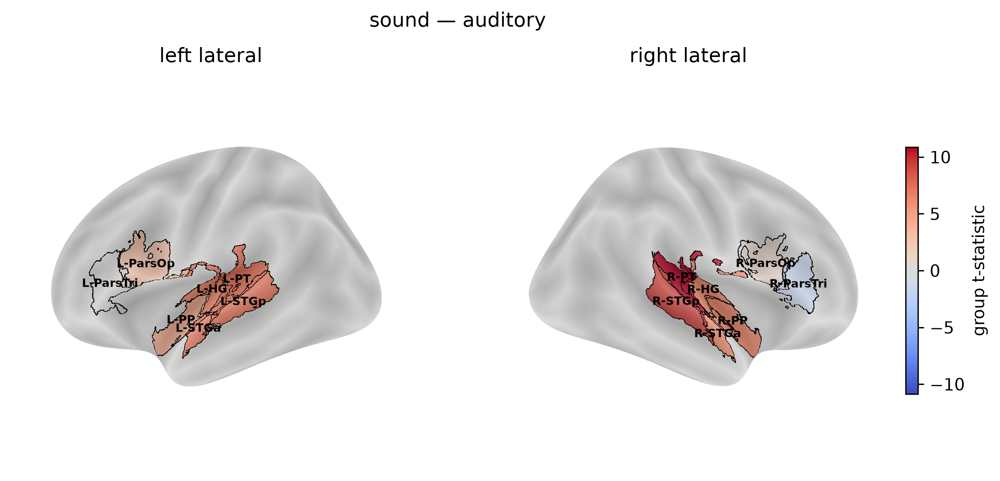

In [128]:
stat_dict = {f"{hemi}-{region}": t for (region, hemi, t) in comparisons}
mask_path_dict = build_mask_path_dict(list(stat_dict.keys()), masks_dir, network_name, surf_space_label)

surface_views = ('lateral',) if network_name == 'auditory' else ('lateral', 'medial')
fig = plot_roi_surface_stat(stat_dict, mask_path_dict, title=f'{contrast_label} — {network_name}', views=surface_views, fsaverage=fsaverage)
#fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat.png'))


### Cortical surface plot (t-statistic, final vs. early)

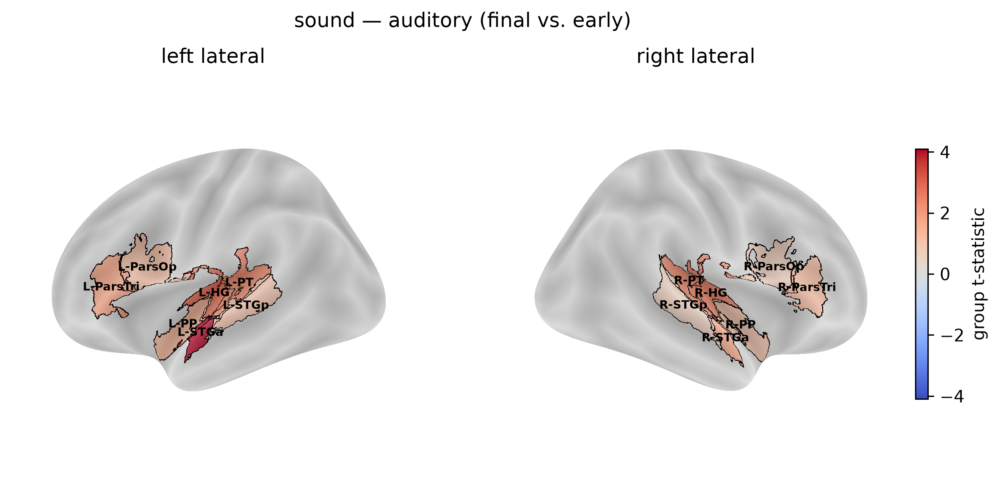

In [129]:
# Learning-stage difference (final vs. early)
_diff_df = (group_df[group_df['learning_stage'].isin(['early', 'final'])]
            .groupby(['participant_id', 'region_hemi', 'learning_stage'], as_index=False)['beta'].mean()
            .pivot(index=['participant_id', 'region_hemi'], columns='learning_stage', values='beta')
            .dropna()
            .reset_index())

diff_stat_dict = {}
for region_hemi, data in _diff_df.groupby('region_hemi'):
    t_stat, _ = ttest_rel(data['final'], data['early'])
    diff_stat_dict[region_hemi] = t_stat

mask_path_dict_diff = build_mask_path_dict(list(diff_stat_dict.keys()), masks_dir, network_name, surf_space_label)
surface_views_diff = ('lateral',) if network_name == 'auditory' else ('lateral', 'medial')
fig_diff = plot_roi_surface_stat(diff_stat_dict, mask_path_dict_diff,
                                  title=f'{contrast_label} — {network_name} (final vs. early)',
                                  views=surface_views_diff, fsaverage=fsaverage)
#fig_diff.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat_diff-final-early.svg'))
fig_diff.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat_diff-final-early.png'))


In [130]:
# Collect p-values
p_values = []
t_stats = []
comparisons = []

# average within participant first: one value per participant, so n (and df) = number of participants
for region, data in (roi_df_collapsed.groupby(["participant_id", "region"], as_index=False)["beta"].mean()
                     .groupby(["region"])):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    p_values.append(p_val)
    comparisons.append((region[0], t_stat))
    t_stats.append(t_stat)

# Apply FDR correction
_, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Print corrected results
for (region, t_stat), p_val_corr in zip(comparisons, p_corrected):
    print(f"Region: {region}, t = {t_stat:.2f}; corrected p = {p_val_corr:.4f}")


Region: HG, t = 7.12; corrected p = 0.0000
Region: PP, t = 5.65; corrected p = 0.0002
Region: PT, t = 10.20; corrected p = 0.0000
Region: ParsOp, t = 2.78; corrected p = 0.0195
Region: ParsTri, t = -1.27; corrected p = 0.2272
Region: STGa, t = 7.18; corrected p = 0.0000
Region: STGp, t = 9.47; corrected p = 0.0000


In [131]:
_records = [{'region': c[0], 't': c[1], 'df': len(sub_list) - 1, 'p': p}
            for c, p in zip(comparisons, p_values)]
export_ttests(_records, f'{contrast_label}_{network_name}_baseline_by_region', stats_out_dir)

,region,t,df,p,p_fdr,stat_str,stat_str_fdr
0,HG,7.12,12,p < .001,p < .001,"t(12) = 7.12, p < .001","t(12) = 7.12, q < .001"
1,PP,5.65,12,p < .001,p < .001,"t(12) = 5.65, p < .001","t(12) = 5.65, q < .001"
2,PT,10.20,12,p < .001,p < .001,"t(12) = 10.20, p < .001","t(12) = 10.20, q < .001"
3,ParsOp,2.78,12,p = .017,p = .019,"t(12) = 2.78, p = .017","t(12) = 2.78, q = .019"
4,ParsTri,-1.27,12,p = .227,p = .227,"t(12) = -1.27, p = .227","t(12) = -1.27, q = .227"
5,STGa,7.18,12,p < .001,p < .001,"t(12) = 7.18, p < .001","t(12) = 7.18, q < .001"
6,STGp,9.47,12,p < .001,p < .001,"t(12) = 9.47, p < .001","t(12) = 9.47, q < .001"


## `contrast-sound` for prefrontal cortical network

In [132]:
# get the beta map for the contrast of interest for each subject
network_name = network_list[3]
contrast_label = contrast_list[0]
event_type = contrast_event_type[contrast_label]
print('network_name:', network_name)
print('contrast_label:', contrast_label)

network_name: pfc
contrast_label: sound


In [133]:
# per-group copy of the ROI table that the cells below (and robustness_checks.py) read
out_fname = f'univariate-results_network-{network_name}_contrast-{contrast_label}{group_suffix}.tsv'
combined_roi_df_fpath = os.path.join(group_out_dir, out_fname)

In [134]:
# this group's per-ROI values (from extract_roi_values.py), saved under the
# name the cells below and robustness_checks.py read
roi_df_long = load_roi_values(network_name, contrast_label)
roi_df_long.to_csv(combined_roi_df_fpath, sep='\t', index=False)
roi_df_long.groupby('learning_stage').participant_id.nunique()

learning_stage
early     13
final     13
middle    13
Name: participant_id, dtype: int64

In [135]:
# load the DataFrame if already exists
roi_df_long = pd.read_csv(combined_roi_df_fpath, sep='\t')

# create a bilateral-averaged dataframe (for across-contrast analysis)
sound_pfc_df = bilateral_mean(roi_df_long)


In [136]:
roi_df_long.columns

Index(['participant_id', 'participant_group', 'region', 'beta', 'region_hemi',
       'hemisphere', 'learning_stage'],
      dtype='str')

In [137]:
roi_df_long.participant_id.unique()

<StringArray>
['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17',
 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24',
 'sub-FLT26']
Length: 13, dtype: str

In [138]:
roi_df_long.region.unique()

<StringArray>
['FP', 'SFG', 'MFG', 'IFGt', 'IFGo', 'PreCG', 'FMC', 'PCG', 'ACC', 'OFC',
 'FO']
Length: 11, dtype: str

In [139]:
roi_df_long.region_hemi.unique()

<StringArray>
[   'L-FP',    'R-FP',   'L-SFG',   'R-SFG',   'L-MFG',   'R-MFG',  'L-IFGt',
  'R-IFGt',  'L-IFGo',  'R-IFGo', 'L-PreCG', 'R-PreCG',   'L-FMC',   'R-FMC',
   'L-PCG',   'R-PCG',   'L-ACC',   'R-ACC',   'L-OFC',   'R-OFC',    'L-FO',
    'R-FO']
Length: 22, dtype: str

In [140]:
group_df = roi_df_long

In [141]:
plot_order = ['ACC', 'PCG', 'OFC', 'FP', 'FO', 'FMC', 
              'SFG', 'MFG', 'IFGt', 'IFGo', 'PreCG']

/scratch/slurm-12192413/ipykernel_2562235/276266010.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')


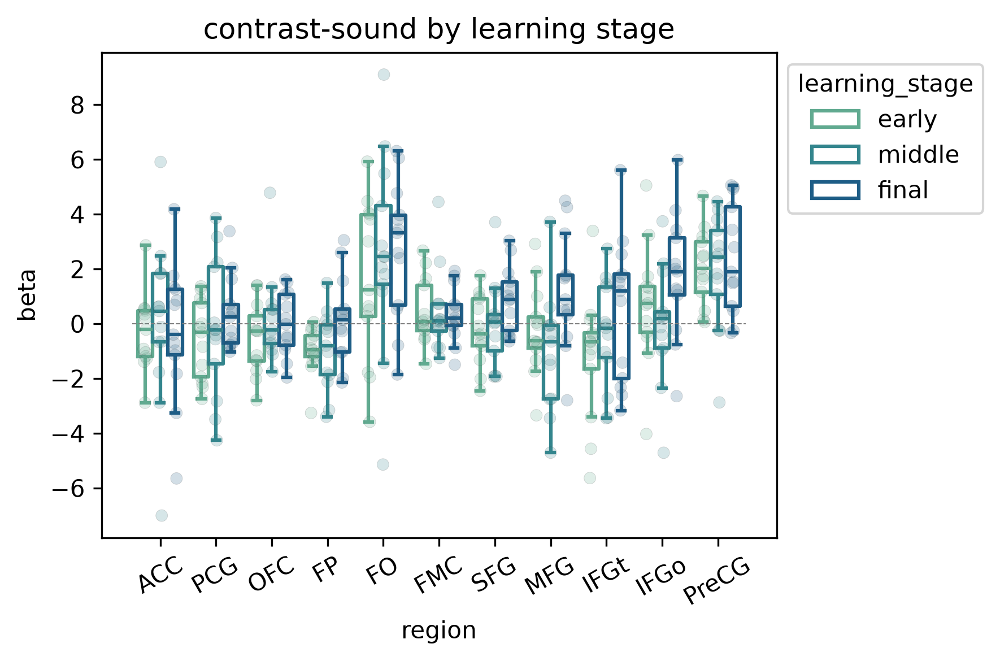

In [142]:
fig, ax = plt.subplots(1, 1, figsize=(6,4), dpi=300)

roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'learning_stage'], 
                                       as_index=False).agg({"beta": "mean"})

sns.boxplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='learning_stage', hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              fliersize = 0,            
              linewidth=1.5,
              fill=False,
              #legend=None,
              ax=ax);
sns.stripplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='learning_stage', hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              dodge=True,
              linewidth=0.2,
              alpha=.2,
              legend=None,
              ax=ax);


xmin, xmax = ax.get_xlim()
ax.hlines(y=0, xmin=xmin, xmax=xmax, color='0.5', linestyle='--', linewidth=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f'contrast-{contrast_label} by learning stage');
#ax.set_ylim([-5, 5])

fig.tight_layout()

fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-stage.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-stage.png'))

/scratch/slurm-12192413/ipykernel_2562235/3292222178.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')


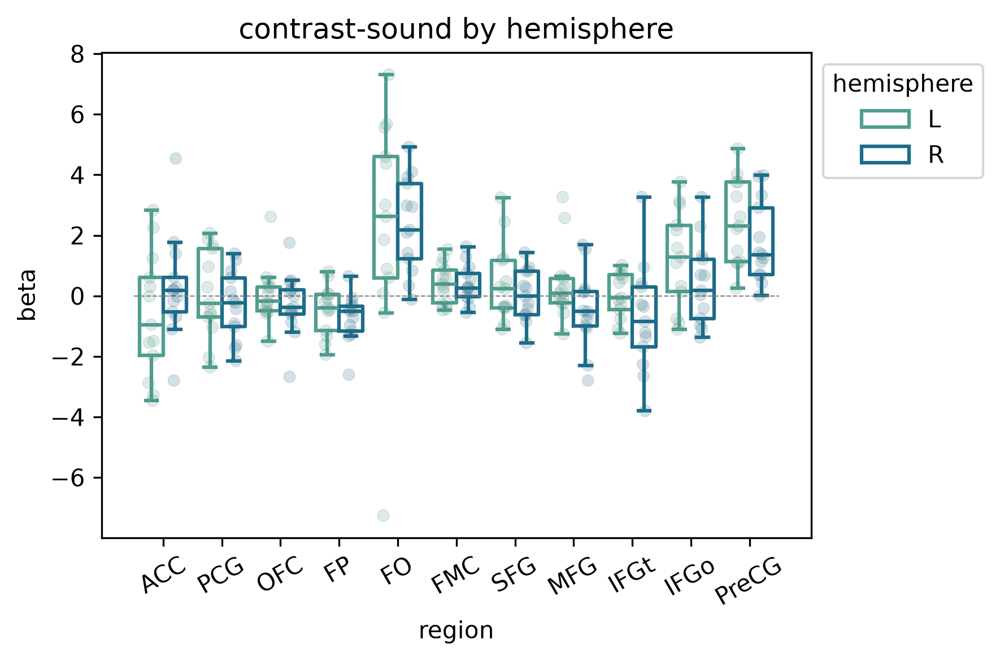

In [143]:
fig, ax = plt.subplots(1, 1, figsize=(6,4), dpi=300)

roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'hemisphere'], 
                                       as_index=False).agg({"beta": "mean"})

sns.boxplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='hemisphere', #hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              fliersize = 0,            
              linewidth=1.5,
              fill=False,
              #legend=None,
              ax=ax);
sns.stripplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='hemisphere', #hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              dodge=True,
              linewidth=0.2,
              alpha=.2,
              legend=None,
              ax=ax);


xmin, xmax = ax.get_xlim()
ax.hlines(y=0, xmin=xmin, xmax=xmax, color='0.5', linestyle='--', linewidth=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f'contrast-{contrast_label} by hemisphere');
#ax.set_ylim([-5, 5])

fig.tight_layout()

fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-hemisphere.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-hemisphere.png'))

### Brain-behavior correlations

In [144]:
# map runs to learning stages matching your thirds
stage_map = {'run-01': 'early', 'run-02': 'early',
             'run-03': 'middle', 'run-04': 'middle',
             'run-05': 'final', 'run-06': 'final'}

acc_df['learning_stage'] = acc_df['run'].map(stage_map)
acc_stage_df = acc_df.groupby(['participant_id', 'learning_stage'])['accuracy'].mean().reset_index()

In [145]:
# merge into roi_df_long — assumes participant_id and learning_stage columns exist in both
roi_df_bilateral = (roi_df_long.groupby(['participant_id', 'region', 'learning_stage'], as_index=False)['beta'].mean())
roi_behav_df = roi_df_bilateral.merge(acc_stage_df, on=['participant_id', 'learning_stage'])

# verify
roi_behav_df.groupby(['region', 'learning_stage']).size().unique()  # should be one row per participant


array([13])

In [146]:
roi_behav_df.columns

Index(['participant_id', 'region', 'learning_stage', 'beta', 'accuracy'], dtype='str')

In [147]:
roi_behav_df.participant_id.unique()

<StringArray>
['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17',
 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24',
 'sub-FLT26']
Length: 13, dtype: str

In [148]:
results = []
for stage in ['early', 'middle', 'final']:
    stage_df = roi_behav_df[roi_behav_df['learning_stage'] == stage]
    for roi in plot_order: # stage_df['region'].unique():
        sub_df = stage_df[stage_df['region'] == roi]
        r = pg.corr(sub_df['accuracy'], sub_df['beta'], method='pearson')
        results.append({
            'roi': roi,
            'learning_stage': stage,
            'r': r['r'].values[0],
            'p': r['p_val'].values[0],
            'n': r['n'].values[0],
            'stat_str': stat_str('r', r['r'].values[0], r['p_val'].values[0])
        })

behav_corr_df = pd.DataFrame(results)

In [149]:
behav_corr_df

,roi,learning_stage,r,p,n,stat_str
0,ACC,early,-0.1445,0.6377,13,"r = -.14, p = .638"
1,PCG,early,-0.2476,0.4148,13,"r = -.25, p = .415"
2,OFC,early,0.1362,0.6572,13,"r = .14, p = .657"
3,FP,early,0.2113,0.4884,13,"r = .21, p = .488"
4,FO,early,-0.3735,0.2087,13,"r = -.37, p = .209"
5,FMC,early,-0.0002,0.9996,13,"r = -.00, p = 1.000"
6,SFG,early,-0.1165,0.7046,13,"r = -.12, p = .705"
7,MFG,early,0.1685,0.5822,13,"r = .17, p = .582"
8,IFGt,early,0.0097,0.9749,13,"r = .01, p = .975"
9,IFGo,early,-0.1049,0.7330,13,"r = -.10, p = .733"


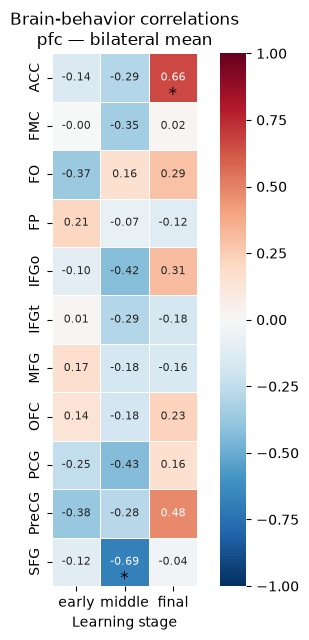

In [150]:
# pivot to ROI × stage matrix
r_matrix = behav_corr_df.pivot(index='roi', columns='learning_stage', values='r')[['early', 'middle', 'final']]
p_matrix = behav_corr_df.pivot(index='roi', columns='learning_stage', values='p')[['early', 'middle', 'final']]

fig, ax = plt.subplots(figsize=(5, len(r_matrix) * 0.5 + 1), dpi=100)
sns.heatmap(r_matrix, ax=ax, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot=True, fmt='.2f', annot_kws={'size': 8},
            square=True)

# mark significant cells with an asterisk
for i, roi in enumerate(r_matrix.index):
    for j, stage in enumerate(['early', 'middle', 'final']):
        p = p_matrix.loc[roi, stage]
        if p < 0.05:
            ax.text(j + 0.5, i + 0.85, '*', ha='center', va='center',
                    fontsize=12, color='black')

ax.set_title(f'Brain-behavior correlations\n{network_name} — bilateral mean')
ax.set_ylabel('')
ax.set_xlabel('Learning stage')
plt.tight_layout()
plt.savefig(os.path.join(fig_out_dir, f'brain-behav-corr_contrast-{contrast_label}_network-{network_name}_heatmap.svg'))

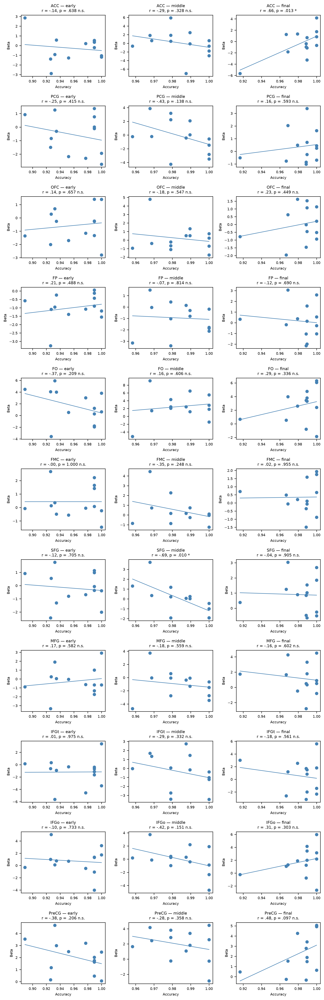

In [151]:
rois = behav_corr_df['roi'].unique()
stages = ['early', 'middle', 'final']

fig, axes = plt.subplots(len(rois), 3, figsize=(9, len(rois) * 2.5), dpi=300, sharex=False, sharey=False)

for ri, roi in enumerate(plot_order): # rois):
    for si, stage in enumerate(stages):
        ax = axes[ri, si]
        sub_df = roi_behav_df[(roi_behav_df['region'] == roi) & 
                              (roi_behav_df['learning_stage'] == stage)]
        
        ax.scatter(sub_df['accuracy'], sub_df['beta'], s=30, color='steelblue', zorder=3)
        
        # regression line
        m, b = np.polyfit(sub_df['accuracy'], sub_df['beta'], 1)
        x_range = np.linspace(sub_df['accuracy'].min(), sub_df['accuracy'].max(), 100)
        ax.plot(x_range, m * x_range + b, color='steelblue', linewidth=1)
        
        # stat annotation
        row = behav_corr_df[(behav_corr_df['roi'] == roi) & 
                            (behav_corr_df['learning_stage'] == stage)].iloc[0]
        p_str = '*' if row['p'] < 0.05 else 'n.s.'
        ax.set_title(f"{roi} — {stage}\n{row['stat_str']} {p_str}", fontsize=8)
        ax.set_xlabel('Accuracy', fontsize=7)
        ax.set_ylabel('Beta', fontsize=7)
        ax.tick_params(labelsize=7)

plt.tight_layout()
plt.savefig(os.path.join(fig_out_dir, f'brain-behav-corr_contrast-{contrast_label}_network-{network_name}_corr-plots.svg'))

ACC early: r = -.14, p = .638 n.s.
ACC middle: r = -.29, p = .328 n.s.
ACC final: r = .66, p = .013 *
PCG early: r = -.25, p = .415 n.s.
PCG middle: r = -.43, p = .138 n.s.
PCG final: r = .16, p = .593 n.s.
OFC early: r = .14, p = .657 n.s.
OFC middle: r = -.18, p = .547 n.s.
OFC final: r = .23, p = .449 n.s.
FP early: r = .21, p = .488 n.s.
FP middle: r = -.07, p = .814 n.s.
FP final: r = -.12, p = .690 n.s.
FO early: r = -.37, p = .209 n.s.
FO middle: r = .16, p = .606 n.s.
FO final: r = .29, p = .336 n.s.
FMC early: r = -.00, p = 1.000 n.s.
FMC middle: r = -.35, p = .248 n.s.
FMC final: r = .02, p = .955 n.s.
SFG early: r = -.12, p = .705 n.s.
SFG middle: r = -.69, p = .010 *
SFG final: r = -.04, p = .905 n.s.
MFG early: r = .17, p = .582 n.s.
MFG middle: r = -.18, p = .559 n.s.
MFG final: r = -.16, p = .602 n.s.
IFGt early: r = .01, p = .975 n.s.
IFGt middle: r = -.29, p = .332 n.s.
IFGt final: r = -.18, p = .561 n.s.
IFGo early: r = -.10, p = .733 n.s.
IFGo middle: r = -.42, p = .

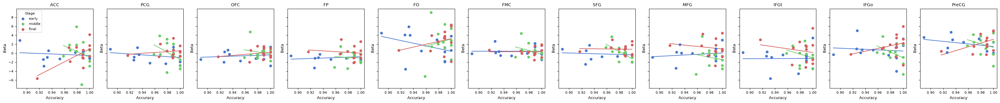

In [152]:
stage_colors = {'early': '#4878CF', 'middle': '#6ACC65', 'final': '#D65F5F'}
stages = ['early', 'middle', 'final']
rois = behav_corr_df['roi'].unique()

fig, axes = plt.subplots(1, len(rois), figsize=(3 * len(rois), 3.5), dpi=100, sharey=True)
if len(rois) == 1:
    axes = [axes]

for ri, roi in enumerate(plot_order): # rois):
    ax = axes[ri]
    for stage in stages:
        color = stage_colors[stage]
        sub_df = roi_behav_df[(roi_behav_df['region'] == roi) &
                              (roi_behav_df['learning_stage'] == stage)]

        ax.scatter(sub_df['accuracy'], sub_df['beta'], s=30,
                   color=color, label=stage, zorder=3)

        m, b = np.polyfit(sub_df['accuracy'], sub_df['beta'], 1)
        x_range = np.linspace(sub_df['accuracy'].min(), sub_df['accuracy'].max(), 100)
        ax.plot(x_range, m * x_range + b, color=color, linewidth=1.5)

        # stat annotation per stage
        row = behav_corr_df[(behav_corr_df['roi'] == roi) &
                            (behav_corr_df['learning_stage'] == stage)].iloc[0]
        p_str = '*' if row['p'] < 0.05 else 'n.s.'
        print(f"{roi} {stage}: {row['stat_str']} {p_str}")

    ax.set_title(roi, fontsize=10)
    ax.set_xlabel('Accuracy', fontsize=9)
    ax.set_ylabel('Beta', fontsize=9)
    ax.tick_params(labelsize=8)

axes[0].legend(title='Stage', fontsize=8, title_fontsize=8)
plt.tight_layout()


### omnibus ANOVA stats

In [153]:
# Mixed-Effects ANOVA with Hemisphere, Region, and Interaction
aov = AnovaRM(group_df, 
              aggregate_func='mean',
              depvar='beta', 
              subject='participant_id', 
              within=['hemisphere', 'learning_stage','region', ]).fit()

# Display results
print('network:', network_name)
print('contrast:', contrast_label)
print(aov)

network: pfc
contrast: sound
                             Anova
                                 F Value  Num DF  Den DF  Pr > F
----------------------------------------------------------------
hemisphere                        4.3340  1.0000  12.0000 0.0594
learning_stage                    1.9641  2.0000  24.0000 0.1622
region                           12.0302 10.0000 120.0000 0.0000
hemisphere:learning_stage         0.6138  2.0000  24.0000 0.5496
hemisphere:region                 1.1139 10.0000 120.0000 0.3574
learning_stage:region             1.1202 20.0000 240.0000 0.3292
hemisphere:learning_stage:region  1.1215 20.0000 240.0000 0.3279



In [154]:
export_anova(aov, f'{contrast_label}_{network_name}_hemisphere_learning-stage_region', stats_out_dir)

,source,F,df_num,df_den,p,stat_str
0,hemisphere,4.33,1.0000,12.0000,p = .059,"F(1, 12) = 4.33, p = .059"
1,learning_stage,1.96,2.0000,24.0000,p = .162,"F(2, 24) = 1.96, p = .162"
2,region,12.03,10.0000,120.0000,p < .001,"F(10, 120) = 12.03, p < .001"
3,hemisphere:learning_stage,0.61,2.0000,24.0000,p = .550,"F(2, 24) = 0.61, p = .550"
4,hemisphere:region,1.11,10.0000,120.0000,p = .357,"F(10, 120) = 1.11, p = .357"
5,learning_stage:region,1.12,20.0000,240.0000,p = .329,"F(20, 240) = 1.12, p = .329"
6,hemisphere:learning_stage:region,1.12,20.0000,240.0000,p = .328,"F(20, 240) = 1.12, p = .328"


In [155]:
# GG-corrected bilateral replication (learning_stage x region)
bilateral_df = (group_df
                .groupby(['participant_id', 'region', 'learning_stage'], as_index=False)['beta']
                .mean())
aov_pg = pg.rm_anova(data=bilateral_df, dv='beta',
                     within=['learning_stage', 'region'],
                     subject='participant_id',
                     detailed=True)
eta_col = 'np2' if 'np2' in aov_pg.columns else 'ng2'
print(aov_pg[['Source', 'F', 'ddof1', 'ddof2', 'p_unc', 'p_GG_corr', eta_col]])
export_pg_anova(aov_pg, f'{contrast_label}_{network_name}_learning-stage_region_bilateral', stats_out_dir)

                    Source       F  ddof1  ddof2  p_unc  p_GG_corr    ng2
0           learning_stage  1.9641      2     24 0.1622     0.1782 0.0365
1                   region 12.0302     10    120 0.0000     0.0000 0.1929
2  learning_stage * region  1.1202     20    240 0.3292     0.3569 0.0361


/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/pingouin/distribution.py:514: UserWarning: Epsilon values might be innaccurate in two-way repeated measures design where each  factor has more than 2 levels. Please  double-check your results.
  warnings.warn(


,source,df_num,df_den,F,p_unc,p_GG_corr,eta_p2,stat_str
0,learning_stage,2,24,1.96,p = .162,p = .178,0.04,"F(2, 24) = 1.96, p = .178"
1,region,10,120,12.03,p < .001,p < .001,0.19,"F(10, 120) = 12.03, p < .001"
2,learning_stage * region,20,240,1.12,p = .329,p = .357,0.04,"F(20, 240) = 1.12, p = .357"


In [156]:
import pingouin as pg

# Pairwise comparisons for region with FDR correction
pairwise_by_learning_stage = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['hemisphere','region', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_learning_stage.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_learning_stage)
#pairwise_by_learning_stage[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_learning_stage[pairwise_by_learning_stage.Contrast.str.contains(' * ')].reset_index()
pairwise_interaction = pairwise_interaction[pairwise_interaction['p_corr'] < 0.05].reset_index()
pairwise_interaction[['Contrast', 'hemisphere', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'hemisphere', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof',
       'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,hemisphere,A,B,T,dof,p_unc,p_corr,BF10
0,hemisphere * region,L,ACC,PreCG,-4.5196,12.0000,0.0007,0.0039,53.553
1,hemisphere * region,L,FMC,FP,3.3151,12.0000,0.0062,0.0226,8.613
2,hemisphere * region,L,FMC,PreCG,-4.9366,12.0000,0.0003,0.0022,98.792
3,hemisphere * region,L,FP,IFGo,-4.3229,12.0000,0.0010,0.0047,39.92
4,hemisphere * region,L,FP,IFGt,-3.0130,12.0000,0.0108,0.0360,5.44
5,hemisphere * region,L,FP,MFG,-3.2507,12.0000,0.0069,0.0240,7.807
6,hemisphere * region,L,FP,PreCG,-8.3760,12.0000,0.0000,0.0002,7933.76
7,hemisphere * region,L,FP,SFG,-3.3483,12.0000,0.0058,0.0226,9.061
8,hemisphere * region,L,IFGo,IFGt,3.3176,12.0000,0.0061,0.0226,8.646
9,hemisphere * region,L,IFGo,OFC,3.2479,12.0000,0.0070,0.0240,7.774


In [157]:
# pairwise by region

# Pairwise comparisons for region with FDR correction
pairwise_by_region = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['region', 'hemisphere',],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_region.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_region)
#pairwise_by_region[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_region[pairwise_by_region.Contrast.str.contains(' * ')].reset_index()
#pairwise_interaction = pairwise_interaction[pairwise_interaction['p_unc'] < 0.05]
pairwise_interaction[['Contrast', 'region', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'region', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof',
       'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,region,A,B,T,dof,p_unc,p_corr,BF10
0,region * hemisphere,ACC,L,R,-1.2297,12.0000,0.2424,0.3809,0.52
1,region * hemisphere,FMC,L,R,0.1315,12.0000,0.8976,0.8976,0.28
2,region * hemisphere,FO,L,R,-0.1325,12.0000,0.8968,0.8976,0.28
3,region * hemisphere,FP,L,R,1.3211,12.0000,0.2111,0.3809,0.569
4,region * hemisphere,IFGo,L,R,1.4293,12.0000,0.1784,0.3809,0.638
5,region * hemisphere,IFGt,L,R,1.4555,12.0000,0.1712,0.3809,0.656
6,region * hemisphere,MFG,L,R,3.2193,12.0000,0.0074,0.0810,7.441
7,region * hemisphere,OFC,L,R,1.0530,12.0000,0.3131,0.3950,0.443
8,region * hemisphere,PCG,L,R,1.0304,12.0000,0.3231,0.3950,0.435
9,region * hemisphere,PreCG,L,R,2.7864,12.0000,0.0165,0.0905,3.87


In [158]:
export_posthoc(pairwise_by_region, f'{contrast_label}_{network_name}_region_hemisphere', stats_out_dir)

,Contrast,region,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,region,-,ACC,FMC,-1.58,12.0000,p = .141,p = .215,"t(12) = -1.58, p = .141","t(12) = -1.58, q = .215"
1,region,-,ACC,FO,-4.15,12.0000,p = .001,p = .005,"t(12) = -4.15, p = .001","t(12) = -4.15, q = .005"
2,region,-,ACC,FP,1.27,12.0000,p = .227,p = .328,"t(12) = 1.27, p = .227","t(12) = 1.27, q = .328"
3,region,-,ACC,IFGo,-2.14,12.0000,p = .053,p = .094,"t(12) = -2.14, p = .053","t(12) = -2.14, q = .094"
4,region,-,ACC,IFGt,0.38,12.0000,p = .710,p = .787,"t(12) = 0.38, p = .710","t(12) = 0.38, q = .787"
5,region,-,ACC,MFG,-0.37,12.0000,p = .715,p = .787,"t(12) = -0.37, p = .715","t(12) = -0.37, q = .787"
6,region,-,ACC,OFC,-0.14,12.0000,p = .893,p = .910,"t(12) = -0.14, p = .893","t(12) = -0.14, q = .910"
7,region,-,ACC,PCG,-0.17,12.0000,p = .868,p = .901,"t(12) = -0.17, p = .868","t(12) = -0.17, q = .901"
8,region,-,ACC,PreCG,-6.12,12.0000,p < .001,p < .001,"t(12) = -6.12, p < .001","t(12) = -6.12, q < .001"
9,region,-,ACC,SFG,-1.05,12.0000,p = .313,p = .420,"t(12) = -1.05, p = .313","t(12) = -1.05, q = .420"


In [159]:

# Pairwise comparisons for region with FDR correction
pairwise_by_learning_stage = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['hemisphere','learning_stage', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_learning_stage.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_learning_stage)
#pairwise_by_learning_stage[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_learning_stage[pairwise_by_learning_stage.Contrast.str.contains(' * ')].reset_index()
#pairwise_interaction = pairwise_interaction[pairwise_interaction['p_corr'] < 0.05].reset_index()
pairwise_interaction[['Contrast', 'hemisphere', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'hemisphere', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof',
       'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,hemisphere,A,B,T,dof,p_unc,p_corr,BF10
0,hemisphere * learning_stage,L,early,final,-2.5023,12.0000,0.0278,0.1668,2.549
1,hemisphere * learning_stage,L,early,middle,-0.4594,12.0000,0.6542,0.7850,0.305
2,hemisphere * learning_stage,L,final,middle,1.2720,12.0000,0.2275,0.5053,0.542
3,hemisphere * learning_stage,R,early,final,-1.2018,12.0000,0.2526,0.5053,0.507
4,hemisphere * learning_stage,R,early,middle,-0.2654,12.0000,0.7952,0.7952,0.287
5,hemisphere * learning_stage,R,final,middle,0.8694,12.0000,0.4017,0.6026,0.384


In [160]:
export_posthoc(pairwise_by_learning_stage, f'{contrast_label}_{network_name}_hemisphere_learning-stage', stats_out_dir)

,Contrast,hemisphere,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,hemisphere,-,L,R,2.08,12.0000,p = .059,p = nan,"t(12) = 2.08, p = .059","t(12) = 2.08, q = nan"
1,learning_stage,-,early,final,-2.27,12.0000,p = .042,p = .127,"t(12) = -2.27, p = .042","t(12) = -2.27, q = .127"
2,learning_stage,-,early,middle,-0.45,12.0000,p = .661,p = .661,"t(12) = -0.45, p = .661","t(12) = -0.45, q = .661"
3,learning_stage,-,final,middle,1.17,12.0000,p = .266,p = .399,"t(12) = 1.17, p = .266","t(12) = 1.17, q = .399"
4,hemisphere * learning_stage,L,early,final,-2.50,12.0000,p = .028,p = .167,"t(12) = -2.50, p = .028","t(12) = -2.50, q = .167"
5,hemisphere * learning_stage,L,early,middle,-0.46,12.0000,p = .654,p = .785,"t(12) = -0.46, p = .654","t(12) = -0.46, q = .785"
6,hemisphere * learning_stage,L,final,middle,1.27,12.0000,p = .227,p = .505,"t(12) = 1.27, p = .227","t(12) = 1.27, q = .505"
7,hemisphere * learning_stage,R,early,final,-1.20,12.0000,p = .253,p = .505,"t(12) = -1.20, p = .253","t(12) = -1.20, q = .505"
8,hemisphere * learning_stage,R,early,middle,-0.27,12.0000,p = .795,p = .795,"t(12) = -0.27, p = .795","t(12) = -0.27, q = .795"
9,hemisphere * learning_stage,R,final,middle,0.87,12.0000,p = .402,p = .603,"t(12) = 0.87, p = .402","t(12) = 0.87, q = .603"


In [161]:

# Pairwise comparisons for region with FDR correction
pairwise_by_learning_stage = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['learning_stage','hemisphere', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_learning_stage.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_learning_stage)
#pairwise_by_learning_stage[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_learning_stage[pairwise_by_learning_stage.Contrast.str.contains(' * ')].reset_index()
#pairwise_interaction = pairwise_interaction[pairwise_interaction['p_corr'] < 0.05].reset_index()
pairwise_interaction[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'learning_stage', 'A', 'B', 'Paired', 'Parametric', 'T',
       'dof', 'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,learning_stage,A,B,T,dof,p_unc,p_corr,BF10
0,learning_stage * hemisphere,early,L,R,0.2436,12.0000,0.8116,0.8116,0.286
1,learning_stage * hemisphere,final,L,R,2.0930,12.0000,0.0583,0.1748,1.436
2,learning_stage * hemisphere,middle,L,R,0.7494,12.0000,0.4681,0.7021,0.354


In [162]:
export_posthoc(pairwise_by_learning_stage, f'{contrast_label}_{network_name}_learning-stage_hemisphere', stats_out_dir)

,Contrast,learning_stage,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,learning_stage,-,early,final,-2.27,12.0000,p = .042,p = .127,"t(12) = -2.27, p = .042","t(12) = -2.27, q = .127"
1,learning_stage,-,early,middle,-0.45,12.0000,p = .661,p = .661,"t(12) = -0.45, p = .661","t(12) = -0.45, q = .661"
2,learning_stage,-,final,middle,1.17,12.0000,p = .266,p = .399,"t(12) = 1.17, p = .266","t(12) = 1.17, q = .399"
3,hemisphere,-,L,R,2.08,12.0000,p = .059,p = nan,"t(12) = 2.08, p = .059","t(12) = 2.08, q = nan"
4,learning_stage * hemisphere,early,L,R,0.24,12.0000,p = .812,p = .812,"t(12) = 0.24, p = .812","t(12) = 0.24, q = .812"
5,learning_stage * hemisphere,final,L,R,2.09,12.0000,p = .058,p = .175,"t(12) = 2.09, p = .058","t(12) = 2.09, q = .175"
6,learning_stage * hemisphere,middle,L,R,0.75,12.0000,p = .468,p = .702,"t(12) = 0.75, p = .468","t(12) = 0.75, q = .702"


In [163]:
# pairwise by region, no learning stage

# Pairwise comparisons for region with FDR correction
pairwise_by_region_only = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['region', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_region_only.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_region_only)
pairwise_by_region_only = pairwise_by_region_only[pairwise_by_region_only['p_unc'] < 0.05]
pairwise_by_region_only[['Contrast', 'Contrast', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns


Available columns: Index(['Contrast', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof', 'alternative',
       'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,Contrast,A,B,T,dof,p_unc,p_corr,BF10
1,region,region,ACC,FO,-4.1506,12.0000,0.0013,0.0053,30.799
8,region,region,ACC,PreCG,-6.1152,12.0000,0.0001,0.0010,509.382
10,region,region,FMC,FO,-3.1451,12.0000,0.0085,0.0211,6.646
11,region,region,FMC,FP,3.9179,12.0000,0.0020,0.0066,21.64
13,region,region,FMC,IFGt,2.2589,12.0000,0.0433,0.0851,1.803
15,region,region,FMC,OFC,2.4642,12.0000,0.0298,0.0631,2.413
17,region,region,FMC,PreCG,-4.5798,12.0000,0.0006,0.0035,58.556
19,region,region,FO,FP,4.8988,12.0000,0.0004,0.0025,93.514
20,region,region,FO,IFGo,2.5150,12.0000,0.0272,0.0597,2.596
21,region,region,FO,IFGt,4.0544,12.0000,0.0016,0.0055,26.626


In [164]:
export_posthoc(pairwise_by_region_only, f'{contrast_label}_{network_name}_region', stats_out_dir)

,Contrast,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
1,region,ACC,FO,-4.15,12.0000,p = .001,p = .005,"t(12) = -4.15, p = .001","t(12) = -4.15, q = .005"
8,region,ACC,PreCG,-6.12,12.0000,p < .001,p < .001,"t(12) = -6.12, p < .001","t(12) = -6.12, q < .001"
10,region,FMC,FO,-3.15,12.0000,p = .008,p = .021,"t(12) = -3.15, p = .008","t(12) = -3.15, q = .021"
11,region,FMC,FP,3.92,12.0000,p = .002,p = .007,"t(12) = 3.92, p = .002","t(12) = 3.92, q = .007"
13,region,FMC,IFGt,2.26,12.0000,p = .043,p = .085,"t(12) = 2.26, p = .043","t(12) = 2.26, q = .085"
15,region,FMC,OFC,2.46,12.0000,p = .030,p = .063,"t(12) = 2.46, p = .030","t(12) = 2.46, q = .063"
17,region,FMC,PreCG,-4.58,12.0000,p < .001,p = .003,"t(12) = -4.58, p < .001","t(12) = -4.58, q = .003"
19,region,FO,FP,4.90,12.0000,p < .001,p = .003,"t(12) = 4.90, p < .001","t(12) = 4.90, q = .003"
20,region,FO,IFGo,2.52,12.0000,p = .027,p = .060,"t(12) = 2.52, p = .027","t(12) = 2.52, q = .060"
21,region,FO,IFGt,4.05,12.0000,p = .002,p = .005,"t(12) = 4.05, p = .002","t(12) = 4.05, q = .005"


### Collapse (average) over non-significant factors

In [165]:
roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'hemisphere'], 
                                       as_index=False).agg({"beta": "mean"})


In [166]:
roi_df_collapsed.head()

,participant_id,region,hemisphere,beta
0,sub-FLT03,ACC,L,2.8332
1,sub-FLT03,ACC,R,-0.0236
2,sub-FLT03,FMC,L,1.0797
3,sub-FLT03,FMC,R,0.5534
4,sub-FLT03,FO,L,0.0819


In [167]:
# Collect results
results = []

for (region, hemi), data in roi_df_collapsed.groupby(["region", "hemisphere"]):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    results.append({
        "region": region,
        "hemisphere": hemi,
        "t_stat": t_stat,
        "p_val": p_val
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Apply FDR correction
results_df["p_val_fdr"] = multipletests(results_df["p_val"], method="fdr_bh")[1]

# Print or export the table
results_df

# Optional: export
# results_df.to_csv("roi_stats.csv", index=False)
# results_df.to_excel("roi_stats.xlsx", index=False)


,region,hemisphere,t_stat,p_val,p_val_fdr
0,ACC,L,-1.1321,0.2797,0.4396
1,ACC,R,0.5952,0.5628,0.6879
2,FMC,L,2.2411,0.0447,0.1405
3,FMC,R,2.2571,0.0434,0.1405
4,FO,L,2.1392,0.0537,0.1476
5,FO,R,5.4105,0.0002,0.0017
6,FP,L,-2.0104,0.0674,0.1648
7,FP,R,-3.3518,0.0058,0.0317
8,IFGo,L,2.7561,0.0174,0.0766
9,IFGo,R,1.0128,0.3311,0.4500


In [168]:
_export = results_df.rename(columns={'t_stat': 't', 'p_val': 'p'}).copy()
_export['df'] = len(sub_list) - 1
export_ttests(_export.to_dict('records'), f'{contrast_label}_{network_name}_baseline_by_region_hemi', stats_out_dir)

,region,hemisphere,t,p,p_val_fdr,df,p_fdr,stat_str,stat_str_fdr
0,ACC,L,-1.13,p = .280,0.4396,12,p = .440,"t(12) = -1.13, p = .280","t(12) = -1.13, q = .440"
1,ACC,R,0.60,p = .563,0.6879,12,p = .688,"t(12) = 0.60, p = .563","t(12) = 0.60, q = .688"
2,FMC,L,2.24,p = .045,0.1405,12,p = .141,"t(12) = 2.24, p = .045","t(12) = 2.24, q = .141"
3,FMC,R,2.26,p = .043,0.1405,12,p = .141,"t(12) = 2.26, p = .043","t(12) = 2.26, q = .141"
4,FO,L,2.14,p = .054,0.1476,12,p = .148,"t(12) = 2.14, p = .054","t(12) = 2.14, q = .148"
5,FO,R,5.41,p < .001,0.0017,12,p = .002,"t(12) = 5.41, p < .001","t(12) = 5.41, q = .002"
6,FP,L,-2.01,p = .067,0.1648,12,p = .165,"t(12) = -2.01, p = .067","t(12) = -2.01, q = .165"
7,FP,R,-3.35,p = .006,0.0317,12,p = .032,"t(12) = -3.35, p = .006","t(12) = -3.35, q = .032"
8,IFGo,L,2.76,p = .017,0.0766,12,p = .077,"t(12) = 2.76, p = .017","t(12) = 2.76, q = .077"
9,IFGo,R,1.01,p = .331,0.4500,12,p = .450,"t(12) = 1.01, p = .331","t(12) = 1.01, q = .450"


In [169]:
# Collect results
results = []

# average within participant first: one value per participant, so n (and df) = number of participants
for region, data in (roi_df_collapsed.groupby(["participant_id", "region"], as_index=False)["beta"].mean()
                     .groupby("region")):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    results.append({
        "region": region,
        "t_stat": t_stat,
        "p_val": p_val
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Apply FDR correction
results_df["p_val_fdr"] = multipletests(results_df["p_val"], method="fdr_bh")[1]

# Print or export the table
results_df

# Optional: export
# results_df.to_csv("roi_stats.csv", index=False)
# results_df.to_excel("roi_stats.xlsx", index=False)


,region,t_stat,p_val,p_val_fdr
0,ACC,-0.4959,0.6289,0.7686
1,FMC,2.3547,0.0364,0.0801
2,FO,3.7953,0.0026,0.0140
3,FP,-2.9694,0.0117,0.0430
4,IFGo,2.7783,0.0167,0.0459
5,IFGt,-1.2727,0.2272,0.4166
6,MFG,-0.0862,0.9327,0.9327
7,OFC,-0.5371,0.6010,0.7686
8,PCG,-0.3929,0.7013,0.7714
9,PreCG,5.8489,0.0001,0.0009


In [170]:
_export = results_df.rename(columns={'t_stat': 't', 'p_val': 'p'}).copy()
_export['df'] = len(sub_list) - 1
export_ttests(_export.to_dict('records'), f'{contrast_label}_{network_name}_baseline_by_region', stats_out_dir)

,region,t,p,p_val_fdr,df,p_fdr,stat_str,stat_str_fdr
0,ACC,-0.50,p = .629,0.7686,12,p = .769,"t(12) = -0.50, p = .629","t(12) = -0.50, q = .769"
1,FMC,2.35,p = .036,0.0801,12,p = .080,"t(12) = 2.35, p = .036","t(12) = 2.35, q = .080"
2,FO,3.80,p = .003,0.0140,12,p = .014,"t(12) = 3.80, p = .003","t(12) = 3.80, q = .014"
3,FP,-2.97,p = .012,0.0430,12,p = .043,"t(12) = -2.97, p = .012","t(12) = -2.97, q = .043"
4,IFGo,2.78,p = .017,0.0459,12,p = .046,"t(12) = 2.78, p = .017","t(12) = 2.78, q = .046"
5,IFGt,-1.27,p = .227,0.4166,12,p = .417,"t(12) = -1.27, p = .227","t(12) = -1.27, q = .417"
6,MFG,-0.09,p = .933,0.9327,12,p = .933,"t(12) = -0.09, p = .933","t(12) = -0.09, q = .933"
7,OFC,-0.54,p = .601,0.7686,12,p = .769,"t(12) = -0.54, p = .601","t(12) = -0.54, q = .769"
8,PCG,-0.39,p = .701,0.7714,12,p = .771,"t(12) = -0.39, p = .701","t(12) = -0.39, q = .771"
9,PreCG,5.85,p < .001,0.0009,12,p < .001,"t(12) = 5.85, p < .001","t(12) = 5.85, q < .001"


In [171]:
# Collect p-values
p_values = []
t_stats = []
comparisons = []

for region_stage, data in roi_df_collapsed.groupby(["region",'hemisphere']):
    #print(region_stage)
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    p_values.append(p_val)
    comparisons.append((region_stage[0], region_stage[1], t_stat))
    t_stats.append(t_stat)

# Apply FDR correction
_, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Print corrected results
for (region, hemisphere, t_stat), p_val_corr in zip(comparisons, p_corrected):
    print(f"Region: {region}, hemisphere: {hemisphere}, t = {t_stat:.2f}; corrected p = {p_val_corr:.4f}")


Region: ACC, hemisphere: L, t = -1.13; corrected p = 0.4396
Region: ACC, hemisphere: R, t = 0.60; corrected p = 0.6879
Region: FMC, hemisphere: L, t = 2.24; corrected p = 0.1405
Region: FMC, hemisphere: R, t = 2.26; corrected p = 0.1405
Region: FO, hemisphere: L, t = 2.14; corrected p = 0.1476
Region: FO, hemisphere: R, t = 5.41; corrected p = 0.0017
Region: FP, hemisphere: L, t = -2.01; corrected p = 0.1648
Region: FP, hemisphere: R, t = -3.35; corrected p = 0.0317
Region: IFGo, hemisphere: L, t = 2.76; corrected p = 0.0766
Region: IFGo, hemisphere: R, t = 1.01; corrected p = 0.4500
Region: IFGt, hemisphere: L, t = 0.10; corrected p = 0.9264
Region: IFGt, hemisphere: R, t = -1.48; corrected p = 0.3635
Region: MFG, hemisphere: L, t = 1.16; corrected p = 0.4396
Region: MFG, hemisphere: R, t = -1.28; corrected p = 0.4396
Region: OFC, hemisphere: L, t = 0.11; corrected p = 0.9264
Region: OFC, hemisphere: R, t = -0.98; corrected p = 0.4500
Region: PCG, hemisphere: L, t = 0.17; corrected p 

In [172]:
_records = [{'region': c[0], 'hemisphere': c[1], 't': c[2], 'df': len(sub_list) - 1, 'p': p}
            for c, p in zip(comparisons, p_values)]
export_ttests(_records, f'{contrast_label}_{network_name}_baseline_by_region_hemi', stats_out_dir)

,region,hemisphere,t,df,p,p_fdr,stat_str,stat_str_fdr
0,ACC,L,-1.13,12,p = .280,p = .440,"t(12) = -1.13, p = .280","t(12) = -1.13, q = .440"
1,ACC,R,0.60,12,p = .563,p = .688,"t(12) = 0.60, p = .563","t(12) = 0.60, q = .688"
2,FMC,L,2.24,12,p = .045,p = .141,"t(12) = 2.24, p = .045","t(12) = 2.24, q = .141"
3,FMC,R,2.26,12,p = .043,p = .141,"t(12) = 2.26, p = .043","t(12) = 2.26, q = .141"
4,FO,L,2.14,12,p = .054,p = .148,"t(12) = 2.14, p = .054","t(12) = 2.14, q = .148"
5,FO,R,5.41,12,p < .001,p = .002,"t(12) = 5.41, p < .001","t(12) = 5.41, q = .002"
6,FP,L,-2.01,12,p = .067,p = .165,"t(12) = -2.01, p = .067","t(12) = -2.01, q = .165"
7,FP,R,-3.35,12,p = .006,p = .032,"t(12) = -3.35, p = .006","t(12) = -3.35, q = .032"
8,IFGo,L,2.76,12,p = .017,p = .077,"t(12) = 2.76, p = .017","t(12) = 2.76, q = .077"
9,IFGo,R,1.01,12,p = .331,p = .450,"t(12) = 1.01, p = .331","t(12) = 1.01, q = .450"


### Cortical surface plot (t-statistic, by hemisphere)

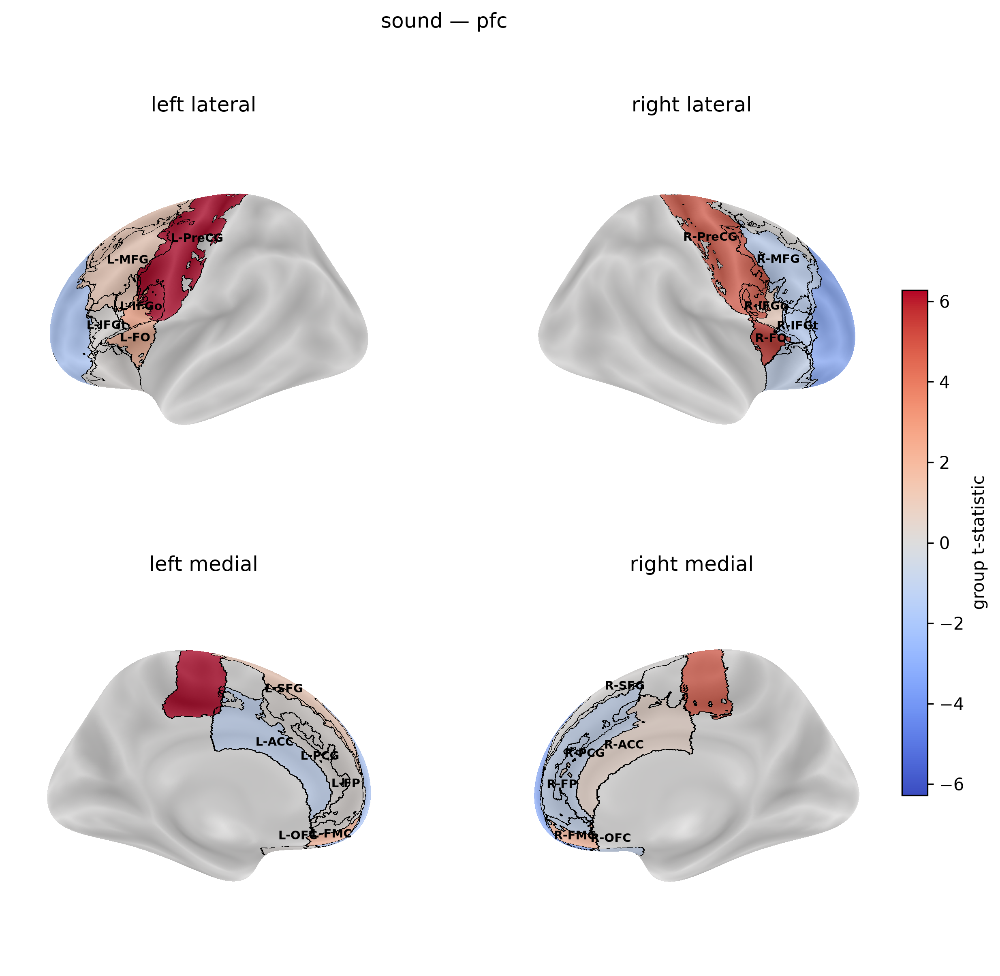

In [173]:
stat_dict = {f"{hemi}-{region}": t for (region, hemi, t) in comparisons}
mask_path_dict = build_mask_path_dict(list(stat_dict.keys()), masks_dir, network_name, surf_space_label)

surface_views = ('lateral',) if network_name == 'auditory' else ('lateral', 'medial')
fig = plot_roi_surface_stat(stat_dict, mask_path_dict, title=f'{contrast_label} — {network_name}', views=surface_views, fsaverage=fsaverage)
#fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat.png'))


### Cortical surface plot (t-statistic, final vs. early)

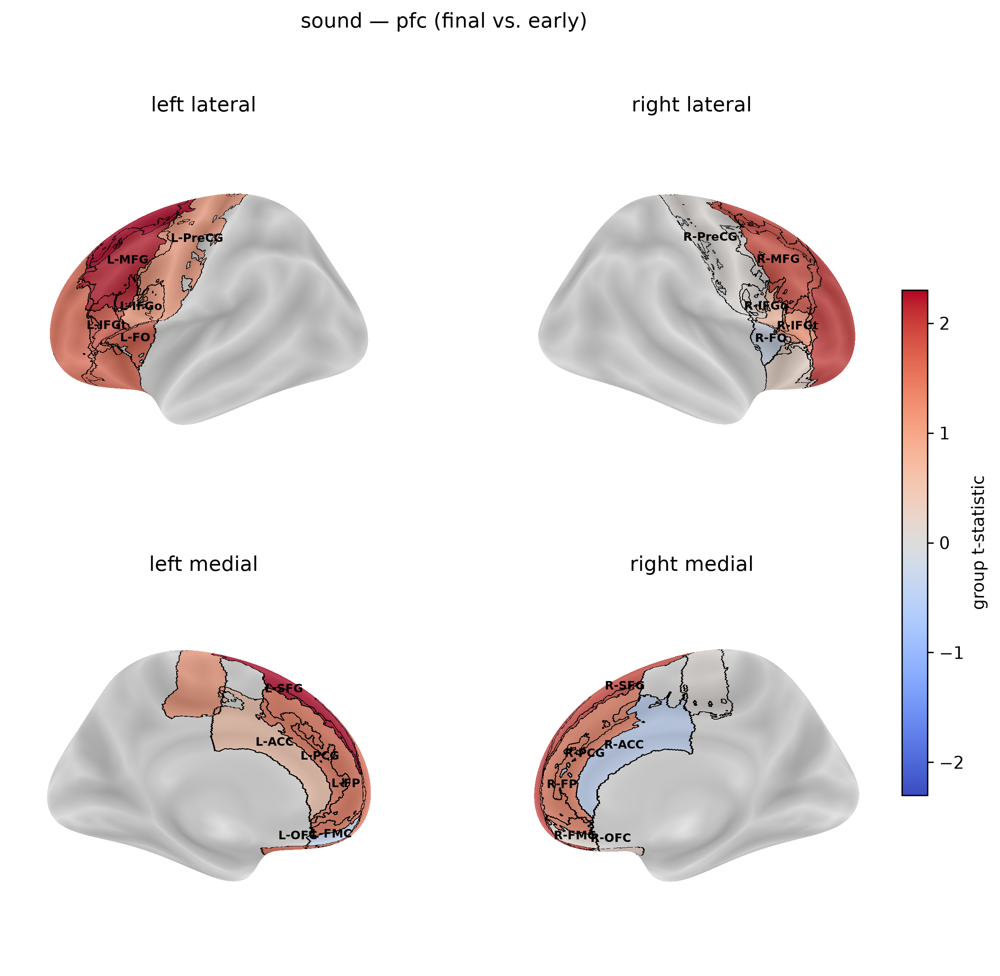

In [174]:
# Learning-stage difference (final vs. early)
_diff_df = (group_df[group_df['learning_stage'].isin(['early', 'final'])]
            .groupby(['participant_id', 'region_hemi', 'learning_stage'], as_index=False)['beta'].mean()
            .pivot(index=['participant_id', 'region_hemi'], columns='learning_stage', values='beta')
            .dropna()
            .reset_index())

diff_stat_dict = {}
for region_hemi, data in _diff_df.groupby('region_hemi'):
    t_stat, _ = ttest_rel(data['final'], data['early'])
    diff_stat_dict[region_hemi] = t_stat

mask_path_dict_diff = build_mask_path_dict(list(diff_stat_dict.keys()), masks_dir, network_name, surf_space_label)
surface_views_diff = ('lateral',) if network_name == 'auditory' else ('lateral', 'medial')
fig_diff = plot_roi_surface_stat(diff_stat_dict, mask_path_dict_diff,
                                  title=f'{contrast_label} — {network_name} (final vs. early)',
                                  views=surface_views_diff, fsaverage=fsaverage)
#fig_diff.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat_diff-final-early.svg'))
fig_diff.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat_diff-final-early.png'))


In [175]:
# Collect p-values
p_values = []
t_stats = []
comparisons = []

# average within participant first: one value per participant, so n (and df) = number of participants
for region, data in (roi_df_collapsed.groupby(["participant_id", "region"], as_index=False)["beta"].mean()
                     .groupby(["region"])):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    p_values.append(p_val)
    comparisons.append((region[0], t_stat))
    t_stats.append(t_stat)

# Apply FDR correction
_, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Print corrected results
for (region, t_stat), p_val_corr in zip(comparisons, p_corrected):
    print(f"Region: {region}, t = {t_stat:.2f}; corrected p = {p_val_corr:.4f}")


Region: ACC, t = -0.50; corrected p = 0.7686
Region: FMC, t = 2.35; corrected p = 0.0801
Region: FO, t = 3.80; corrected p = 0.0140
Region: FP, t = -2.97; corrected p = 0.0430
Region: IFGo, t = 2.78; corrected p = 0.0459
Region: IFGt, t = -1.27; corrected p = 0.4166
Region: MFG, t = -0.09; corrected p = 0.9327
Region: OFC, t = -0.54; corrected p = 0.7686
Region: PCG, t = -0.39; corrected p = 0.7714
Region: PreCG, t = 5.85; corrected p = 0.0009
Region: SFG, t = 0.80; corrected p = 0.6904


In [176]:
_records = [{'region': c[0], 't': c[1], 'df': len(sub_list) - 1, 'p': p}
            for c, p in zip(comparisons, p_values)]
export_ttests(_records, f'{contrast_label}_{network_name}_baseline_by_region', stats_out_dir)

,region,t,df,p,p_fdr,stat_str,stat_str_fdr
0,ACC,-0.50,12,p = .629,p = .769,"t(12) = -0.50, p = .629","t(12) = -0.50, q = .769"
1,FMC,2.35,12,p = .036,p = .080,"t(12) = 2.35, p = .036","t(12) = 2.35, q = .080"
2,FO,3.80,12,p = .003,p = .014,"t(12) = 3.80, p = .003","t(12) = 3.80, q = .014"
3,FP,-2.97,12,p = .012,p = .043,"t(12) = -2.97, p = .012","t(12) = -2.97, q = .043"
4,IFGo,2.78,12,p = .017,p = .046,"t(12) = 2.78, p = .017","t(12) = 2.78, q = .046"
5,IFGt,-1.27,12,p = .227,p = .417,"t(12) = -1.27, p = .227","t(12) = -1.27, q = .417"
6,MFG,-0.09,12,p = .933,p = .933,"t(12) = -0.09, p = .933","t(12) = -0.09, q = .933"
7,OFC,-0.54,12,p = .601,p = .769,"t(12) = -0.54, p = .601","t(12) = -0.54, q = .769"
8,PCG,-0.39,12,p = .701,p = .771,"t(12) = -0.39, p = .701","t(12) = -0.39, q = .771"
9,PreCG,5.85,12,p < .001,p < .001,"t(12) = 5.85, p < .001","t(12) = 5.85, q < .001"


## `contrast-fb` for striatal network

In [177]:
# get the beta map for the contrast of interest for each subject
network_name = network_list[1]
contrast_label = contrast_list[2]
event_type = contrast_event_type[contrast_label]
print('network_name:', network_name)
print('contrast_label:', contrast_label)

network_name: tian-S2
contrast_label: fbcorrect


In [178]:
# per-group copy of the ROI table that the cells below (and robustness_checks.py) read
out_fname = f'univariate-results_network-{network_name}_contrast-{contrast_label}{group_suffix}.tsv'
combined_roi_df_fpath = os.path.join(group_out_dir, out_fname)

In [179]:
# this group's per-ROI values (from extract_roi_values.py), saved under the
# name the cells below and robustness_checks.py read
roi_df_long = load_roi_values(network_name, contrast_label)
roi_df_long.to_csv(combined_roi_df_fpath, sep='\t', index=False)
roi_df_long.groupby('learning_stage').participant_id.nunique()

learning_stage
early     13
final     13
middle    13
Name: participant_id, dtype: int64

In [180]:
# load the DataFrame if already exists
roi_df_long = pd.read_csv(combined_roi_df_fpath, sep='\t')

# create a bilateral-averaged dataframe (for across-contrast analysis)
feedback_striatum_df = bilateral_mean(roi_df_long)


In [181]:
roi_df_long.participant_id.unique()

<StringArray>
['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17',
 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24',
 'sub-FLT26']
Length: 13, dtype: str

In [182]:
roi_df_long.region.unique()

<StringArray>
['aCAU', 'pCAU', 'aPUT', 'pPUT', 'NAc-shell', 'NAc-core']
Length: 6, dtype: str

In [183]:
group_df = roi_df_long.copy()

# create a new column based on rostral–caudal axis
group_df['Axis'] = ''

if network_name == 'tian-S3':
    group_df.loc[(group_df['region']=='pCAU'),   'Axis'] = 'Caudal'
    group_df.loc[(group_df['region']=='PUT-VP'), 'Axis'] = 'Caudal'
    group_df.loc[(group_df['region']=='PUT-DP'), 'Axis'] = 'Caudal'

    group_df.loc[group_df['region']=='CAU-DA', 'Axis'] = 'Rostral'
    group_df.loc[group_df['region']=='CAU-VA', 'Axis'] = 'Rostral'
    group_df.loc[group_df['region']=='CAU-DP', 'Axis'] = 'Rostral'
    group_df.loc[group_df['region']=='CAU-VP', 'Axis'] = 'Rostral'

    group_df.loc[group_df['region']=='PUT-VA', 'Axis'] = 'Rostral'
    group_df.loc[group_df['region']=='PUT-DA', 'Axis'] = 'Rostral'

    group_df.loc[group_df['region']=='NAc-shell', 'Axis'] = 'Ventral'
    group_df.loc[group_df['region']=='NAc-core', 'Axis'] = 'Ventral'

elif network_name == 'tian-S2':
    group_df.loc[(group_df['region']=='pCAU'), 'Axis'] = 'Caudal'
    group_df.loc[(group_df['region']=='pPUT'), 'Axis'] = 'Caudal'    
    
    group_df.loc[(group_df['region']=='aCAU'), 'Axis'] = 'Rostral'
    group_df.loc[(group_df['region']=='aPUT'), 'Axis'] = 'Rostral'    

    group_df.loc[group_df['region']=='NAc-shell', 'Axis'] = 'Ventral'
    group_df.loc[group_df['region']=='NAc-core', 'Axis'] = 'Ventral'

group_df.head()

,participant_id,participant_group,region,beta,region_hemi,hemisphere,learning_stage,Axis
0,sub-FLT03,Mandarin,aCAU,-1.2554,aCAU-lh,lh,early,Rostral
1,sub-FLT03,Mandarin,aCAU,0.3354,aCAU-lh,lh,middle,Rostral
2,sub-FLT03,Mandarin,aCAU,-1.2734,aCAU-lh,lh,final,Rostral
3,sub-FLT03,Mandarin,pCAU,0.5537,pCAU-lh,lh,early,Caudal
4,sub-FLT03,Mandarin,pCAU,0.1700,pCAU-lh,lh,middle,Caudal


In [184]:
plot_order = ['aCAU', 'pCAU', 'aPUT', 'pPUT', 'NAc-core', 'NAc-shell', ]

/scratch/slurm-12192413/ipykernel_2562235/4213364461.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')


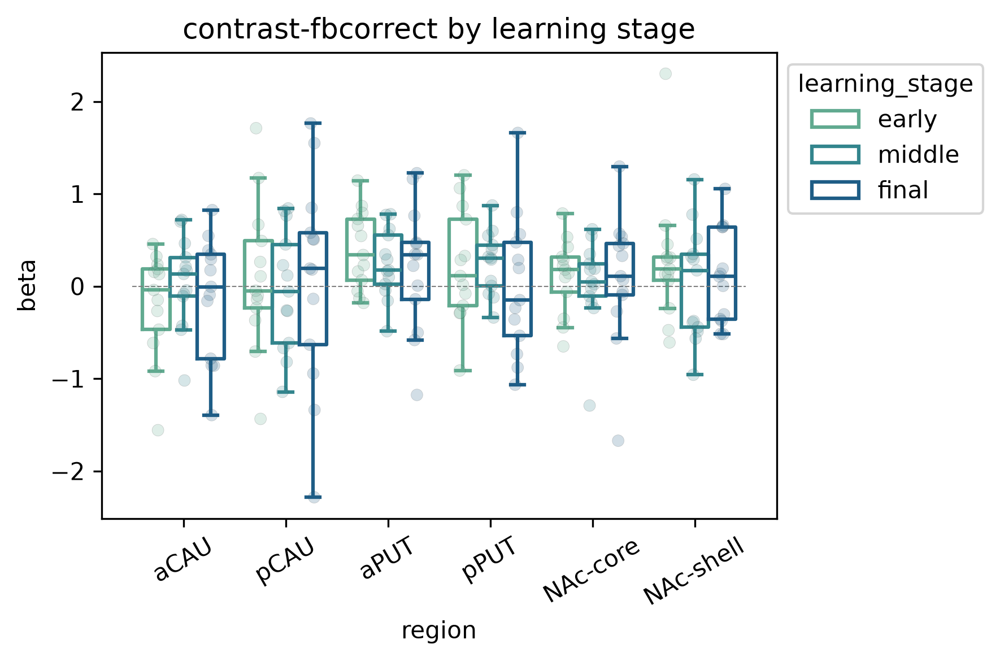

In [185]:
fig, ax = plt.subplots(1, 1, figsize=(6,4), dpi=300)

roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'learning_stage'], 
                                       as_index=False).agg({"beta": "mean"})

sns.boxplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='learning_stage', hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              fliersize = 0,            
              linewidth=1.5,
              fill=False,
              #legend=None,
              ax=ax);
sns.stripplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='learning_stage', hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              dodge=True,
              linewidth=0.2,
              alpha=.2,
              legend=None,
              ax=ax);


xmin, xmax = ax.get_xlim()
ax.hlines(y=0, xmin=xmin, xmax=xmax, color='0.5', linestyle='--', linewidth=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f'contrast-{contrast_label} by learning stage');
#ax.set_ylim([-5, 5])

fig.tight_layout()
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-stage.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-stage.png'))

/scratch/slurm-12192413/ipykernel_2562235/10840328.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')


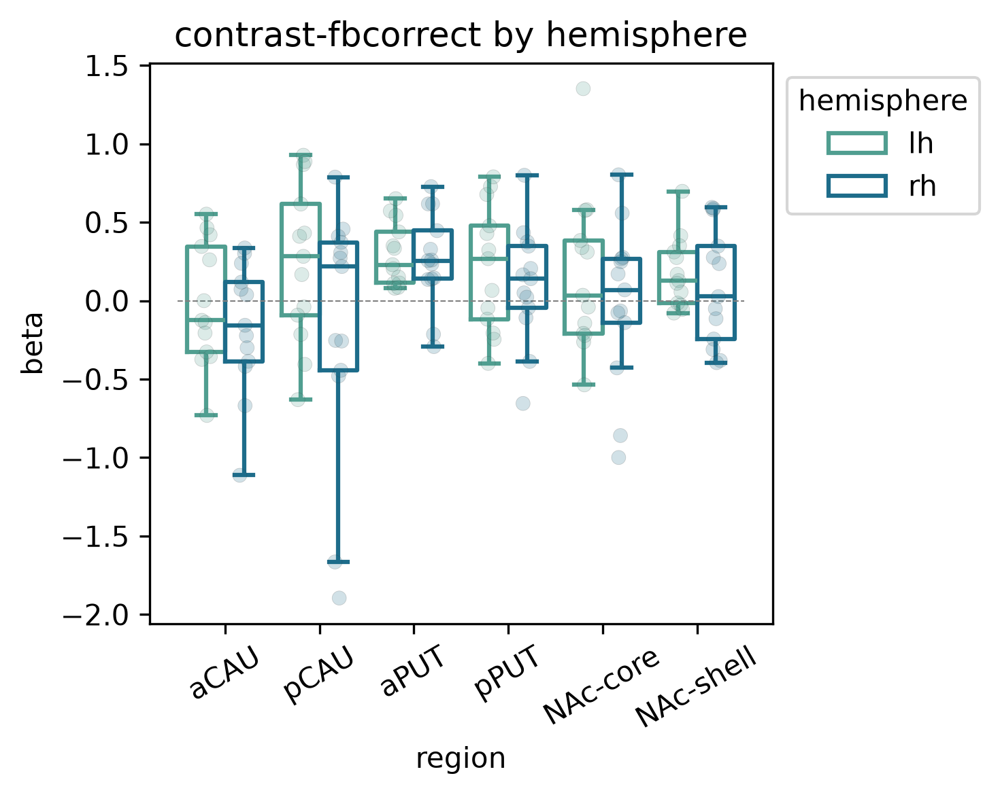

In [186]:
fig, ax = plt.subplots(1, 1, figsize=(5,4), dpi=300)

roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'hemisphere'], 
                                       as_index=False).agg({"beta": "mean"})

sns.boxplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='hemisphere', #hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              fliersize = 0,            
              linewidth=1.5,
              fill=False,
              #legend=None,
              ax=ax);
sns.stripplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='hemisphere', #hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              dodge=True,
              linewidth=0.2,
              alpha=.2,
              legend=None,
              ax=ax);


xmin, xmax = ax.get_xlim()
ax.hlines(y=0, xmin=xmin, xmax=xmax, color='0.5', linestyle='--', linewidth=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f'contrast-{contrast_label} by hemisphere');
#ax.set_ylim([-5, 5])

fig.tight_layout()

fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-hemisphere.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-hemisphere.png'))

### Brain-behavior correlations

In [187]:
# map runs to learning stages matching your thirds
stage_map = {'run-01': 'early', 'run-02': 'early',
             'run-03': 'middle', 'run-04': 'middle',
             'run-05': 'final', 'run-06': 'final'}

acc_df['learning_stage'] = acc_df['run'].map(stage_map)
acc_stage_df = acc_df.groupby(['participant_id', 'learning_stage'])['accuracy'].mean().reset_index()

In [188]:
# merge into roi_df_long — assumes participant_id and learning_stage columns exist in both
roi_df_bilateral = (roi_df_long.groupby(['participant_id', 'region', 'learning_stage'], as_index=False)['beta'].mean())
roi_behav_df = roi_df_bilateral.merge(acc_stage_df, on=['participant_id', 'learning_stage'])

# verify
roi_behav_df.groupby(['region', 'learning_stage']).size().unique()  # should be one row per participant


array([13])

In [189]:
roi_behav_df.columns

Index(['participant_id', 'region', 'learning_stage', 'beta', 'accuracy'], dtype='str')

In [190]:
roi_behav_df.participant_id.unique()

<StringArray>
['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17',
 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24',
 'sub-FLT26']
Length: 13, dtype: str

In [191]:
results = []
for stage in ['early', 'middle', 'final']:
    stage_df = roi_behav_df[roi_behav_df['learning_stage'] == stage]
    for roi in stage_df['region'].unique():
        sub_df = stage_df[stage_df['region'] == roi]
        r = pg.corr(sub_df['accuracy'], sub_df['beta'], method='pearson')
        results.append({
            'roi': roi,
            'learning_stage': stage,
            'r': r['r'].values[0],
            'p': r['p_val'].values[0],
            'n': r['n'].values[0],
            'stat_str': stat_str('r', r['r'].values[0], r['p_val'].values[0])
        })

behav_corr_df = pd.DataFrame(results)

In [192]:
behav_corr_df

,roi,learning_stage,r,p,n,stat_str
0,NAc-core,early,-0.1772,0.5625,13,"r = -.18, p = .563"
1,NAc-shell,early,-0.2355,0.4386,13,"r = -.24, p = .439"
2,aCAU,early,0.2183,0.4737,13,"r = .22, p = .474"
3,aPUT,early,-0.0077,0.9802,13,"r = -.01, p = .980"
4,pCAU,early,0.2875,0.3408,13,"r = .29, p = .341"
5,pPUT,early,0.4021,0.1732,13,"r = .40, p = .173"
6,NAc-core,middle,0.0442,0.8860,13,"r = .04, p = .886"
7,NAc-shell,middle,-0.0663,0.8296,13,"r = -.07, p = .830"
8,aCAU,middle,-0.0172,0.9555,13,"r = -.02, p = .956"
9,aPUT,middle,0.0250,0.9354,13,"r = .02, p = .935"


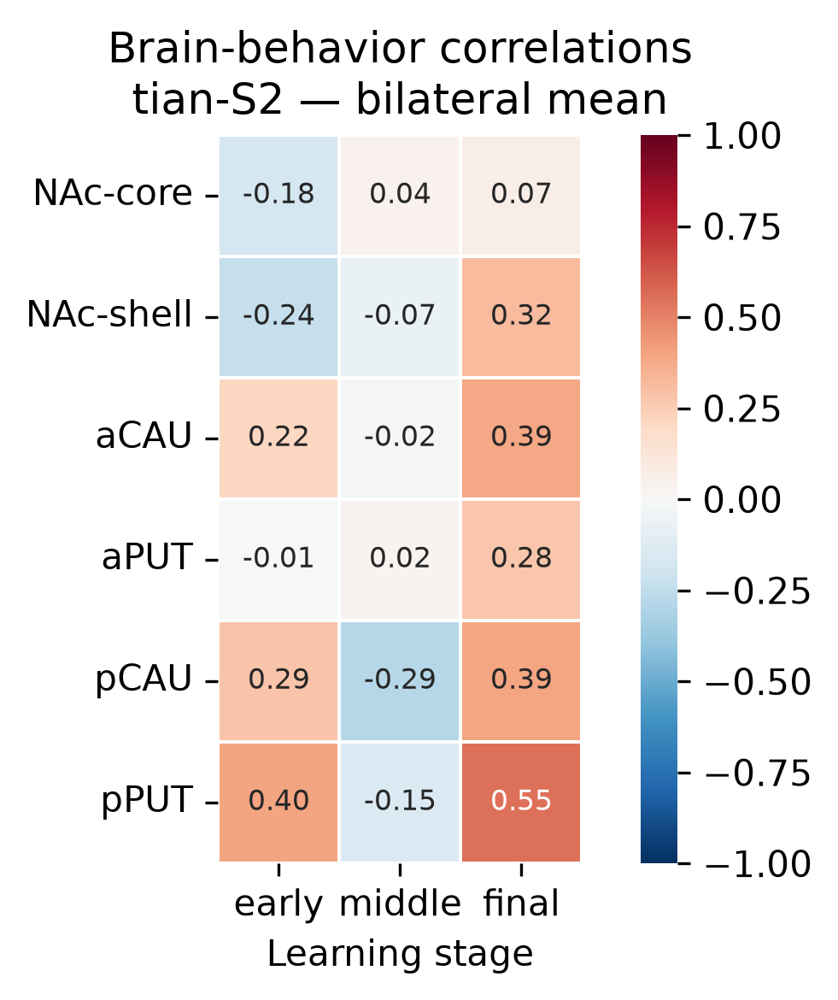

In [193]:
# pivot to ROI × stage matrix
r_matrix = behav_corr_df.pivot(index='roi', columns='learning_stage', values='r')[['early', 'middle', 'final']]
p_matrix = behav_corr_df.pivot(index='roi', columns='learning_stage', values='p')[['early', 'middle', 'final']]

fig, ax = plt.subplots(figsize=(5, len(r_matrix) * 0.5 + 1), dpi=300)
sns.heatmap(r_matrix, ax=ax, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot=True, fmt='.2f', annot_kws={'size': 8},
            square=True)

# mark significant cells with an asterisk
for i, roi in enumerate(r_matrix.index):
    for j, stage in enumerate(['early', 'middle', 'final']):
        p = p_matrix.loc[roi, stage]
        if p < 0.05:
            ax.text(j + 0.5, i + 0.85, '*', ha='center', va='center',
                    fontsize=12, color='black')

ax.set_title(f'Brain-behavior correlations\n{network_name} — bilateral mean')
ax.set_ylabel('')
ax.set_xlabel('Learning stage')
plt.tight_layout()
plt.savefig(os.path.join(fig_out_dir, f'brain-behav-corr_contrast-{contrast_label}_network-{network_name}_heatmap.svg'))

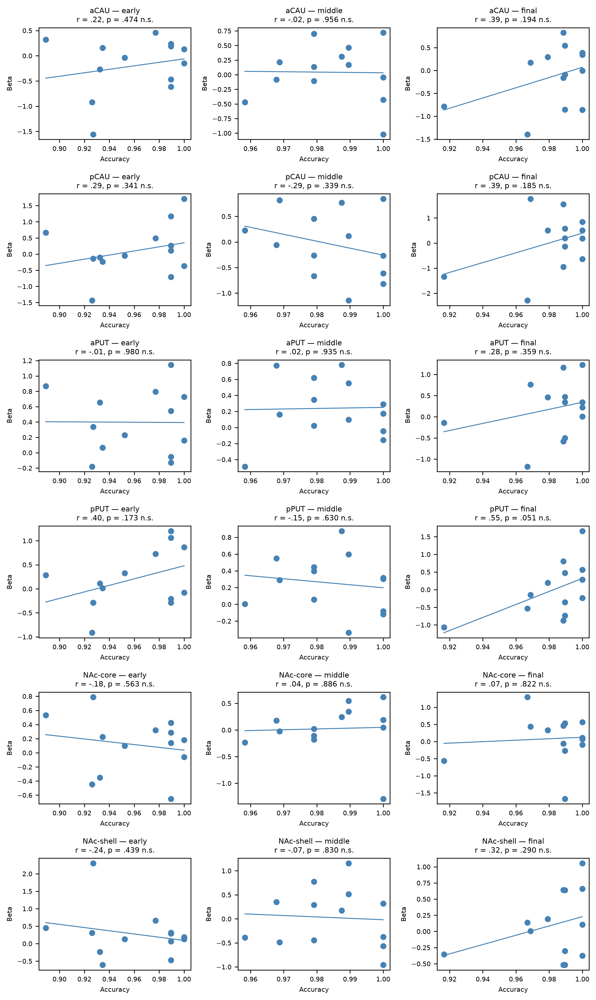

In [194]:
rois = behav_corr_df['roi'].unique()
stages = ['early', 'middle', 'final']

fig, axes = plt.subplots(len(rois), 3, figsize=(9, len(rois) * 2.5), dpi=300, sharex=False, sharey=False)

for ri, roi in enumerate(plot_order): # rois):
    for si, stage in enumerate(stages):
        ax = axes[ri, si]
        sub_df = roi_behav_df[(roi_behav_df['region'] == roi) & 
                              (roi_behav_df['learning_stage'] == stage)]
        
        ax.scatter(sub_df['accuracy'], sub_df['beta'], s=30, color='steelblue', zorder=3)
        
        # regression line
        m, b = np.polyfit(sub_df['accuracy'], sub_df['beta'], 1)
        x_range = np.linspace(sub_df['accuracy'].min(), sub_df['accuracy'].max(), 100)
        ax.plot(x_range, m * x_range + b, color='steelblue', linewidth=1)
        
        # stat annotation
        row = behav_corr_df[(behav_corr_df['roi'] == roi) & 
                            (behav_corr_df['learning_stage'] == stage)].iloc[0]
        p_str = '*' if row['p'] < 0.05 else 'n.s.'
        ax.set_title(f"{roi} — {stage}\n{row['stat_str']} {p_str}", fontsize=8)
        ax.set_xlabel('Accuracy', fontsize=7)
        ax.set_ylabel('Beta', fontsize=7)
        ax.tick_params(labelsize=7)

plt.tight_layout()
plt.savefig(os.path.join(fig_out_dir, f'brain-behav-corr_contrast-{contrast_label}_network-{network_name}_corr-plots.svg'))

NAc-core early: r = -.18, p = .563 n.s.
NAc-core middle: r = .04, p = .886 n.s.
NAc-core final: r = .07, p = .822 n.s.
NAc-shell early: r = -.24, p = .439 n.s.
NAc-shell middle: r = -.07, p = .830 n.s.
NAc-shell final: r = .32, p = .290 n.s.
aCAU early: r = .22, p = .474 n.s.
aCAU middle: r = -.02, p = .956 n.s.
aCAU final: r = .39, p = .194 n.s.
aPUT early: r = -.01, p = .980 n.s.
aPUT middle: r = .02, p = .935 n.s.
aPUT final: r = .28, p = .359 n.s.
pCAU early: r = .29, p = .341 n.s.
pCAU middle: r = -.29, p = .339 n.s.
pCAU final: r = .39, p = .185 n.s.
pPUT early: r = .40, p = .173 n.s.
pPUT middle: r = -.15, p = .630 n.s.
pPUT final: r = .55, p = .051 n.s.


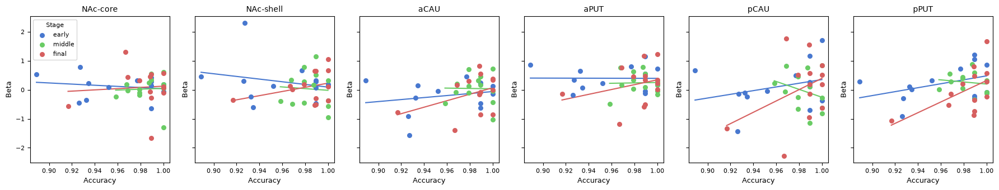

In [195]:
stage_colors = {'early': '#4878CF', 'middle': '#6ACC65', 'final': '#D65F5F'}
stages = ['early', 'middle', 'final']
rois = behav_corr_df['roi'].unique()

fig, axes = plt.subplots(1, len(rois), figsize=(3 * len(rois), 3.5), dpi=100, sharey=True)
if len(rois) == 1:
    axes = [axes]

for ri, roi in enumerate(rois):
    ax = axes[ri]
    for stage in stages:
        color = stage_colors[stage]
        sub_df = roi_behav_df[(roi_behav_df['region'] == roi) &
                              (roi_behav_df['learning_stage'] == stage)]

        ax.scatter(sub_df['accuracy'], sub_df['beta'], s=30,
                   color=color, label=stage, zorder=3)

        m, b = np.polyfit(sub_df['accuracy'], sub_df['beta'], 1)
        x_range = np.linspace(sub_df['accuracy'].min(), sub_df['accuracy'].max(), 100)
        ax.plot(x_range, m * x_range + b, color=color, linewidth=1.5)

        # stat annotation per stage
        row = behav_corr_df[(behav_corr_df['roi'] == roi) &
                            (behav_corr_df['learning_stage'] == stage)].iloc[0]
        p_str = '*' if row['p'] < 0.05 else 'n.s.'
        print(f"{roi} {stage}: {row['stat_str']} {p_str}")

    ax.set_title(roi, fontsize=10)
    ax.set_xlabel('Accuracy', fontsize=9)
    ax.set_ylabel('Beta', fontsize=9)
    ax.tick_params(labelsize=8)

axes[0].legend(title='Stage', fontsize=8, title_fontsize=8)
plt.tight_layout()


### omnibus ANOVA stats

In [196]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import AnovaRM
import pingouin as pg

In [197]:
group_df.head()

,participant_id,participant_group,region,beta,region_hemi,hemisphere,learning_stage,Axis
0,sub-FLT03,Mandarin,aCAU,-1.2554,aCAU-lh,lh,early,Rostral
1,sub-FLT03,Mandarin,aCAU,0.3354,aCAU-lh,lh,middle,Rostral
2,sub-FLT03,Mandarin,aCAU,-1.2734,aCAU-lh,lh,final,Rostral
3,sub-FLT03,Mandarin,pCAU,0.5537,pCAU-lh,lh,early,Caudal
4,sub-FLT03,Mandarin,pCAU,0.1700,pCAU-lh,lh,middle,Caudal


In [198]:
group_df.participant_id.unique()

<StringArray>
['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17',
 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24',
 'sub-FLT26']
Length: 13, dtype: str

In [199]:
# Mixed-Effects ANOVA with Hemisphere, Region, and Interaction
aov = AnovaRM(group_df, 
              aggregate_func='mean',
              depvar='beta', 
              subject='participant_id', 
              within=['hemisphere', 'learning_stage','region', ]).fit()

# Display results
print('network:', network_name)
print('contrast:', contrast_label)
aov.summary()

network: tian-S2
contrast: fbcorrect


,F Value,Num DF,Den DF,Pr > F
hemisphere,8.2852,1.0000,12.0000,0.0139
learning_stage,0.1689,2.0000,24.0000,0.8456
region,2.0397,5.0000,60.0000,0.0858
hemisphere:learning_stage,1.8416,2.0000,24.0000,0.1803
hemisphere:region,1.3314,5.0000,60.0000,0.2633
learning_stage:region,0.5967,10.0000,120.0000,0.8140
hemisphere:learning_stage:region,0.4398,10.0000,120.0000,0.9241


In [200]:
export_anova(aov, f'{contrast_label}_{network_name}_hemisphere_learning-stage_region', stats_out_dir)

,source,F,df_num,df_den,p,stat_str
0,hemisphere,8.29,1.0000,12.0000,p = .014,"F(1, 12) = 8.29, p = .014"
1,learning_stage,0.17,2.0000,24.0000,p = .846,"F(2, 24) = 0.17, p = .846"
2,region,2.04,5.0000,60.0000,p = .086,"F(5, 60) = 2.04, p = .086"
3,hemisphere:learning_stage,1.84,2.0000,24.0000,p = .180,"F(2, 24) = 1.84, p = .180"
4,hemisphere:region,1.33,5.0000,60.0000,p = .263,"F(5, 60) = 1.33, p = .263"
5,learning_stage:region,0.60,10.0000,120.0000,p = .814,"F(10, 120) = 0.60, p = .814"
6,hemisphere:learning_stage:region,0.44,10.0000,120.0000,p = .924,"F(10, 120) = 0.44, p = .924"


In [201]:
# GG-corrected bilateral replication (learning_stage x region)
bilateral_df = (group_df
                .groupby(['participant_id', 'region', 'learning_stage'], as_index=False)['beta']
                .mean())
aov_pg = pg.rm_anova(data=bilateral_df, dv='beta',
                     within=['learning_stage', 'region'],
                     subject='participant_id',
                     detailed=True)
eta_col = 'np2' if 'np2' in aov_pg.columns else 'ng2'
print(aov_pg[['Source', 'F', 'ddof1', 'ddof2', 'p_unc', 'p_GG_corr', eta_col]])
export_pg_anova(aov_pg, f'{contrast_label}_{network_name}_learning-stage_region_bilateral', stats_out_dir)

                    Source      F  ddof1  ddof2  p_unc  p_GG_corr    ng2
0           learning_stage 0.1689      2     24 0.8456     0.8422 0.0042
1                   region 2.0397      5     60 0.0858     0.1313 0.0336
2  learning_stage * region 0.5967     10    120 0.8140     0.6063 0.0158


/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/pingouin/distribution.py:514: UserWarning: Epsilon values might be innaccurate in two-way repeated measures design where each  factor has more than 2 levels. Please  double-check your results.
  warnings.warn(


,source,df_num,df_den,F,p_unc,p_GG_corr,eta_p2,stat_str
0,learning_stage,2,24,0.17,p = .846,p = .842,0.00,"F(2, 24) = 0.17, p = .842"
1,region,5,60,2.04,p = .086,p = .131,0.03,"F(5, 60) = 2.04, p = .131"
2,learning_stage * region,10,120,0.60,p = .814,p = .606,0.02,"F(10, 120) = 0.60, p = .606"


In [202]:
import pingouin as pg

# Pairwise comparisons for region with FDR correction
pairwise_by_learning_stage = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['learning_stage','region', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_learning_stage.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_learning_stage)
#pairwise_by_learning_stage[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_learning_stage[pairwise_by_learning_stage.Contrast.str.contains(' * ')].reset_index()
pairwise_interaction = pairwise_interaction[pairwise_interaction['p_unc'] < 0.05].reset_index()
pairwise_interaction[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'learning_stage', 'A', 'B', 'Paired', 'Parametric', 'T',
       'dof', 'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,learning_stage,A,B,T,dof,p_unc,p_corr,BF10
0,learning_stage * region,early,aCAU,aPUT,-3.3355,12.0000,0.0059,0.2672,8.886
1,learning_stage * region,early,aCAU,pPUT,-2.3893,12.0000,0.0342,0.4860,2.167
2,learning_stage * region,final,aCAU,aPUT,-2.7022,12.0000,0.0192,0.4327,3.415


In [203]:
# pairwise by region

# Pairwise comparisons for region with FDR correction
pairwise_by_region = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['region', 'learning_stage',],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_region.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_region)
#pairwise_by_region[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_region[pairwise_by_region.Contrast.str.contains(' * ')].reset_index()
pairwise_interaction = pairwise_interaction[pairwise_interaction['p_unc'] < 0.05]
pairwise_interaction[['Contrast', 'region', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'region', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof',
       'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,region,A,B,T,dof,p_unc,p_corr,BF10


In [204]:
export_posthoc(pairwise_by_region, f'{contrast_label}_{network_name}_region_learning-stage', stats_out_dir)

,Contrast,region,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,region,-,NAc-core,NAc-shell,-0.71,12.0000,p = .488,p = .611,"t(12) = -0.71, p = .488","t(12) = -0.71, q = .611"
1,region,-,NAc-core,aCAU,1.48,12.0000,p = .165,p = .308,"t(12) = 1.48, p = .165","t(12) = 1.48, q = .308"
2,region,-,NAc-core,aPUT,-2.12,12.0000,p = .055,p = .277,"t(12) = -2.12, p = .055","t(12) = -2.12, q = .277"
3,region,-,NAc-core,pCAU,0.19,12.0000,p = .849,p = .849,"t(12) = 0.19, p = .849","t(12) = 0.19, q = .849"
4,region,-,NAc-core,pPUT,-0.72,12.0000,p = .486,p = .611,"t(12) = -0.72, p = .486","t(12) = -0.72, q = .611"
5,region,-,NAc-shell,aCAU,1.81,12.0000,p = .096,p = .286,"t(12) = 1.81, p = .096","t(12) = 1.81, q = .286"
6,region,-,NAc-shell,aPUT,-1.72,12.0000,p = .110,p = .286,"t(12) = -1.72, p = .110","t(12) = -1.72, q = .286"
7,region,-,NAc-shell,pCAU,0.57,12.0000,p = .578,p = .667,"t(12) = 0.57, p = .578","t(12) = 0.57, q = .667"
8,region,-,NAc-shell,pPUT,-0.22,12.0000,p = .827,p = .849,"t(12) = -0.22, p = .827","t(12) = -0.22, q = .849"
9,region,-,aCAU,aPUT,-4.80,12.0000,p < .001,p = .006,"t(12) = -4.80, p < .001","t(12) = -4.80, q = .006"


In [205]:
# pairwise by region, no learning stage

# Pairwise comparisons for region with FDR correction
pairwise_by_region_only = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['region', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_region_only.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_region_only)
pairwise_by_region_only = pairwise_by_region_only[pairwise_by_region_only['p_unc'] < 0.05]
pairwise_by_region_only[['Contrast', 'Contrast', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns


Available columns: Index(['Contrast', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof', 'alternative',
       'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,Contrast,A,B,T,dof,p_unc,p_corr,BF10
9,region,region,aCAU,aPUT,-4.8027,12.0000,0.0004,0.0065,81.291
11,region,region,aCAU,pPUT,-2.3639,12.0000,0.0358,0.2685,2.09


In [206]:
export_posthoc(pairwise_by_region_only, f'{contrast_label}_{network_name}_region', stats_out_dir)

,Contrast,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
9,region,aCAU,aPUT,-4.80,12.0000,p < .001,p = .006,"t(12) = -4.80, p < .001","t(12) = -4.80, q = .006"
11,region,aCAU,pPUT,-2.36,12.0000,p = .036,p = .268,"t(12) = -2.36, p = .036","t(12) = -2.36, q = .268"


### Collapse (average) over non-significant factors

In [207]:
roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'learning_stage'], 
                                       as_index=False).agg({"beta": "mean"})


In [208]:
# Collect results
results = []

# average within participant first: one value per participant, so n (and df) = number of participants
for region, data in (roi_df_collapsed.groupby(["participant_id", "region"], as_index=False)["beta"].mean()
                     .groupby("region")):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    results.append({
        "region": region,
        "t_stat": t_stat,
        "p_val": p_val
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Apply FDR correction
results_df["p_val_fdr"] = multipletests(results_df["p_val"], method="fdr_bh")[1]

# Print or export the table
results_df

# Optional: export
# results_df.to_csv("roi_stats.csv", index=False)
# results_df.to_excel("roi_stats.xlsx", index=False)


,region,t_stat,p_val,p_val_fdr
0,NAc-core,0.7298,0.4795,0.5754
1,NAc-shell,1.7615,0.1036,0.2857
2,aCAU,-0.9286,0.3714,0.5571
3,aPUT,4.2340,0.0012,0.0070
4,pCAU,0.2327,0.8199,0.8199
5,pPUT,1.5681,0.1428,0.2857


In [209]:
_export = results_df.rename(columns={'t_stat': 't', 'p_val': 'p'}).copy()
_export['df'] = len(sub_list) - 1
export_ttests(_export.to_dict('records'), f'{contrast_label}_{network_name}_baseline_by_region', stats_out_dir)

,region,t,p,p_val_fdr,df,p_fdr,stat_str,stat_str_fdr
0,NAc-core,0.73,p = .480,0.5754,12,p = .575,"t(12) = 0.73, p = .480","t(12) = 0.73, q = .575"
1,NAc-shell,1.76,p = .104,0.2857,12,p = .286,"t(12) = 1.76, p = .104","t(12) = 1.76, q = .286"
2,aCAU,-0.93,p = .371,0.5571,12,p = .557,"t(12) = -0.93, p = .371","t(12) = -0.93, q = .557"
3,aPUT,4.23,p = .001,0.0070,12,p = .007,"t(12) = 4.23, p = .001","t(12) = 4.23, q = .007"
4,pCAU,0.23,p = .820,0.8199,12,p = .820,"t(12) = 0.23, p = .820","t(12) = 0.23, q = .820"
5,pPUT,1.57,p = .143,0.2857,12,p = .286,"t(12) = 1.57, p = .143","t(12) = 1.57, q = .286"


In [210]:
# Collect results
results = []

for (region, stage), data in roi_df_collapsed.groupby(["region", "learning_stage"]):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    results.append({
        "region": region,
        "learning_stage": stage,
        "t_stat": t_stat,
        "p_val": p_val
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Apply FDR correction
results_df["p_val_fdr"] = multipletests(results_df["p_val"], method="fdr_bh")[1]

stage_order = ["early", "middle", "final"]

results_df["learning_stage"] = pd.Categorical(
    results_df["learning_stage"],
    categories=stage_order,
    ordered=True
)

# Now sort
results_df = results_df.sort_values(["learning_stage", "region"])


# Print or export the table
results_df

# Optional: export
# results_df.to_csv("roi_stats.csv", index=False)
# results_df.to_excel("roi_stats.xlsx", index=False)


,region,learning_stage,t_stat,p_val,p_val_fdr
0,NAc-core,early,1.0144,0.3304,0.7434
3,NAc-shell,early,1.3804,0.1926,0.7259
6,aCAU,early,-1.2308,0.2420,0.7259
9,aPUT,early,3.3815,0.0055,0.0982
12,pCAU,early,0.4752,0.6432,0.9289
15,pPUT,early,1.2752,0.2264,0.7259
2,NAc-core,middle,0.2057,0.8405,0.9289
5,NAc-shell,middle,0.1577,0.8773,0.9289
8,aCAU,middle,0.3150,0.7582,0.9289
11,aPUT,middle,2.3193,0.0388,0.2329


In [211]:
_export = results_df.rename(columns={'t_stat': 't', 'p_val': 'p'}).copy()
_export['df'] = len(sub_list) - 1
export_ttests(_export.to_dict('records'), f'{contrast_label}_{network_name}_baseline_by_region_stage', stats_out_dir)

,region,learning_stage,t,p,p_val_fdr,df,p_fdr,stat_str,stat_str_fdr
0,NAc-core,early,1.01,p = .330,0.7434,12,p = .743,"t(12) = 1.01, p = .330","t(12) = 1.01, q = .743"
1,NAc-shell,early,1.38,p = .193,0.7259,12,p = .726,"t(12) = 1.38, p = .193","t(12) = 1.38, q = .726"
2,aCAU,early,-1.23,p = .242,0.7259,12,p = .726,"t(12) = -1.23, p = .242","t(12) = -1.23, q = .726"
3,aPUT,early,3.38,p = .005,0.0982,12,p = .098,"t(12) = 3.38, p = .005","t(12) = 3.38, q = .098"
4,pCAU,early,0.48,p = .643,0.9289,12,p = .929,"t(12) = 0.48, p = .643","t(12) = 0.48, q = .929"
5,pPUT,early,1.28,p = .226,0.7259,12,p = .726,"t(12) = 1.28, p = .226","t(12) = 1.28, q = .726"
6,NAc-core,middle,0.21,p = .841,0.9289,12,p = .929,"t(12) = 0.21, p = .841","t(12) = 0.21, q = .929"
7,NAc-shell,middle,0.16,p = .877,0.9289,12,p = .929,"t(12) = 0.16, p = .877","t(12) = 0.16, q = .929"
8,aCAU,middle,0.32,p = .758,0.9289,12,p = .929,"t(12) = 0.32, p = .758","t(12) = 0.32, q = .929"
9,aPUT,middle,2.32,p = .039,0.2329,12,p = .233,"t(12) = 2.32, p = .039","t(12) = 2.32, q = .233"


In [212]:
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_1samp


# Collect p-values
p_values = []
t_stats = []
comparisons = []

for region_stage, data in roi_df_collapsed.groupby(['learning_stage', "region",]):
    #print(region_stage)
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    p_values.append(p_val)
    comparisons.append((region_stage[0], region_stage[1], t_stat))
    t_stats.append(t_stat)

# Apply FDR correction
_, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Print corrected results
for (region, stage, t_stat), p_val_corr in zip(comparisons, p_corrected):
    print(f"Region: {region}, stage: {stage}, t = {t_stat:.2f}; corrected p = {p_val_corr:.4f}")


Region: early, stage: NAc-core, t = 1.01; corrected p = 0.7434
Region: early, stage: NAc-shell, t = 1.38; corrected p = 0.7259
Region: early, stage: aCAU, t = -1.23; corrected p = 0.7259
Region: early, stage: aPUT, t = 3.38; corrected p = 0.0982
Region: early, stage: pCAU, t = 0.48; corrected p = 0.9289
Region: early, stage: pPUT, t = 1.28; corrected p = 0.7259
Region: final, stage: NAc-core, t = 0.45; corrected p = 0.9289
Region: final, stage: NAc-shell, t = 0.73; corrected p = 0.9289
Region: final, stage: aCAU, t = -0.67; corrected p = 0.9289
Region: final, stage: aPUT, t = 1.05; corrected p = 0.7434
Region: final, stage: pCAU, t = 0.19; corrected p = 0.9289
Region: final, stage: pPUT, t = 0.01; corrected p = 0.9950
Region: middle, stage: NAc-core, t = 0.21; corrected p = 0.9289
Region: middle, stage: NAc-shell, t = 0.16; corrected p = 0.9289
Region: middle, stage: aCAU, t = 0.32; corrected p = 0.9289
Region: middle, stage: aPUT, t = 2.32; corrected p = 0.2329
Region: middle, stage: 

In [213]:
# Compare early vs. final
results = []

for region, data in roi_df_collapsed.groupby("region"):

    # Extract paired early/final beta values
    early = data.loc[data.learning_stage == "early", "beta"].values
    final = data.loc[data.learning_stage == "final", "beta"].values
    
    t_stat, p_val = ttest_rel(final, early)
    results.append({
        "region": region,
        "t_stat": t_stat,
        "p_val": p_val
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Apply FDR correction
results_df["p_val_fdr"] = multipletests(results_df["p_val"], method="fdr_bh")[1]

stage_order = ["early", "middle", "final"]

'''
results_df["learning_stage"] = pd.Categorical(
    results_df["learning_stage"],
    categories=stage_order,
    ordered=True
)
'''

# Now sort
results_df = results_df.sort_values(["region"])


# Print or export the table
results_df

# Optional: export
# results_df.to_csv("roi_stats.csv", index=False)
# results_df.to_excel("roi_stats.xlsx", index=False)


,region,t_stat,p_val,p_val_fdr
0,NAc-core,-0.1342,0.8955,0.8955
1,NAc-shell,-0.6063,0.5556,0.8955
2,aCAU,0.3920,0.7019,0.8955
3,aPUT,-0.7548,0.4649,0.8955
4,pCAU,-0.1364,0.8937,0.8955
5,pPUT,-0.8342,0.4205,0.8955


In [214]:
_export = results_df.rename(columns={'t_stat': 't', 'p_val': 'p'}).copy()
_export['df'] = len(sub_list) - 1
export_ttests(_export.to_dict('records'), f'{contrast_label}_{network_name}_early_vs_final', stats_out_dir)

,region,t,p,p_val_fdr,df,p_fdr,stat_str,stat_str_fdr
0,NAc-core,-0.13,p = .895,0.8955,12,p = .895,"t(12) = -0.13, p = .895","t(12) = -0.13, q = .895"
1,NAc-shell,-0.61,p = .556,0.8955,12,p = .895,"t(12) = -0.61, p = .556","t(12) = -0.61, q = .895"
2,aCAU,0.39,p = .702,0.8955,12,p = .895,"t(12) = 0.39, p = .702","t(12) = 0.39, q = .895"
3,aPUT,-0.75,p = .465,0.8955,12,p = .895,"t(12) = -0.75, p = .465","t(12) = -0.75, q = .895"
4,pCAU,-0.14,p = .894,0.8955,12,p = .895,"t(12) = -0.14, p = .894","t(12) = -0.14, q = .895"
5,pPUT,-0.83,p = .420,0.8955,12,p = .895,"t(12) = -0.83, p = .420","t(12) = -0.83, q = .895"


In [215]:
# Compare early vs. final
roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'learning_stage'], 
                                       as_index=False).agg({"beta": "mean"})

# Collect p-values
p_values = []
t_stats = []
comparisons = []

for region_stage, data in roi_df_collapsed.groupby(["region"]):
    t_stat, p_val = ttest_rel(data[data.learning_stage=='final']['beta'], 
                              data[data.learning_stage=='early']['beta'])
    p_values.append(p_val)
    comparisons.append((region_stage[0], t_stat))
    t_stats.append(t_stat)

# Apply FDR correction
_, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Print corrected results
for (region, t_stat), p_val_corr in zip(comparisons, p_corrected):
    print(f"Region: {region}, final vs. early stage, t = {t_stat:.2f} ; corrected p = {p_val_corr:.4f}")



Region: NAc-core, final vs. early stage, t = -0.13 ; corrected p = 0.8955
Region: NAc-shell, final vs. early stage, t = -0.61 ; corrected p = 0.8955
Region: aCAU, final vs. early stage, t = 0.39 ; corrected p = 0.8955
Region: aPUT, final vs. early stage, t = -0.75 ; corrected p = 0.8955
Region: pCAU, final vs. early stage, t = -0.14 ; corrected p = 0.8955
Region: pPUT, final vs. early stage, t = -0.83 ; corrected p = 0.8955


In [216]:
_records = [{'region': c[0], 't': c[1], 'df': len(sub_list) - 1, 'p': p}
            for c, p in zip(comparisons, p_values)]
export_ttests(_records, f'{contrast_label}_{network_name}_early_vs_final', stats_out_dir)

,region,t,df,p,p_fdr,stat_str,stat_str_fdr
0,NAc-core,-0.13,12,p = .895,p = .895,"t(12) = -0.13, p = .895","t(12) = -0.13, q = .895"
1,NAc-shell,-0.61,12,p = .556,p = .895,"t(12) = -0.61, p = .556","t(12) = -0.61, q = .895"
2,aCAU,0.39,12,p = .702,p = .895,"t(12) = 0.39, p = .702","t(12) = 0.39, q = .895"
3,aPUT,-0.75,12,p = .465,p = .895,"t(12) = -0.75, p = .465","t(12) = -0.75, q = .895"
4,pCAU,-0.14,12,p = .894,p = .895,"t(12) = -0.14, p = .894","t(12) = -0.14, q = .895"
5,pPUT,-0.83,12,p = .420,p = .895,"t(12) = -0.83, p = .420","t(12) = -0.83, q = .895"


In [217]:
# Collapse/ignore learning stage
roi_df_collapsed_stage = roi_df_long.groupby(["participant_id", "region"], 
                                       as_index=False).agg({"beta": "mean"})

# Collect p-values
p_values = []
t_stats = []
comparisons = []

for region, data in roi_df_collapsed_stage.groupby(["region"]):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    p_values.append(p_val)
    comparisons.append((region[0], t_stat))
    t_stats.append(t_stat)

# Apply FDR correction
_, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Print corrected results
for (region, t_stat), p_val_corr in zip(comparisons, p_corrected):
    print(f"Region: {region}, t = {t_stat:.2f}; corrected p = {p_val_corr:.4f}")


Region: NAc-core, t = 0.73; corrected p = 0.5754
Region: NAc-shell, t = 1.76; corrected p = 0.2857
Region: aCAU, t = -0.93; corrected p = 0.5571
Region: aPUT, t = 4.23; corrected p = 0.0070
Region: pCAU, t = 0.23; corrected p = 0.8199
Region: pPUT, t = 1.57; corrected p = 0.2857


In [218]:
_records = [{'region': c[0], 't': c[1], 'df': len(sub_list) - 1, 'p': p}
            for c, p in zip(comparisons, p_values)]
export_ttests(_records, f'{contrast_label}_{network_name}_baseline_collapsed', stats_out_dir)

,region,t,df,p,p_fdr,stat_str,stat_str_fdr
0,NAc-core,0.73,12,p = .480,p = .575,"t(12) = 0.73, p = .480","t(12) = 0.73, q = .575"
1,NAc-shell,1.76,12,p = .104,p = .286,"t(12) = 1.76, p = .104","t(12) = 1.76, q = .286"
2,aCAU,-0.93,12,p = .371,p = .557,"t(12) = -0.93, p = .371","t(12) = -0.93, q = .557"
3,aPUT,4.23,12,p = .001,p = .007,"t(12) = 4.23, p = .001","t(12) = 4.23, q = .007"
4,pCAU,0.23,12,p = .820,p = .820,"t(12) = 0.23, p = .820","t(12) = 0.23, q = .820"
5,pPUT,1.57,12,p = .143,p = .286,"t(12) = 1.57, p = .143","t(12) = 1.57, q = .286"


### Make 3D plots

In [219]:
roi_df_collapsed = roi_df_long.groupby(["participant_id", "region_hemi"], 
                                       as_index=False).agg({"beta": "mean"})

# Collect p-values
p_values = []
t_stats = []
comparisons = []

for region, data in roi_df_collapsed.groupby(["region_hemi"]):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    p_values.append(p_val)
    comparisons.append((region[0], t_stat))
    t_stats.append(t_stat)

# Apply FDR correction
_, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Print corrected results
for (region, t_stat), p_val_corr in zip(comparisons, p_corrected):
    print(f"Region: {region}, t = {t_stat:.2f}; corrected p = {p_val_corr:.4f}")


Region: NAc-core-lh, t = 1.21; corrected p = 0.4308
Region: NAc-core-rh, t = -0.10; corrected p = 0.9242
Region: NAc-shell-lh, t = 2.89; corrected p = 0.0546
Region: NAc-shell-rh, t = 0.86; corrected p = 0.5439
Region: aCAU-lh, t = -0.15; corrected p = 0.9242
Region: aCAU-rh, t = -1.44; corrected p = 0.3536
Region: aPUT-lh, t = 5.34; corrected p = 0.0021
Region: aPUT-rh, t = 3.13; corrected p = 0.0521
Region: pCAU-lh, t = 1.76; corrected p = 0.2505
Region: pCAU-rh, t = -0.74; corrected p = 0.5667
Region: pPUT-lh, t = 1.91; corrected p = 0.2421
Region: pPUT-rh, t = 1.01; corrected p = 0.4999


### Striatal ROI plot (t-statistic)

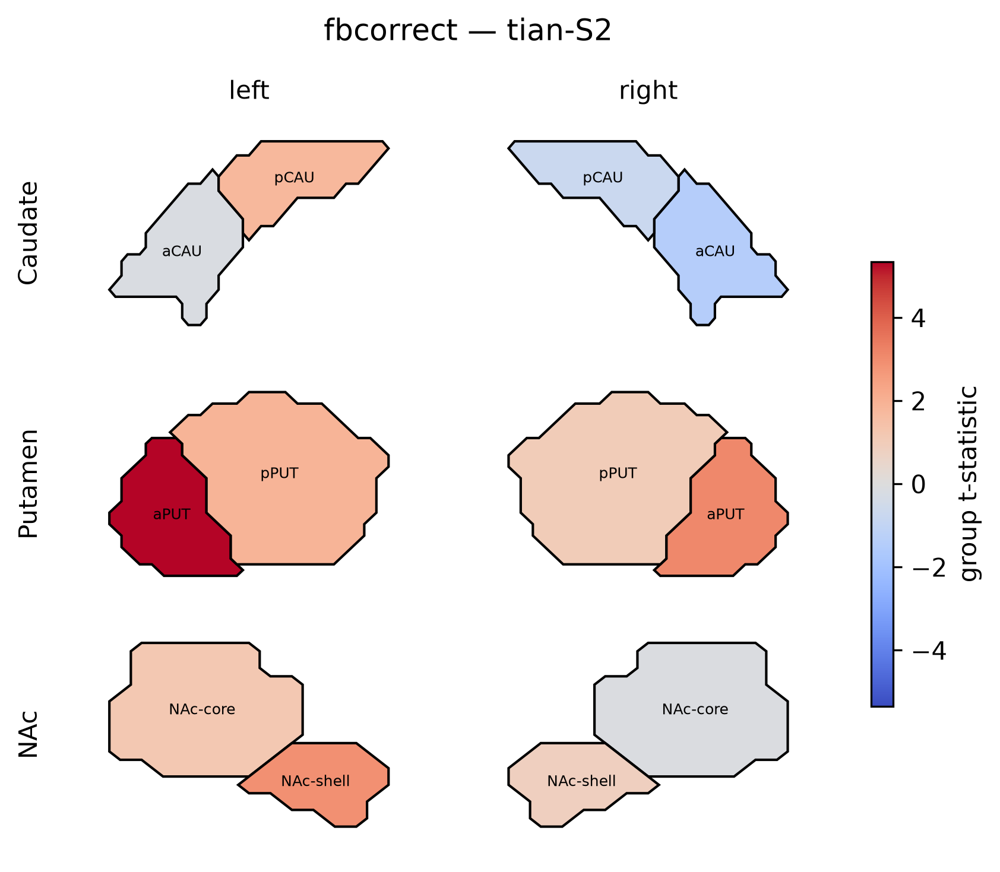

In [220]:
structure_groups = {
    'Caudate': ['aCAU', 'pCAU'],
    'Putamen': ['aPUT', 'pPUT'],
    'NAc': ['NAc-core', 'NAc-shell'],
}
stat_dict = {c[0]: c[1] for c in comparisons}
mask_path_dict = build_mask_path_dict(list(stat_dict.keys()), masks_dir, network_name, surf_space_label)

fig = plot_striatal_roi_stat(stat_dict, mask_path_dict, structure_groups, title=f'{contrast_label} — {network_name}')
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_striatal-tstat.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_striatal-tstat.png'))


### Striatal ROI plot (t-statistic) — yabplot alternative

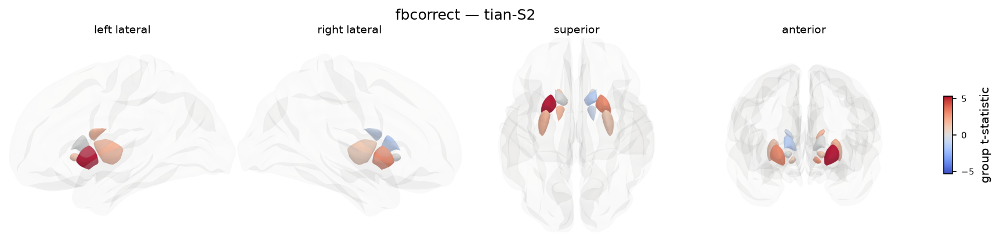

In [221]:
# yabplot 3D rendering of the same stat_dict, as an alternative to the
# 2D contour schematic above. See 05_masking/build_yabplot_tian_s2_atlas.py
# for building the atlas this depends on.
from striatal_yabplot import plot_striatal_roi_stat_yabplot

yabplot_out_png = os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_striatal-tstat_yabplot.png')
yabplot_atlas_dir = os.path.join(os.getcwd(), '..', '05_masking', 'yabplot_atlases', 'tian_S2')

fig = plot_striatal_roi_stat_yabplot(stat_dict, atlas_dir=yabplot_atlas_dir,
                                      title=f'{contrast_label} — {network_name}')
fig.savefig(yabplot_out_png)

In [222]:
#from IPython.display import Image
#Image(filename=yabplot_out_png)


### Striatal ROI plot (t-statistic, final vs. early)

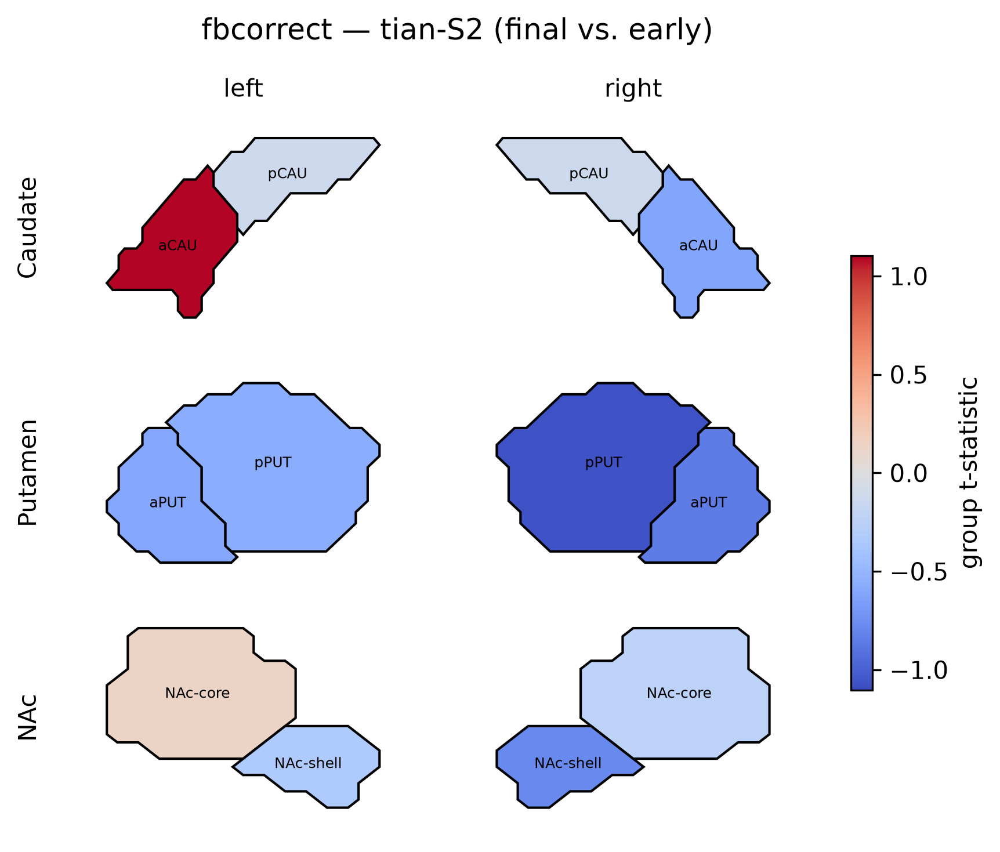

In [223]:
# Learning-stage difference (final vs. early)
_diff_df = (group_df[group_df['learning_stage'].isin(['early', 'final'])]
            .groupby(['participant_id', 'region_hemi', 'learning_stage'], as_index=False)['beta'].mean()
            .pivot(index=['participant_id', 'region_hemi'], columns='learning_stage', values='beta')
            .dropna()
            .reset_index())

diff_stat_dict = {}
for region_hemi, data in _diff_df.groupby('region_hemi'):
    t_stat, _ = ttest_rel(data['final'], data['early'])
    diff_stat_dict[region_hemi] = t_stat

structure_groups = {
    'Caudate': ['aCAU', 'pCAU'],
    'Putamen': ['aPUT', 'pPUT'],
    'NAc': ['NAc-core', 'NAc-shell'],
}
mask_path_dict_diff = build_mask_path_dict(list(diff_stat_dict.keys()), masks_dir, network_name, surf_space_label)
fig_diff = plot_striatal_roi_stat(diff_stat_dict, mask_path_dict_diff, structure_groups,
                                   title=f'{contrast_label} — {network_name} (final vs. early)')
fig_diff.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_striatal-tstat_diff-final-early.svg'))
fig_diff.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_striatal-tstat_diff-final-early.png'))


### Striatal ROI plot (t-statistic, final vs. early) — yabplot alternative

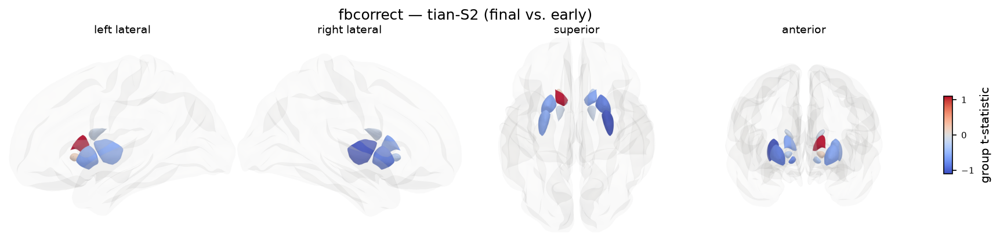

In [224]:
# yabplot 3D rendering of diff_stat_dict (final vs. early).
from striatal_yabplot import plot_striatal_roi_stat_yabplot

yabplot_out_png_diff = os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_striatal-tstat_diff-final-early_yabplot.png')
yabplot_atlas_dir = os.path.join(os.getcwd(), '..', '05_masking', 'yabplot_atlases', 'tian_S2')

fig = plot_striatal_roi_stat_yabplot(diff_stat_dict, atlas_dir=yabplot_atlas_dir,
                                      title=f'{contrast_label} — {network_name} (final vs. early)')
fig.savefig(yabplot_out_png_diff)

## `contrast-fb` for cortical network

In [225]:
# get the beta map for the contrast of interest for each subject
network_name = network_list[0]
contrast_label = contrast_list[2]
event_type = contrast_event_type[contrast_label]
print('network_name:', network_name)
print('contrast_label:', contrast_label)

network_name: auditory
contrast_label: fbcorrect


In [226]:
# per-group copy of the ROI table that the cells below (and robustness_checks.py) read
out_fname = f'univariate-results_network-{network_name}_contrast-{contrast_label}{group_suffix}.tsv'
combined_roi_df_fpath = os.path.join(group_out_dir, out_fname)

In [227]:
# this group's per-ROI values (from extract_roi_values.py), saved under the
# name the cells below and robustness_checks.py read
roi_df_long = load_roi_values(network_name, contrast_label)
roi_df_long.to_csv(combined_roi_df_fpath, sep='\t', index=False)
roi_df_long.groupby('learning_stage').participant_id.nunique()

learning_stage
early     13
final     13
middle    13
Name: participant_id, dtype: int64

In [228]:
# load the DataFrame if already exists
roi_df_long = pd.read_csv(combined_roi_df_fpath, sep='\t')

# create a bilateral-averaged dataframe (for across-contrast analysis)
feedback_cortex_df = bilateral_mean(roi_df_long)


In [229]:
roi_df_long.participant_id.unique()

<StringArray>
['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17',
 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24',
 'sub-FLT26']
Length: 13, dtype: str

In [230]:
roi_df_long.region.unique()

<StringArray>
['HG', 'PT', 'PP', 'STGp', 'STGa', 'ParsOp', 'ParsTri']
Length: 7, dtype: str

In [231]:
group_df = roi_df_long

In [232]:
plot_order = ['HG', 'PT', 'PP', 'STGp', 'STGa', 'ParsOp', 'ParsTri', ]

/scratch/slurm-12192413/ipykernel_2562235/2201273681.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')


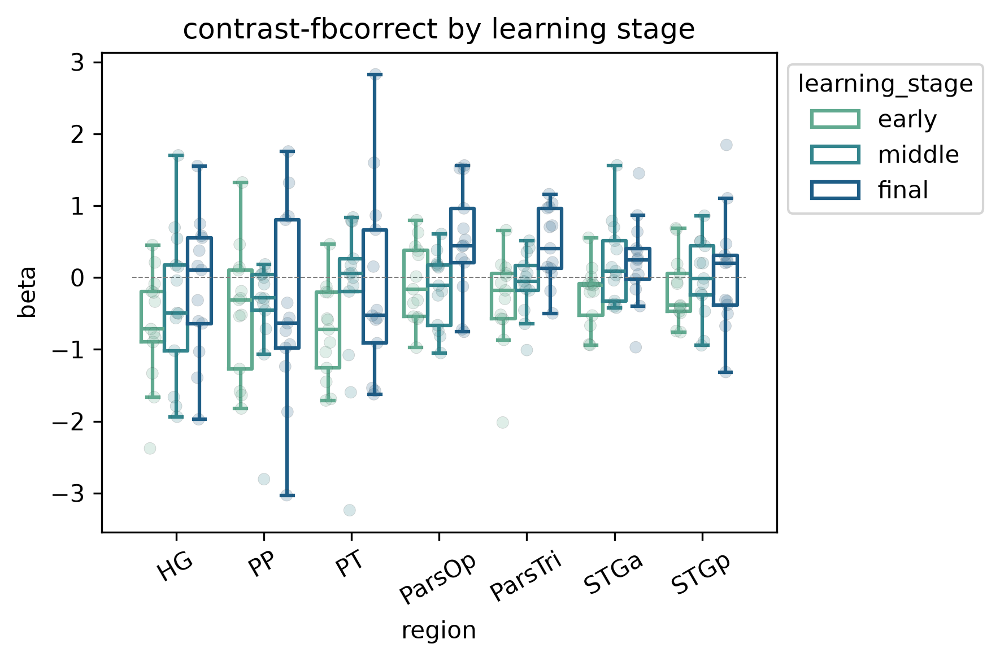

In [233]:
fig, ax = plt.subplots(1, 1, figsize=(6,4), dpi=300)

roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'learning_stage'], 
                                       as_index=False).agg({"beta": "mean"})

sns.boxplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='learning_stage', hue_order=['early', 'middle', 'final'],
              palette='crest',
              fliersize = 0,            
              linewidth=1.5,
              fill=False,
              #legend=None,
              ax=ax);
sns.stripplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='learning_stage', hue_order=['early', 'middle', 'final'],
              palette='crest',
              dodge=True,
              linewidth=0.2,
              alpha=.2,
              legend=None,
              ax=ax);


xmin, xmax = ax.get_xlim()
ax.hlines(y=0, xmin=xmin, xmax=xmax, color='0.5', linestyle='--', linewidth=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f'contrast-{contrast_label} by learning stage');
#ax.set_ylim([-5, 5])

fig.tight_layout()

fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-stage.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-stage.png'))

/scratch/slurm-12192413/ipykernel_2562235/508431189.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')


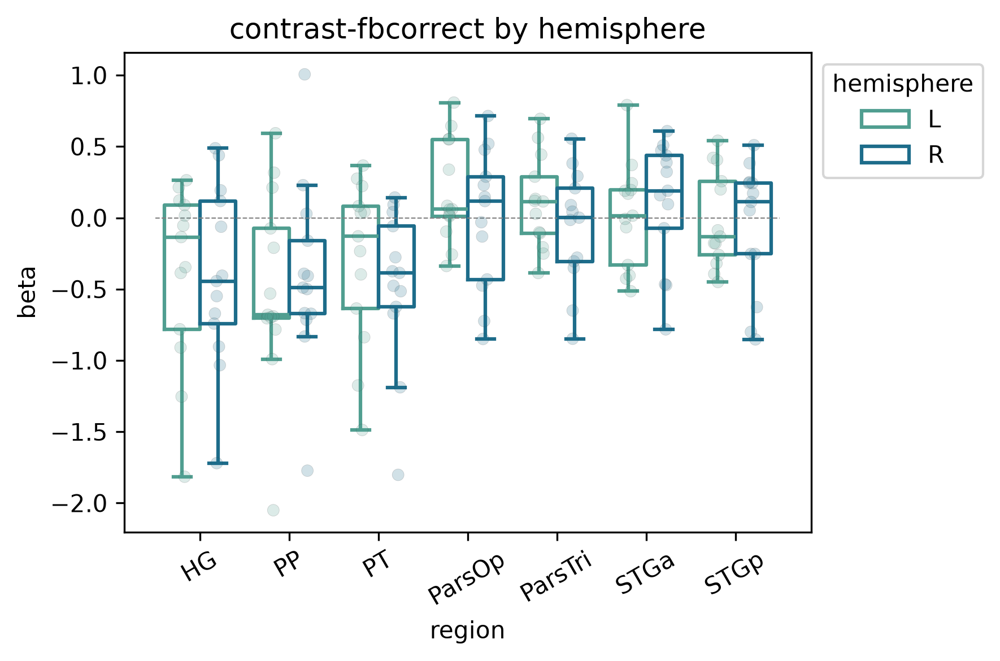

In [234]:
fig, ax = plt.subplots(1, 1, figsize=(6,4), dpi=300)

roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'hemisphere'], 
                                       as_index=False).agg({"beta": "mean"})

sns.boxplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='hemisphere', 
              palette='crest',
              fliersize = 0,            
              linewidth=1.5,
              fill=False,
              #legend=None,
              ax=ax);
sns.stripplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='hemisphere', 
              palette='crest',
              dodge=True,
              linewidth=0.2,
              alpha=.2,
              legend=None,
              ax=ax);


xmin, xmax = ax.get_xlim()
ax.hlines(y=0, xmin=xmin, xmax=xmax, color='0.5', linestyle='--', linewidth=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f'contrast-{contrast_label} by hemisphere');
#ax.set_ylim([-5, 5])

fig.tight_layout()

fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-hemisphere.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-hemisphere.png'))

### Brain-behavior correlations

In [235]:
# map runs to learning stages matching your thirds
stage_map = {'run-01': 'early', 'run-02': 'early',
             'run-03': 'middle', 'run-04': 'middle',
             'run-05': 'final', 'run-06': 'final'}

acc_df['learning_stage'] = acc_df['run'].map(stage_map)
acc_stage_df = acc_df.groupby(['participant_id', 'learning_stage'])['accuracy'].mean().reset_index()

In [236]:
# merge into roi_df_long — assumes participant_id and learning_stage columns exist in both
roi_df_bilateral = (roi_df_long.groupby(['participant_id', 'region', 'learning_stage'], as_index=False)['beta'].mean())
roi_behav_df = roi_df_bilateral.merge(acc_stage_df, on=['participant_id', 'learning_stage'])

# verify
roi_behav_df.groupby(['region', 'learning_stage']).size().unique()  # should be one row per participant


array([13])

In [237]:
results = []
for stage in ['early', 'middle', 'final']:
    stage_df = roi_behav_df[roi_behav_df['learning_stage'] == stage]
    for roi in plot_order: # stage_df['region'].unique():
        sub_df = stage_df[stage_df['region'] == roi]
        r = pg.corr(sub_df['accuracy'], sub_df['beta'], method='pearson')
        results.append({
            'roi': roi,
            'learning_stage': stage,
            'r': r['r'].values[0],
            'p': r['p_val'].values[0],
            'n': r['n'].values[0],
            'stat_str': stat_str('r', r['r'].values[0], r['p_val'].values[0])
        })

behav_corr_df = pd.DataFrame(results)

In [238]:
behav_corr_df

,roi,learning_stage,r,p,n,stat_str
0,HG,early,-0.3872,0.1912,13,"r = -.39, p = .191"
1,PT,early,-0.0558,0.8564,13,"r = -.06, p = .856"
2,PP,early,-0.2345,0.4406,13,"r = -.23, p = .441"
3,STGp,early,-0.0038,0.9901,13,"r = -.00, p = .990"
4,STGa,early,0.1722,0.5738,13,"r = .17, p = .574"
5,ParsOp,early,-0.0698,0.8208,13,"r = -.07, p = .821"
6,ParsTri,early,0.1858,0.5434,13,"r = .19, p = .543"
7,HG,middle,0.2434,0.4230,13,"r = .24, p = .423"
8,PT,middle,0.4027,0.1725,13,"r = .40, p = .173"
9,PP,middle,0.4205,0.1525,13,"r = .42, p = .153"


In [239]:
multipletests(behav_corr_df["p"], method="fdr_bh")

(array([False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False]),
 array([0.44603197, 0.89925773, 0.66084232, 0.9901005 , 0.70881957,
        0.89925773, 0.70881957, 0.66084232, 0.44603197, 0.44603197,
        0.44603197, 0.78168159, 0.44603197, 0.44603197, 0.44603197,
        0.70881957, 0.56295355, 0.44603197, 0.44603197, 0.51480357,
        0.56295355]),
 np.float64(0.002439557259668823),
 0.002380952380952381)

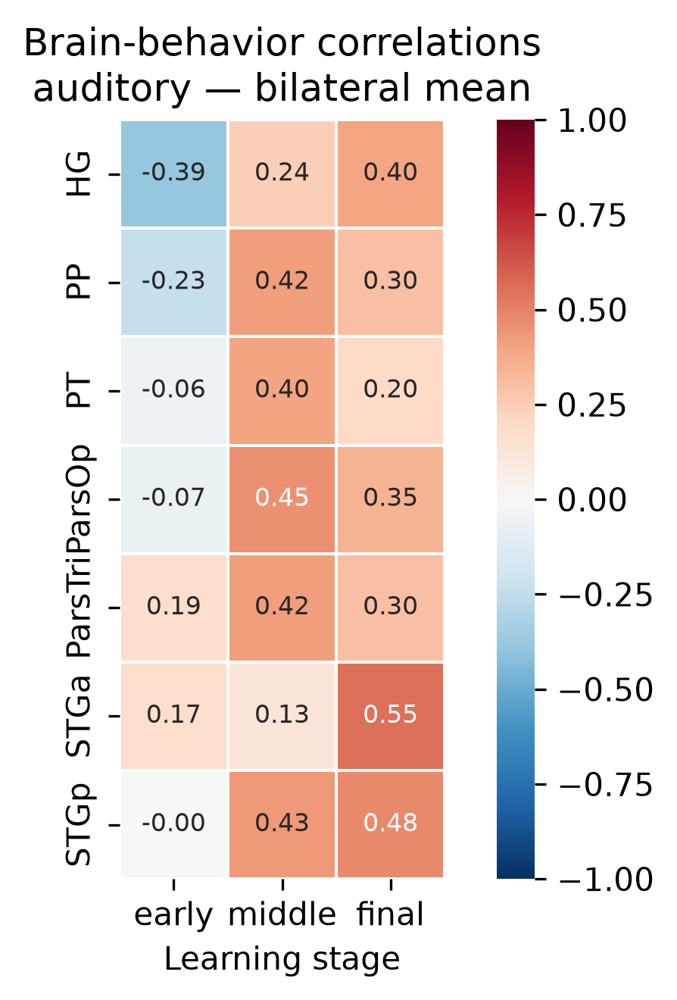

In [240]:
# pivot to ROI × stage matrix
r_matrix = behav_corr_df.pivot(index='roi', columns='learning_stage', values='r')[['early', 'middle', 'final']]
p_matrix = behav_corr_df.pivot(index='roi', columns='learning_stage', values='p')[['early', 'middle', 'final']]

fig, ax = plt.subplots(figsize=(5, len(r_matrix) * 0.5 + 1), dpi=300)
sns.heatmap(r_matrix, ax=ax, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot=True, fmt='.2f', annot_kws={'size': 8},
            square=True)

# mark significant cells with an asterisk
for i, roi in enumerate(r_matrix.index):
    for j, stage in enumerate(['early', 'middle', 'final']):
        p = p_matrix.loc[roi, stage]
        if p < 0.05:
            ax.text(j + 0.5, i + 0.85, '*', ha='center', va='center',
                    fontsize=12, color='black')

ax.set_title(f'Brain-behavior correlations\n{network_name} — bilateral mean')
ax.set_ylabel('')
ax.set_xlabel('Learning stage')
plt.tight_layout()
plt.savefig(os.path.join(fig_out_dir, f'brain-behav-corr_contrast-{contrast_label}_network-{network_name}_heatmap.svg'))

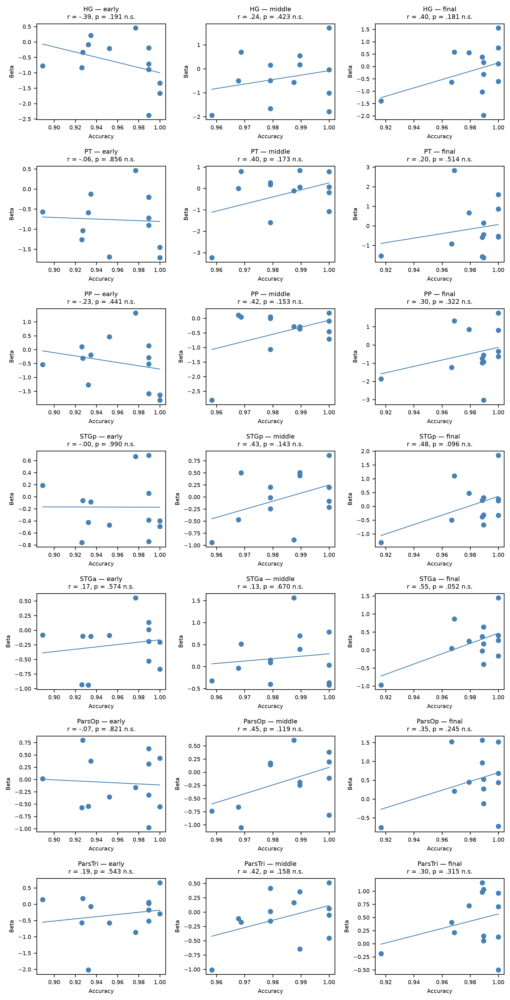

In [241]:
rois = behav_corr_df['roi'].unique()
stages = ['early', 'middle', 'final']

fig, axes = plt.subplots(len(rois), 3, figsize=(9, len(rois) * 2.5), dpi=300, sharex=False, sharey=False)

for ri, roi in enumerate(plot_order): # rois):
    for si, stage in enumerate(stages):
        ax = axes[ri, si]
        sub_df = roi_behav_df[(roi_behav_df['region'] == roi) & 
                              (roi_behav_df['learning_stage'] == stage)]
        
        ax.scatter(sub_df['accuracy'], sub_df['beta'], s=30, color='steelblue', zorder=3)
        
        # regression line
        m, b = np.polyfit(sub_df['accuracy'], sub_df['beta'], 1)
        x_range = np.linspace(sub_df['accuracy'].min(), sub_df['accuracy'].max(), 100)
        ax.plot(x_range, m * x_range + b, color='steelblue', linewidth=1)
        
        # stat annotation
        row = behav_corr_df[(behav_corr_df['roi'] == roi) & 
                            (behav_corr_df['learning_stage'] == stage)].iloc[0]
        p_str = '*' if row['p'] < 0.05 else 'n.s.'
        ax.set_title(f"{roi} — {stage}\n{row['stat_str']} {p_str}", fontsize=8)
        ax.set_xlabel('Accuracy', fontsize=7)
        ax.set_ylabel('Beta', fontsize=7)
        ax.tick_params(labelsize=7)

plt.tight_layout()
plt.savefig(os.path.join(fig_out_dir, f'brain-behav-corr_contrast-{contrast_label}_network-{network_name}_corr-plots.svg'))

HG early: r = -.39, p = .191 n.s.
HG middle: r = .24, p = .423 n.s.
HG final: r = .40, p = .181 n.s.
PT early: r = -.06, p = .856 n.s.
PT middle: r = .40, p = .173 n.s.
PT final: r = .20, p = .514 n.s.
PP early: r = -.23, p = .441 n.s.
PP middle: r = .42, p = .153 n.s.
PP final: r = .30, p = .322 n.s.
STGp early: r = -.00, p = .990 n.s.
STGp middle: r = .43, p = .143 n.s.
STGp final: r = .48, p = .096 n.s.
STGa early: r = .17, p = .574 n.s.
STGa middle: r = .13, p = .670 n.s.
STGa final: r = .55, p = .052 n.s.
ParsOp early: r = -.07, p = .821 n.s.
ParsOp middle: r = .45, p = .119 n.s.
ParsOp final: r = .35, p = .245 n.s.
ParsTri early: r = .19, p = .543 n.s.
ParsTri middle: r = .42, p = .158 n.s.
ParsTri final: r = .30, p = .315 n.s.


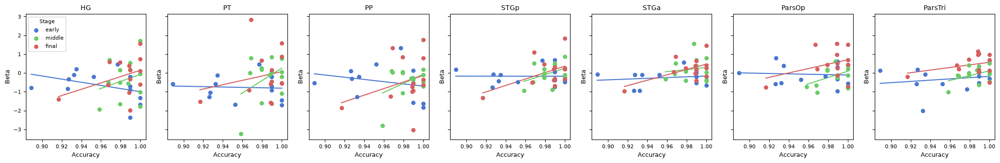

In [242]:
stage_colors = {'early': '#4878CF', 'middle': '#6ACC65', 'final': '#D65F5F'}
stages = ['early', 'middle', 'final']
rois = plot_order # behav_corr_df['roi'].unique()

fig, axes = plt.subplots(1, len(rois), figsize=(3 * len(rois), 3.5), dpi=100, sharey=True)
if len(rois) == 1:
    axes = [axes]

for ri, roi in enumerate(rois):
    ax = axes[ri]
    for stage in stages:
        color = stage_colors[stage]
        sub_df = roi_behav_df[(roi_behav_df['region'] == roi) &
                              (roi_behav_df['learning_stage'] == stage)]

        ax.scatter(sub_df['accuracy'], sub_df['beta'], s=30,
                   color=color, label=stage, zorder=3)

        m, b = np.polyfit(sub_df['accuracy'], sub_df['beta'], 1)
        x_range = np.linspace(sub_df['accuracy'].min(), sub_df['accuracy'].max(), 100)
        ax.plot(x_range, m * x_range + b, color=color, linewidth=1.5)

        # stat annotation per stage
        row = behav_corr_df[(behav_corr_df['roi'] == roi) &
                            (behav_corr_df['learning_stage'] == stage)].iloc[0]
        p_str = '*' if row['p'] < 0.05 else 'n.s.'
        print(f"{roi} {stage}: {row['stat_str']} {p_str}")

    ax.set_title(roi, fontsize=10)
    ax.set_xlabel('Accuracy', fontsize=9)
    ax.set_ylabel('Beta', fontsize=9)
    ax.tick_params(labelsize=8)

axes[0].legend(title='Stage', fontsize=8, title_fontsize=8)
plt.tight_layout()


### omnibus ANOVA stats

In [243]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import AnovaRM

# Mixed-Effects ANOVA with Hemisphere, Region, and Interaction
aov = AnovaRM(group_df, 
              aggregate_func='mean',
              depvar='beta', 
              subject='participant_id', 
              within=['hemisphere', 'learning_stage','region', ]).fit()

# Display results
print('network:', network_name)
print('contrast:', contrast_label)
print(aov)


network: auditory
contrast: fbcorrect
                             Anova
                                 F Value  Num DF  Den DF  Pr > F
----------------------------------------------------------------
hemisphere                        0.8517  1.0000  12.0000 0.3743
learning_stage                    2.2467  2.0000  24.0000 0.1275
region                            7.2823  6.0000  72.0000 0.0000
hemisphere:learning_stage         1.7842  2.0000  24.0000 0.1895
hemisphere:region                 1.2394  6.0000  72.0000 0.2966
learning_stage:region             0.9789 12.0000 144.0000 0.4718
hemisphere:learning_stage:region  0.5438 12.0000 144.0000 0.8828



In [244]:
aov.summary().tables[0]

,F Value,Num DF,Den DF,Pr > F
hemisphere,0.8517,1.0000,12.0000,0.3743
learning_stage,2.2467,2.0000,24.0000,0.1275
region,7.2823,6.0000,72.0000,0.0000
hemisphere:learning_stage,1.7842,2.0000,24.0000,0.1895
hemisphere:region,1.2394,6.0000,72.0000,0.2966
learning_stage:region,0.9789,12.0000,144.0000,0.4718
hemisphere:learning_stage:region,0.5438,12.0000,144.0000,0.8828


In [245]:
# GG-corrected bilateral replication (learning_stage x region)
bilateral_df = (group_df
                .groupby(['participant_id', 'region', 'learning_stage'], as_index=False)['beta']
                .mean())
aov_pg = pg.rm_anova(data=bilateral_df, dv='beta',
                     within=['learning_stage', 'region'],
                     subject='participant_id',
                     detailed=True)
eta_col = 'np2' if 'np2' in aov_pg.columns else 'ng2'
print(aov_pg[['Source', 'F', 'ddof1', 'ddof2', 'p_unc', 'p_GG_corr', eta_col]])
export_pg_anova(aov_pg, f'{contrast_label}_{network_name}_learning-stage_region_bilateral', stats_out_dir)

                    Source      F  ddof1  ddof2  p_unc  p_GG_corr    ng2
0           learning_stage 2.2467      2     24 0.1275     0.1398 0.0573
1                   region 7.2823      6     72 0.0000     0.0012 0.0769
2  learning_stage * region 0.9789     12    144 0.4718     0.4000 0.0277


/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/pingouin/distribution.py:514: UserWarning: Epsilon values might be innaccurate in two-way repeated measures design where each  factor has more than 2 levels. Please  double-check your results.
  warnings.warn(


,source,df_num,df_den,F,p_unc,p_GG_corr,eta_p2,stat_str
0,learning_stage,2,24,2.25,p = .128,p = .140,0.06,"F(2, 24) = 2.25, p = .140"
1,region,6,72,7.28,p < .001,p = .001,0.08,"F(6, 72) = 7.28, p = .001"
2,learning_stage * region,12,144,0.98,p = .472,p = .400,0.03,"F(12, 144) = 0.98, p = .400"


In [246]:
# pairwise by region, no learning stage

# Pairwise comparisons for region with FDR correction
pairwise_by_region_only = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['learning_stage', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_region_only.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_region_only)
pairwise_by_region_only[['Contrast', 'Contrast', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns


Available columns: Index(['Contrast', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof', 'alternative',
       'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,Contrast,A,B,T,dof,p_unc,p_corr,BF10
0,learning_stage,learning_stage,early,final,-2.5304,12.0000,0.0264,0.0792,2.655
1,learning_stage,learning_stage,early,middle,-1.1545,12.0000,0.2708,0.3941,0.485
2,learning_stage,learning_stage,final,middle,0.8839,12.0000,0.3941,0.3941,0.388


In [247]:
export_posthoc(pairwise_by_region_only, f'{contrast_label}_{network_name}_learning-stage', stats_out_dir)

,Contrast,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,learning_stage,early,final,-2.53,12.0000,p = .026,p = .079,"t(12) = -2.53, p = .026","t(12) = -2.53, q = .079"
1,learning_stage,early,middle,-1.15,12.0000,p = .271,p = .394,"t(12) = -1.15, p = .271","t(12) = -1.15, q = .394"
2,learning_stage,final,middle,0.88,12.0000,p = .394,p = .394,"t(12) = 0.88, p = .394","t(12) = 0.88, q = .394"


### Collapse (average) over non-significant factors

In [248]:
roi_df_collapsed = roi_df_long.groupby(["participant_id", "region", 'learning_stage'], 
                                       as_index=False).agg({"beta": "mean"})


In [249]:
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_1samp


# Collect p-values
p_values = []
t_stats = []
comparisons = []

for region_stage, data in roi_df_collapsed.groupby(["region",'learning_stage']):
    #print(region_stage)
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    p_values.append(p_val)
    comparisons.append((region_stage[0], region_stage[1], t_stat))
    t_stats.append(t_stat)

# Apply FDR correction
_, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Print corrected results
for (region, stage, t_stat), p_val_corr in zip(comparisons, p_corrected):
    print(f"Region: {region}, stage: {stage}, t = {t_stat:.2f}; corrected p = {p_val_corr:.4f}")


Region: HG, stage: early, t = -3.10; corrected p = 0.0639
Region: HG, stage: final, t = -0.54; corrected p = 0.7396
Region: HG, stage: middle, t = -1.24; corrected p = 0.3967
Region: PP, stage: early, t = -1.87; corrected p = 0.2603
Region: PP, stage: final, t = -1.17; corrected p = 0.3967
Region: PP, stage: middle, t = -1.99; corrected p = 0.2448
Region: PT, stage: early, t = -4.23; corrected p = 0.0246
Region: PT, stage: final, t = -0.35; corrected p = 0.8047
Region: PT, stage: middle, t = -0.80; corrected p = 0.6160
Region: ParsOp, stage: early, t = -0.47; corrected p = 0.7538
Region: ParsOp, stage: final, t = 2.36; corrected p = 0.1898
Region: ParsOp, stage: middle, t = -1.18; corrected p = 0.3967
Region: ParsTri, stage: early, t = -1.72; corrected p = 0.2905
Region: ParsTri, stage: final, t = 3.10; corrected p = 0.0639
Region: ParsTri, stage: middle, t = -0.71; corrected p = 0.6454
Region: STGa, stage: early, t = -2.07; corrected p = 0.2448
Region: STGa, stage: final, t = 1.36; co

In [250]:
# Collect p-values
p_values = []
t_stats = []
comparisons = []

# average within participant first: one value per participant, so n (and df) = number of participants
for region, data in (roi_df_collapsed.groupby(["participant_id", "region"], as_index=False)["beta"].mean()
                     .groupby(["region"])):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    p_values.append(p_val)
    comparisons.append((region[0], t_stat))
    t_stats.append(t_stat)

# Apply FDR correction
_, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Print corrected results
for (region, t_stat), p_val_corr in zip(comparisons, p_corrected):
    print(f"Region: {region}, t = {t_stat:.2f}; corrected p = {p_val_corr:.4f}")


Region: HG, t = -2.30; corrected p = 0.0941
Region: PP, t = -2.56; corrected p = 0.0875
Region: PT, t = -2.82; corrected p = 0.0875
Region: ParsOp, t = 0.88; corrected p = 0.6951
Region: ParsTri, t = 0.23; corrected p = 0.8199
Region: STGa, t = 0.63; corrected p = 0.7556
Region: STGp, t = -0.42; corrected p = 0.7995


In [251]:
_records = [{'region': c[0], 't': c[1], 'df': len(sub_list) - 1, 'p': p}
            for c, p in zip(comparisons, p_values)]
export_ttests(_records, f'{contrast_label}_{network_name}_baseline_by_region', stats_out_dir)

,region,t,df,p,p_fdr,stat_str,stat_str_fdr
0,HG,-2.30,12,p = .040,p = .094,"t(12) = -2.30, p = .040","t(12) = -2.30, q = .094"
1,PP,-2.56,12,p = .025,p = .087,"t(12) = -2.56, p = .025","t(12) = -2.56, q = .087"
2,PT,-2.82,12,p = .015,p = .087,"t(12) = -2.82, p = .015","t(12) = -2.82, q = .087"
3,ParsOp,0.88,12,p = .397,p = .695,"t(12) = 0.88, p = .397","t(12) = 0.88, q = .695"
4,ParsTri,0.23,12,p = .820,p = .820,"t(12) = 0.23, p = .820","t(12) = 0.23, q = .820"
5,STGa,0.63,12,p = .540,p = .756,"t(12) = 0.63, p = .540","t(12) = 0.63, q = .756"
6,STGp,-0.42,12,p = .685,p = .800,"t(12) = -0.42, p = .685","t(12) = -0.42, q = .800"


### Cortical surface plot (t-statistic, by hemisphere)

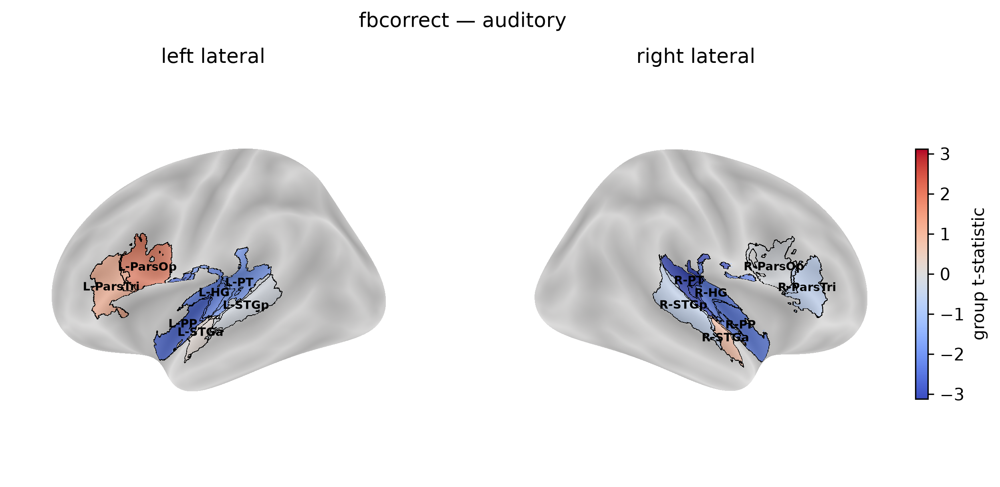

In [252]:
roi_df_collapsed_hemi = group_df.groupby(["participant_id", "region", "hemisphere"],
                                                 as_index=False).agg({"beta": "mean"})

p_values = []
t_stats = []
comparisons = []
for (region, hemi), data in roi_df_collapsed_hemi.groupby(["region", "hemisphere"]):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    p_values.append(p_val)
    comparisons.append((region, hemi, t_stat))
    t_stats.append(t_stat)

stat_dict = {f"{hemi}-{region}": t for (region, hemi, t) in comparisons}
mask_path_dict = build_mask_path_dict(list(stat_dict.keys()), masks_dir, network_name, surf_space_label)

surface_views = ('lateral',) if network_name == 'auditory' else ('lateral', 'medial')
fig = plot_roi_surface_stat(stat_dict, mask_path_dict, title=f'{contrast_label} — {network_name}', views=surface_views, fsaverage=fsaverage)
#fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat.png'))


### Cortical surface plot (t-statistic, final vs. early)

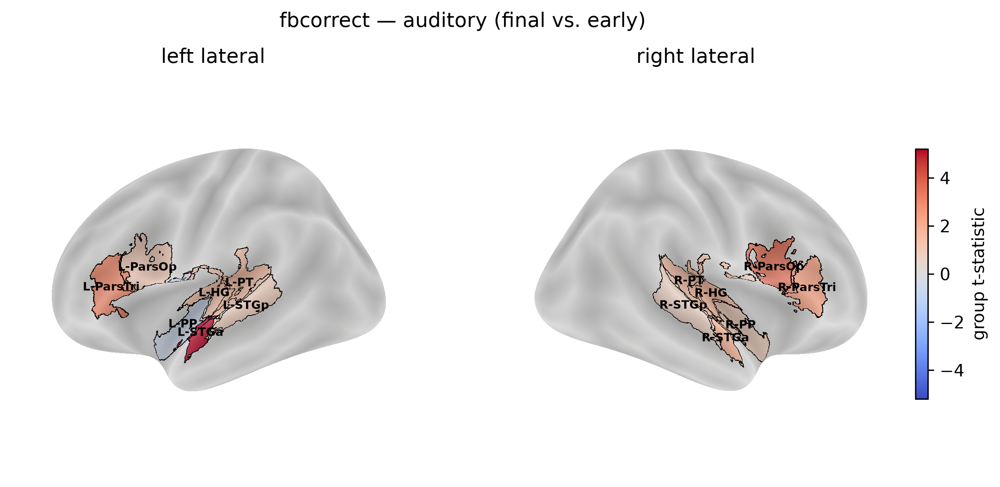

In [253]:
# Learning-stage difference (final vs. early)
_diff_df = (group_df[group_df['learning_stage'].isin(['early', 'final'])]
            .groupby(['participant_id', 'region_hemi', 'learning_stage'], as_index=False)['beta'].mean()
            .pivot(index=['participant_id', 'region_hemi'], columns='learning_stage', values='beta')
            .dropna()
            .reset_index())

diff_stat_dict = {}
for region_hemi, data in _diff_df.groupby('region_hemi'):
    t_stat, _ = ttest_rel(data['final'], data['early'])
    diff_stat_dict[region_hemi] = t_stat

mask_path_dict_diff = build_mask_path_dict(list(diff_stat_dict.keys()), masks_dir, network_name, surf_space_label)
surface_views_diff = ('lateral',) if network_name == 'auditory' else ('lateral', 'medial')
fig_diff = plot_roi_surface_stat(diff_stat_dict, mask_path_dict_diff,
                                  title=f'{contrast_label} — {network_name} (final vs. early)',
                                  views=surface_views_diff, fsaverage=fsaverage)
#fig_diff.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat_diff-final-early.svg'))
fig_diff.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat_diff-final-early.png'))


In [254]:
# Collect results
results = []

# average within participant first: one value per participant, so n (and df) = number of participants
for region, data in (roi_df_collapsed.groupby(["participant_id", "region"], as_index=False)["beta"].mean()
                     .groupby("region")):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    results.append({
        "region": region,
        "t_stat": t_stat,
        "p_val": p_val
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Apply FDR correction
results_df["p_val_fdr"] = multipletests(results_df["p_val"], method="fdr_bh")[1]

# Print or export the table
results_df

# Optional: export
# results_df.to_csv("roi_stats.csv", index=False)
# results_df.to_excel("roi_stats.xlsx", index=False)


,region,t_stat,p_val,p_val_fdr
0,HG,-2.2982,0.0403,0.0941
1,PP,-2.5601,0.0250,0.0875
2,PT,-2.8203,0.0155,0.0875
3,ParsOp,0.8780,0.3972,0.6951
4,ParsTri,0.2327,0.8199,0.8199
5,STGa,0.6312,0.5397,0.7556
6,STGp,-0.4152,0.6853,0.7995


In [255]:
_export = results_df.rename(columns={'t_stat': 't', 'p_val': 'p'}).copy()
_export['df'] = len(sub_list) - 1
export_ttests(_export.to_dict('records'), f'{contrast_label}_{network_name}_baseline_by_region', stats_out_dir)

,region,t,p,p_val_fdr,df,p_fdr,stat_str,stat_str_fdr
0,HG,-2.30,p = .040,0.0941,12,p = .094,"t(12) = -2.30, p = .040","t(12) = -2.30, q = .094"
1,PP,-2.56,p = .025,0.0875,12,p = .087,"t(12) = -2.56, p = .025","t(12) = -2.56, q = .087"
2,PT,-2.82,p = .015,0.0875,12,p = .087,"t(12) = -2.82, p = .015","t(12) = -2.82, q = .087"
3,ParsOp,0.88,p = .397,0.6951,12,p = .695,"t(12) = 0.88, p = .397","t(12) = 0.88, q = .695"
4,ParsTri,0.23,p = .820,0.8199,12,p = .820,"t(12) = 0.23, p = .820","t(12) = 0.23, q = .820"
5,STGa,0.63,p = .540,0.7556,12,p = .756,"t(12) = 0.63, p = .540","t(12) = 0.63, q = .756"
6,STGp,-0.42,p = .685,0.7995,12,p = .800,"t(12) = -0.42, p = .685","t(12) = -0.42, q = .800"


In [256]:
# Collect results
results = []

for (region, stage), data in roi_df_collapsed.groupby(["region", "learning_stage"]):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    results.append({
        "region": region,
        "learning_stage": stage,
        "t_stat": t_stat,
        "p_val": p_val
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Apply FDR correction
results_df["p_val_fdr"] = multipletests(results_df["p_val"], method="fdr_bh")[1]

stage_order = ["early", "middle", "final"]

results_df["learning_stage"] = pd.Categorical(
    results_df["learning_stage"],
    categories=stage_order,
    ordered=True
)

# Now sort
results_df = results_df.sort_values(["learning_stage", "region"])


# Print or export the table
results_df

# Optional: export
# results_df.to_csv("roi_stats.csv", index=False)
# results_df.to_excel("roi_stats.xlsx", index=False)


,region,learning_stage,t_stat,p_val,p_val_fdr
0,HG,early,-3.1037,0.0091,0.0639
3,PP,early,-1.8652,0.0868,0.2603
6,PT,early,-4.2289,0.0012,0.0246
9,ParsOp,early,-0.4709,0.6461,0.7538
12,ParsTri,early,-1.7223,0.1107,0.2905
15,STGa,early,-2.0674,0.0610,0.2448
18,STGp,early,-1.3147,0.2132,0.3967
2,HG,middle,-1.2386,0.2392,0.3967
5,PP,middle,-1.9893,0.0700,0.2448
8,PT,middle,-0.7987,0.4400,0.6160


In [257]:
_export = results_df.rename(columns={'t_stat': 't', 'p_val': 'p'}).copy()
_export['df'] = len(sub_list) - 1
export_ttests(_export.to_dict('records'), f'{contrast_label}_{network_name}_baseline_by_region_stage', stats_out_dir)

,region,learning_stage,t,p,p_val_fdr,df,p_fdr,stat_str,stat_str_fdr
0,HG,early,-3.10,p = .009,0.0639,12,p = .064,"t(12) = -3.10, p = .009","t(12) = -3.10, q = .064"
1,PP,early,-1.87,p = .087,0.2603,12,p = .260,"t(12) = -1.87, p = .087","t(12) = -1.87, q = .260"
2,PT,early,-4.23,p = .001,0.0246,12,p = .025,"t(12) = -4.23, p = .001","t(12) = -4.23, q = .025"
3,ParsOp,early,-0.47,p = .646,0.7538,12,p = .754,"t(12) = -0.47, p = .646","t(12) = -0.47, q = .754"
4,ParsTri,early,-1.72,p = .111,0.2905,12,p = .290,"t(12) = -1.72, p = .111","t(12) = -1.72, q = .290"
5,STGa,early,-2.07,p = .061,0.2448,12,p = .245,"t(12) = -2.07, p = .061","t(12) = -2.07, q = .245"
6,STGp,early,-1.31,p = .213,0.3967,12,p = .397,"t(12) = -1.31, p = .213","t(12) = -1.31, q = .397"
7,HG,middle,-1.24,p = .239,0.3967,12,p = .397,"t(12) = -1.24, p = .239","t(12) = -1.24, q = .397"
8,PP,middle,-1.99,p = .070,0.2448,12,p = .245,"t(12) = -1.99, p = .070","t(12) = -1.99, q = .245"
9,PT,middle,-0.80,p = .440,0.6160,12,p = .616,"t(12) = -0.80, p = .440","t(12) = -0.80, q = .616"


## `contrast-feedback` for prefrontal cortical network

In [258]:
# get the beta map for the contrast of interest for each subject
network_name = network_list[3]
contrast_label = contrast_list[2]
event_type = contrast_event_type[contrast_label]
print('network_name:', network_name)
print('contrast_label:', contrast_label)

network_name: pfc
contrast_label: fbcorrect


In [259]:
# per-group copy of the ROI table that the cells below (and robustness_checks.py) read
out_fname = f'univariate-results_network-{network_name}_contrast-{contrast_label}{group_suffix}.tsv'
combined_roi_df_fpath = os.path.join(group_out_dir, out_fname)

In [260]:
# this group's per-ROI values (from extract_roi_values.py), saved under the
# name the cells below and robustness_checks.py read
roi_df_long = load_roi_values(network_name, contrast_label)
roi_df_long.to_csv(combined_roi_df_fpath, sep='\t', index=False)
roi_df_long.groupby('learning_stage').participant_id.nunique()

learning_stage
early     13
final     13
middle    13
Name: participant_id, dtype: int64

In [261]:
# load the DataFrame if already exists
roi_df_long = pd.read_csv(combined_roi_df_fpath, sep='\t')

# create a bilateral-averaged dataframe (for across-contrast analysis)
feedback_pfc_df = bilateral_mean(roi_df_long)


In [262]:
roi_df_long.columns

Index(['participant_id', 'participant_group', 'region', 'beta', 'region_hemi',
       'hemisphere', 'learning_stage'],
      dtype='str')

In [263]:
roi_df_long.participant_id.unique()

<StringArray>
['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17',
 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24',
 'sub-FLT26']
Length: 13, dtype: str

In [264]:
roi_df_long.region.unique()

<StringArray>
['FP', 'SFG', 'MFG', 'IFGt', 'IFGo', 'PreCG', 'FMC', 'PCG', 'ACC', 'OFC',
 'FO']
Length: 11, dtype: str

In [265]:
roi_df_long.region_hemi.unique()

<StringArray>
[   'L-FP',    'R-FP',   'L-SFG',   'R-SFG',   'L-MFG',   'R-MFG',  'L-IFGt',
  'R-IFGt',  'L-IFGo',  'R-IFGo', 'L-PreCG', 'R-PreCG',   'L-FMC',   'R-FMC',
   'L-PCG',   'R-PCG',   'L-ACC',   'R-ACC',   'L-OFC',   'R-OFC',    'L-FO',
    'R-FO']
Length: 22, dtype: str

In [266]:
PREFRONTAL_ROIS = ['PCG', 'ACC', 'OFC', 'FMC', 'IFGt', 'IFGo']
mask = roi_df_long['region'].isin(PREFRONTAL_ROIS)
group_df = roi_df_long[mask]

In [267]:
plot_order = PREFRONTAL_ROIS
             #['ACC', 'PCG', 'OFC', 'FP', 'FO', 'FMC', 
             # 'SFG', 'MFG', 'IFGt', 'IFGo', 'PreCG']

/scratch/slurm-12192413/ipykernel_2562235/2389160805.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')


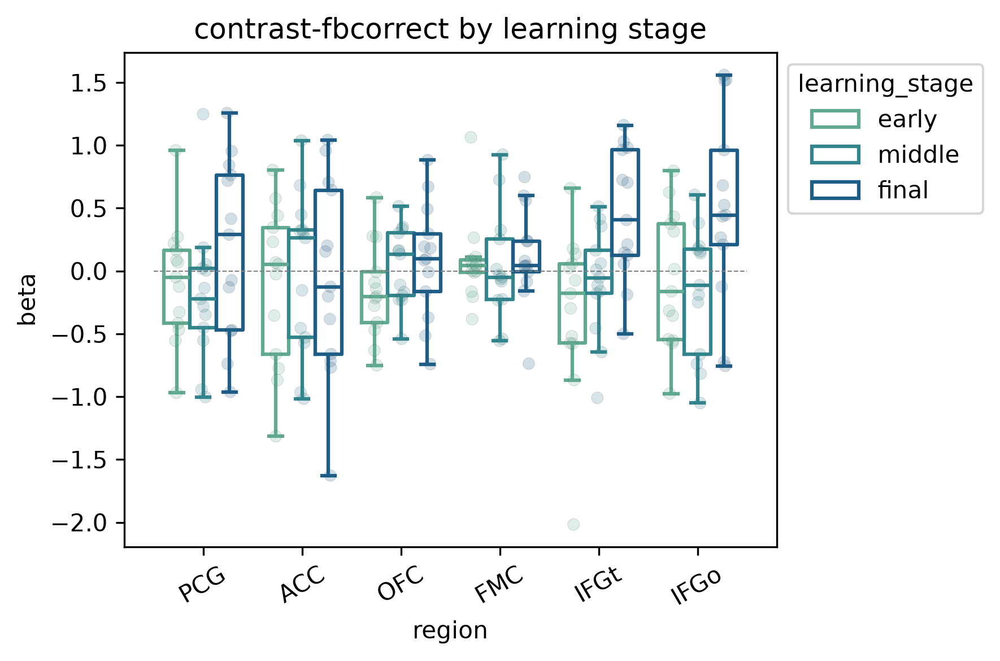

In [268]:
fig, ax = plt.subplots(1, 1, figsize=(6,4), dpi=300)

roi_df_collapsed = group_df.groupby(["participant_id", "region", 'learning_stage'], 
                                       as_index=False).agg({"beta": "mean"})

sns.boxplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='learning_stage', hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              fliersize = 0,            
              linewidth=1.5,
              fill=False,
              #legend=None,
              ax=ax);
sns.stripplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='learning_stage', hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              dodge=True,
              linewidth=0.2,
              alpha=.2,
              legend=None,
              ax=ax);


xmin, xmax = ax.get_xlim()
ax.hlines(y=0, xmin=xmin, xmax=xmax, color='0.5', linestyle='--', linewidth=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f'contrast-{contrast_label} by learning stage');
#ax.set_ylim([-5, 5])

fig.tight_layout()

fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-stage.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-stage.png'))

/scratch/slurm-12192413/ipykernel_2562235/4197762766.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')


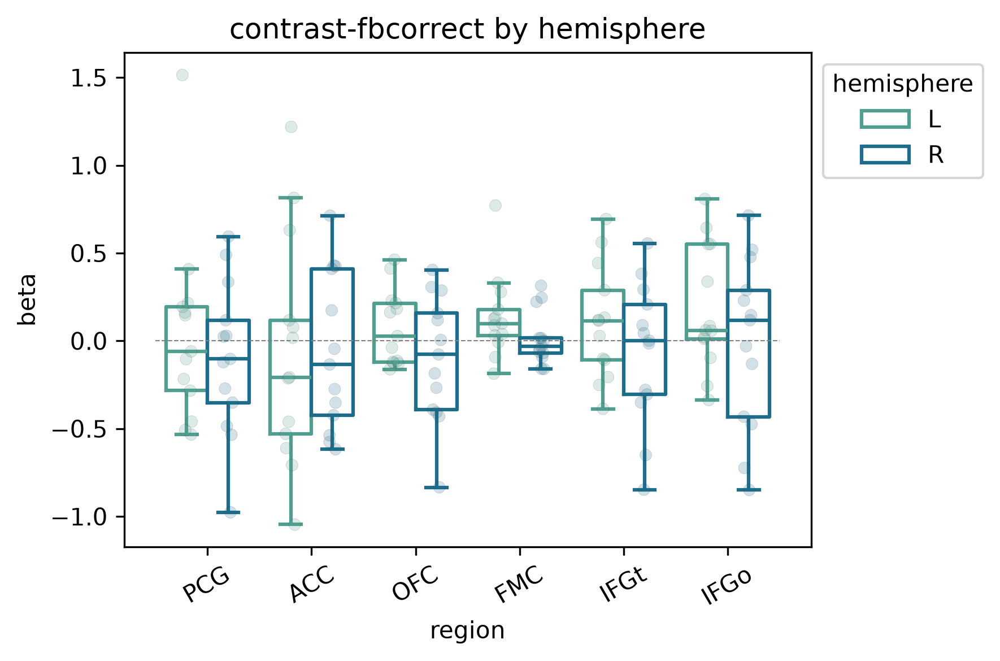

In [269]:
fig, ax = plt.subplots(1, 1, figsize=(6,4), dpi=300)

roi_df_collapsed = group_df.groupby(["participant_id", "region", 'hemisphere'], 
                                       as_index=False).agg({"beta": "mean"})

sns.boxplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='hemisphere', #hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              fliersize = 0,            
              linewidth=1.5,
              fill=False,
              #legend=None,
              ax=ax);
sns.stripplot(data=roi_df_collapsed, 
              x='region', y='beta', 
              hue='hemisphere', #hue_order=['early', 'middle', 'final'],
              order=plot_order,
              palette='crest',
              dodge=True,
              linewidth=0.2,
              alpha=.2,
              legend=None,
              ax=ax);


xmin, xmax = ax.get_xlim()
ax.hlines(y=0, xmin=xmin, xmax=xmax, color='0.5', linestyle='--', linewidth=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f'contrast-{contrast_label} by hemisphere');
#ax.set_ylim([-5, 5])

fig.tight_layout()

fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-hemisphere.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_boxplot-hemisphere.png'))

### Brain-behavior correlations

In [270]:
# map runs to learning stages matching your thirds
stage_map = {'run-01': 'early', 'run-02': 'early',
             'run-03': 'middle', 'run-04': 'middle',
             'run-05': 'final', 'run-06': 'final'}

acc_df['learning_stage'] = acc_df['run'].map(stage_map)
acc_stage_df = acc_df.groupby(['participant_id', 'learning_stage'])['accuracy'].mean().reset_index()

In [271]:
# merge into roi_df_long — assumes participant_id and learning_stage columns exist in both
roi_df_bilateral = (roi_df_long.groupby(['participant_id', 'region', 'learning_stage'], as_index=False)['beta'].mean())
roi_behav_df = roi_df_bilateral.merge(acc_stage_df, on=['participant_id', 'learning_stage'])

# verify
roi_behav_df.groupby(['region', 'learning_stage']).size().unique()  # should be one row per participant


array([13])

In [272]:
roi_behav_df.columns

Index(['participant_id', 'region', 'learning_stage', 'beta', 'accuracy'], dtype='str')

In [273]:
roi_behav_df.participant_id.unique()

<StringArray>
['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17',
 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24',
 'sub-FLT26']
Length: 13, dtype: str

In [274]:
results = []
for stage in ['early', 'middle', 'final']:
    stage_df = roi_behav_df[roi_behav_df['learning_stage'] == stage]
    for roi in plot_order: # stage_df['region'].unique():
        sub_df = stage_df[stage_df['region'] == roi]
        r = pg.corr(sub_df['accuracy'], sub_df['beta'], method='pearson')
        results.append({
            'roi': roi,
            'learning_stage': stage,
            'r': r['r'].values[0],
            'p': r['p_val'].values[0],
            'n': r['n'].values[0],
            'stat_str': stat_str('r', r['r'].values[0], r['p_val'].values[0])
        })

behav_corr_df = pd.DataFrame(results)

In [275]:
behav_corr_df

,roi,learning_stage,r,p,n,stat_str
0,PCG,early,0.3748,0.2070,13,"r = .37, p = .207"
1,ACC,early,0.1753,0.5667,13,"r = .18, p = .567"
2,OFC,early,0.3028,0.3146,13,"r = .30, p = .315"
3,FMC,early,0.4471,0.1256,13,"r = .45, p = .126"
4,IFGt,early,0.1858,0.5434,13,"r = .19, p = .543"
5,IFGo,early,-0.0698,0.8208,13,"r = -.07, p = .821"
6,PCG,middle,0.2486,0.4128,13,"r = .25, p = .413"
7,ACC,middle,-0.0408,0.8947,13,"r = -.04, p = .895"
8,OFC,middle,0.2239,0.4621,13,"r = .22, p = .462"
9,FMC,middle,-0.3952,0.1814,13,"r = -.40, p = .181"


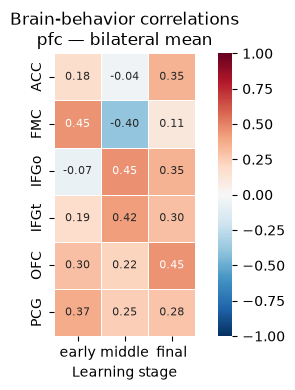

In [276]:
# pivot to ROI × stage matrix
r_matrix = behav_corr_df.pivot(index='roi', columns='learning_stage', values='r')[['early', 'middle', 'final']]
p_matrix = behav_corr_df.pivot(index='roi', columns='learning_stage', values='p')[['early', 'middle', 'final']]

fig, ax = plt.subplots(figsize=(5, len(r_matrix) * 0.5 + 1), dpi=100)
sns.heatmap(r_matrix, ax=ax, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot=True, fmt='.2f', annot_kws={'size': 8},
            square=True)

# mark significant cells with an asterisk
for i, roi in enumerate(r_matrix.index):
    for j, stage in enumerate(['early', 'middle', 'final']):
        p = p_matrix.loc[roi, stage]
        if p < 0.05:
            ax.text(j + 0.5, i + 0.85, '*', ha='center', va='center',
                    fontsize=12, color='black')

ax.set_title(f'Brain-behavior correlations\n{network_name} — bilateral mean')
ax.set_ylabel('')
ax.set_xlabel('Learning stage')
plt.tight_layout()
plt.savefig(os.path.join(fig_out_dir, f'brain-behav-corr_contrast-{contrast_label}_network-{network_name}_heatmap.svg'))

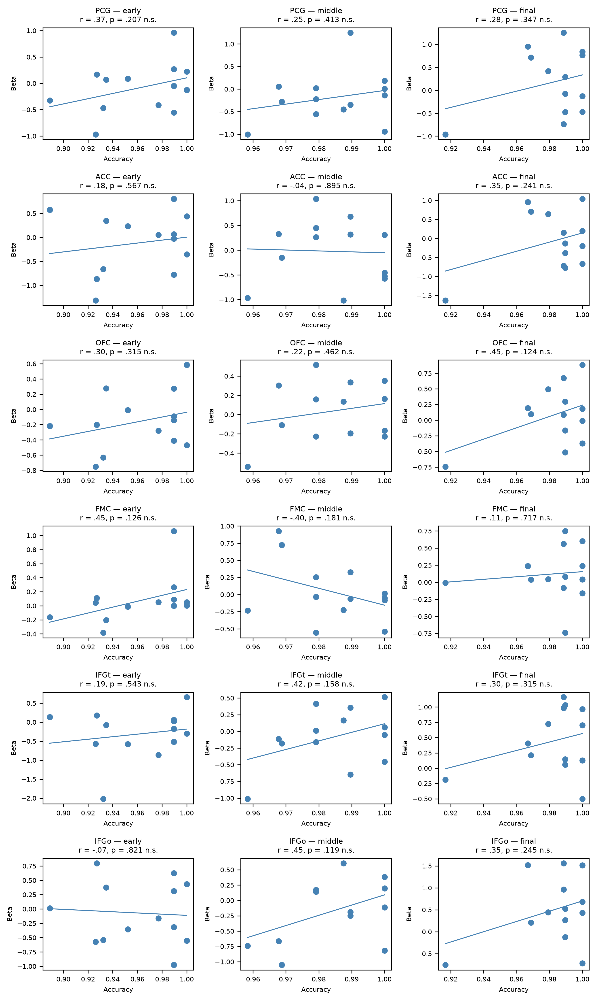

In [277]:
rois = behav_corr_df['roi'].unique()
stages = ['early', 'middle', 'final']

fig, axes = plt.subplots(len(rois), 3, figsize=(9, len(rois) * 2.5), dpi=300, sharex=False, sharey=False)

for ri, roi in enumerate(plot_order): # rois):
    for si, stage in enumerate(stages):
        ax = axes[ri, si]
        sub_df = roi_behav_df[(roi_behav_df['region'] == roi) & 
                              (roi_behav_df['learning_stage'] == stage)]
        
        ax.scatter(sub_df['accuracy'], sub_df['beta'], s=30, color='steelblue', zorder=3)
        
        # regression line
        m, b = np.polyfit(sub_df['accuracy'], sub_df['beta'], 1)
        x_range = np.linspace(sub_df['accuracy'].min(), sub_df['accuracy'].max(), 100)
        ax.plot(x_range, m * x_range + b, color='steelblue', linewidth=1)
        
        # stat annotation
        row = behav_corr_df[(behav_corr_df['roi'] == roi) & 
                            (behav_corr_df['learning_stage'] == stage)].iloc[0]
        p_str = '*' if row['p'] < 0.05 else 'n.s.'
        ax.set_title(f"{roi} — {stage}\n{row['stat_str']} {p_str}", fontsize=8)
        ax.set_xlabel('Accuracy', fontsize=7)
        ax.set_ylabel('Beta', fontsize=7)
        ax.tick_params(labelsize=7)

plt.tight_layout()
plt.savefig(os.path.join(fig_out_dir, f'brain-behav-corr_contrast-{contrast_label}_network-{network_name}_corr-plots.svg'))

PCG early: r = .37, p = .207 n.s.
PCG middle: r = .25, p = .413 n.s.
PCG final: r = .28, p = .347 n.s.
ACC early: r = .18, p = .567 n.s.
ACC middle: r = -.04, p = .895 n.s.
ACC final: r = .35, p = .241 n.s.
OFC early: r = .30, p = .315 n.s.
OFC middle: r = .22, p = .462 n.s.
OFC final: r = .45, p = .124 n.s.
FMC early: r = .45, p = .126 n.s.
FMC middle: r = -.40, p = .181 n.s.
FMC final: r = .11, p = .717 n.s.
IFGt early: r = .19, p = .543 n.s.
IFGt middle: r = .42, p = .158 n.s.
IFGt final: r = .30, p = .315 n.s.
IFGo early: r = -.07, p = .821 n.s.
IFGo middle: r = .45, p = .119 n.s.
IFGo final: r = .35, p = .245 n.s.


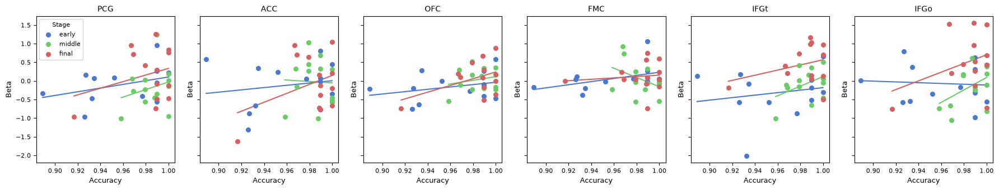

In [278]:
stage_colors = {'early': '#4878CF', 'middle': '#6ACC65', 'final': '#D65F5F'}
stages = ['early', 'middle', 'final']
rois = behav_corr_df['roi'].unique()

fig, axes = plt.subplots(1, len(rois), figsize=(3 * len(rois), 3.5), dpi=100, sharey=True)
if len(rois) == 1:
    axes = [axes]

for ri, roi in enumerate(plot_order): # rois):
    ax = axes[ri]
    for stage in stages:
        color = stage_colors[stage]
        sub_df = roi_behav_df[(roi_behav_df['region'] == roi) &
                              (roi_behav_df['learning_stage'] == stage)]

        ax.scatter(sub_df['accuracy'], sub_df['beta'], s=30,
                   color=color, label=stage, zorder=3)

        m, b = np.polyfit(sub_df['accuracy'], sub_df['beta'], 1)
        x_range = np.linspace(sub_df['accuracy'].min(), sub_df['accuracy'].max(), 100)
        ax.plot(x_range, m * x_range + b, color=color, linewidth=1.5)

        # stat annotation per stage
        row = behav_corr_df[(behav_corr_df['roi'] == roi) &
                            (behav_corr_df['learning_stage'] == stage)].iloc[0]
        p_str = '*' if row['p'] < 0.05 else 'n.s.'
        print(f"{roi} {stage}: {row['stat_str']} {p_str}")

    ax.set_title(roi, fontsize=10)
    ax.set_xlabel('Accuracy', fontsize=9)
    ax.set_ylabel('Beta', fontsize=9)
    ax.tick_params(labelsize=8)

axes[0].legend(title='Stage', fontsize=8, title_fontsize=8)
plt.tight_layout()


### omnibus ANOVA stats

In [279]:
# Mixed-Effects ANOVA with Hemisphere, Region, and Interaction
aov = AnovaRM(group_df, 
              aggregate_func='mean',
              depvar='beta', 
              subject='participant_id', 
              within=['hemisphere', 'learning_stage','region', ]).fit()

# Display results
print('network:', network_name)
print('contrast:', contrast_label)
print(aov)

network: pfc
contrast: fbcorrect
                             Anova
                                 F Value  Num DF  Den DF  Pr > F
----------------------------------------------------------------
hemisphere                        3.5181  1.0000  12.0000 0.0852
learning_stage                    4.0882  2.0000  24.0000 0.0297
region                            0.7848  5.0000  60.0000 0.5647
hemisphere:learning_stage         0.5554  2.0000  24.0000 0.5810
hemisphere:region                 0.5641  5.0000  60.0000 0.7270
learning_stage:region             2.0176 10.0000 120.0000 0.0371
hemisphere:learning_stage:region  0.8370 10.0000 120.0000 0.5940



In [280]:
export_anova(aov, f'{contrast_label}_{network_name}_hemisphere_learning-stage_region', stats_out_dir)

,source,F,df_num,df_den,p,stat_str
0,hemisphere,3.52,1.0000,12.0000,p = .085,"F(1, 12) = 3.52, p = .085"
1,learning_stage,4.09,2.0000,24.0000,p = .030,"F(2, 24) = 4.09, p = .030"
2,region,0.78,5.0000,60.0000,p = .565,"F(5, 60) = 0.78, p = .565"
3,hemisphere:learning_stage,0.56,2.0000,24.0000,p = .581,"F(2, 24) = 0.56, p = .581"
4,hemisphere:region,0.56,5.0000,60.0000,p = .727,"F(5, 60) = 0.56, p = .727"
5,learning_stage:region,2.02,10.0000,120.0000,p = .037,"F(10, 120) = 2.02, p = .037"
6,hemisphere:learning_stage:region,0.84,10.0000,120.0000,p = .594,"F(10, 120) = 0.84, p = .594"


In [281]:
# GG-corrected bilateral replication (learning_stage x region)
bilateral_df = (group_df
                .groupby(['participant_id', 'region', 'learning_stage'], as_index=False)['beta']
                .mean())
aov_pg = pg.rm_anova(data=bilateral_df, dv='beta',
                     within=['learning_stage', 'region'],
                     subject='participant_id',
                     detailed=True)
eta_col = 'np2' if 'np2' in aov_pg.columns else 'ng2'
print(aov_pg[['Source', 'F', 'ddof1', 'ddof2', 'p_unc', 'p_GG_corr', eta_col]])
export_pg_anova(aov_pg, f'{contrast_label}_{network_name}_learning-stage_region_bilateral', stats_out_dir)

                    Source      F  ddof1  ddof2  p_unc  p_GG_corr    ng2
0           learning_stage 4.0882      2     24 0.0297     0.0407 0.0694
1                   region 0.7848      5     60 0.5647     0.5026 0.0109
2  learning_stage * region 2.0176     10    120 0.0371     0.1261 0.0584


/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/pingouin/distribution.py:514: UserWarning: Epsilon values might be innaccurate in two-way repeated measures design where each  factor has more than 2 levels. Please  double-check your results.
  warnings.warn(


,source,df_num,df_den,F,p_unc,p_GG_corr,eta_p2,stat_str
0,learning_stage,2,24,4.09,p = .030,p = .041,0.07,"F(2, 24) = 4.09, p = .041"
1,region,5,60,0.78,p = .565,p = .503,0.01,"F(5, 60) = 0.78, p = .503"
2,learning_stage * region,10,120,2.02,p = .037,p = .126,0.06,"F(10, 120) = 2.02, p = .126"


In [282]:
import pingouin as pg

# Pairwise comparisons for region with FDR correction
pairwise_by_learning_stage = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['learning_stage','region', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_learning_stage.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_learning_stage)
#pairwise_by_learning_stage[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_learning_stage[pairwise_by_learning_stage.Contrast.str.contains(' * ')].reset_index()
pairwise_interaction = pairwise_interaction[pairwise_interaction['p_unc'] < 0.05].reset_index()
pairwise_interaction[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'learning_stage', 'A', 'B', 'Paired', 'Parametric', 'T',
       'dof', 'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,learning_stage,A,B,T,dof,p_unc,p_corr,BF10
0,learning_stage * region,early,FMC,IFGt,2.2094,12.0000,0.0473,0.4195,1.683
1,learning_stage * region,final,ACC,IFGo,-2.4686,12.0000,0.0296,0.4195,2.428
2,learning_stage * region,final,ACC,PCG,-2.3405,12.0000,0.0373,0.4195,2.022
3,learning_stage * region,final,IFGo,OFC,2.6110,12.0000,0.0228,0.4195,2.986
4,learning_stage * region,final,IFGt,OFC,3.4321,12.0000,0.0050,0.2235,10.3


In [283]:
# pairwise by region

# Pairwise comparisons for region with FDR correction
pairwise_by_region = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['region', 'learning_stage',],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_region.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_region)
#pairwise_by_region[['Contrast', 'learning_stage', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns

pd.set_option('display.max_rows', None)

pairwise_interaction = pairwise_by_region[pairwise_by_region.Contrast.str.contains(' * ')].reset_index()
pairwise_interaction = pairwise_interaction[pairwise_interaction['p_unc'] < 0.05]
pairwise_interaction[['Contrast', 'region', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]

Available columns: Index(['Contrast', 'region', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof',
       'alternative', 'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,region,A,B,T,dof,p_unc,p_corr,BF10
6,region * learning_stage,IFGo,early,final,-2.4887,12.0000,0.0285,0.1303,2.499
8,region * learning_stage,IFGo,final,middle,2.4799,12.0000,0.0290,0.1303,2.468
9,region * learning_stage,IFGt,early,final,-2.8950,12.0000,0.0135,0.1303,4.554
11,region * learning_stage,IFGt,final,middle,2.7594,12.0000,0.0173,0.1303,3.718


In [284]:
export_posthoc(pairwise_by_region, f'{contrast_label}_{network_name}_region_learning-stage', stats_out_dir)

,Contrast,region,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,region,-,ACC,FMC,-1.18,12.0000,p = .260,p = .681,"t(12) = -1.18, p = .260","t(12) = -1.18, q = .681"
1,region,-,ACC,IFGo,-1.30,12.0000,p = .220,p = .681,"t(12) = -1.30, p = .220","t(12) = -1.30, q = .681"
2,region,-,ACC,IFGt,-0.64,12.0000,p = .531,p = .798,"t(12) = -0.64, p = .531","t(12) = -0.64, q = .798"
3,region,-,ACC,OFC,-0.48,12.0000,p = .641,p = .798,"t(12) = -0.48, p = .641","t(12) = -0.48, q = .798"
4,region,-,ACC,PCG,-0.48,12.0000,p = .643,p = .798,"t(12) = -0.48, p = .643","t(12) = -0.48, q = .798"
5,region,-,FMC,IFGo,-0.12,12.0000,p = .910,p = .910,"t(12) = -0.12, p = .910","t(12) = -0.12, q = .910"
6,region,-,FMC,IFGt,0.73,12.0000,p = .482,p = .798,"t(12) = 0.73, p = .482","t(12) = 0.73, q = .798"
7,region,-,FMC,OFC,1.16,12.0000,p = .268,p = .681,"t(12) = 1.16, p = .268","t(12) = 1.16, q = .681"
8,region,-,FMC,PCG,1.09,12.0000,p = .296,p = .681,"t(12) = 1.09, p = .296","t(12) = 1.09, q = .681"
9,region,-,IFGo,IFGt,1.04,12.0000,p = .318,p = .681,"t(12) = 1.04, p = .318","t(12) = 1.04, q = .681"


In [285]:
# pairwise by region, no learning stage

# Pairwise comparisons for region with FDR correction
pairwise_by_region_only = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['region', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_region_only.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_region_only)
#pairwise_by_region_only = pairwise_by_region_only[pairwise_by_region_only['p_unc'] < 0.05]
pairwise_by_region_only[['Contrast', 'Contrast', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns


Available columns: Index(['Contrast', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof', 'alternative',
       'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,Contrast,A,B,T,dof,p_unc,p_corr,BF10
0,region,region,ACC,FMC,-1.1811,12.0000,0.2604,0.6815,0.497
1,region,region,ACC,IFGo,-1.2951,12.0000,0.2196,0.6815,0.555
2,region,region,ACC,IFGt,-0.6445,12.0000,0.5314,0.7976,0.333
3,region,region,ACC,OFC,-0.4790,12.0000,0.6405,0.7976,0.307
4,region,region,ACC,PCG,-0.4756,12.0000,0.6429,0.7976,0.307
5,region,region,FMC,IFGo,-0.1156,12.0000,0.9099,0.9099,0.28
6,region,region,FMC,IFGt,0.7250,12.0000,0.4823,0.7976,0.349
7,region,region,FMC,OFC,1.1624,12.0000,0.2677,0.6815,0.488
8,region,region,FMC,PCG,1.0917,12.0000,0.2964,0.6815,0.459
9,region,region,IFGo,IFGt,1.0418,12.0000,0.3180,0.6815,0.439


In [286]:
export_posthoc(pairwise_by_region_only, f'{contrast_label}_{network_name}_region', stats_out_dir)

,Contrast,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,region,ACC,FMC,-1.18,12.0000,p = .260,p = .681,"t(12) = -1.18, p = .260","t(12) = -1.18, q = .681"
1,region,ACC,IFGo,-1.30,12.0000,p = .220,p = .681,"t(12) = -1.30, p = .220","t(12) = -1.30, q = .681"
2,region,ACC,IFGt,-0.64,12.0000,p = .531,p = .798,"t(12) = -0.64, p = .531","t(12) = -0.64, q = .798"
3,region,ACC,OFC,-0.48,12.0000,p = .641,p = .798,"t(12) = -0.48, p = .641","t(12) = -0.48, q = .798"
4,region,ACC,PCG,-0.48,12.0000,p = .643,p = .798,"t(12) = -0.48, p = .643","t(12) = -0.48, q = .798"
5,region,FMC,IFGo,-0.12,12.0000,p = .910,p = .910,"t(12) = -0.12, p = .910","t(12) = -0.12, q = .910"
6,region,FMC,IFGt,0.73,12.0000,p = .482,p = .798,"t(12) = 0.73, p = .482","t(12) = 0.73, q = .798"
7,region,FMC,OFC,1.16,12.0000,p = .268,p = .681,"t(12) = 1.16, p = .268","t(12) = 1.16, q = .681"
8,region,FMC,PCG,1.09,12.0000,p = .296,p = .681,"t(12) = 1.09, p = .296","t(12) = 1.09, q = .681"
9,region,IFGo,IFGt,1.04,12.0000,p = .318,p = .681,"t(12) = 1.04, p = .318","t(12) = 1.04, q = .681"


In [287]:
# pairwise by learning stage, no region

# Pairwise comparisons for region with FDR correction
pairwise_by_learning_stage_only = pg.pairwise_tests(data=group_df,
                             dv='beta', 
                             within=['learning_stage', ],
                             subject='participant_id',
                             padjust='fdr') 

# Check available columns
print("Available columns:", pairwise_by_learning_stage_only.columns)

# Display key columns (without 'effsize' and 'CIs' if missing)
print("\nPost-hoc Pairwise Comparisons:")
#print(pairwise_by_learning_stage_only)
#pairwise_by_learning_stage_only = pairwise_by_learning_stage_only[pairwise_by_learning_stage_only['p_unc'] < 0.05]
pairwise_by_learning_stage_only[['Contrast', 'Contrast', 'A', 'B', 'T', 'dof', 'p_unc', 'p_corr', 'BF10']]  # Keep only available columns


Available columns: Index(['Contrast', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof', 'alternative',
       'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

Post-hoc Pairwise Comparisons:


,Contrast,Contrast,A,B,T,dof,p_unc,p_corr,BF10
0,learning_stage,learning_stage,early,final,-3.6087,12.0000,0.0036,0.0108,13.497
1,learning_stage,learning_stage,early,middle,-0.3724,12.0000,0.7161,0.7161,0.296
2,learning_stage,learning_stage,final,middle,1.9193,12.0000,0.0790,0.1185,1.142


In [288]:
export_posthoc(pairwise_by_learning_stage_only, f'{contrast_label}_{network_name}_learning-stage', stats_out_dir)

,Contrast,A,B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,learning_stage,early,final,-3.61,12.0000,p = .004,p = .011,"t(12) = -3.61, p = .004","t(12) = -3.61, q = .011"
1,learning_stage,early,middle,-0.37,12.0000,p = .716,p = .716,"t(12) = -0.37, p = .716","t(12) = -0.37, q = .716"
2,learning_stage,final,middle,1.92,12.0000,p = .079,p = .119,"t(12) = 1.92, p = .079","t(12) = 1.92, q = .119"


### Collapse (average) over non-significant factors

In [289]:
roi_df_collapsed = group_df.groupby(["participant_id", "region", 'learning_stage'], 
                                       as_index=False).agg({"beta": "mean"})


In [290]:
roi_df_collapsed.head()

,participant_id,region,learning_stage,beta
0,sub-FLT03,ACC,early,0.8036
1,sub-FLT03,ACC,final,0.9589
2,sub-FLT03,ACC,middle,0.6811
3,sub-FLT03,FMC,early,1.0642
4,sub-FLT03,FMC,final,0.2389


In [291]:
# Collect results
results = []

for (region, stage), data in roi_df_collapsed.groupby(["region", "learning_stage"]):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    results.append({
        "region": region,
        "learning_stage": stage,
        "t_stat": t_stat,
        "p_val": p_val
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Apply FDR correction
results_df["p_val_fdr"] = multipletests(results_df["p_val"], method="fdr_bh")[1]

# Optional: export
# results_df.to_csv("roi_stats.csv", index=False)
# results_df.to_excel("roi_stats.xlsx", index=False)


In [292]:
_export = results_df.rename(columns={'t_stat': 't', 'p_val': 'p'}).copy()
_export['df'] = len(sub_list) - 1
export_ttests(_export.to_dict('records'), f'{contrast_label}_{network_name}_baseline_by_region_learning-stage', stats_out_dir)

,region,learning_stage,t,p,p_val_fdr,df,p_fdr,stat_str,stat_str_fdr
0,ACC,early,-0.65,p = .529,0.7319,12,p = .732,"t(12) = -0.65, p = .529","t(12) = -0.65, q = .732"
1,ACC,final,-0.28,p = .788,0.8342,12,p = .834,"t(12) = -0.28, p = .788","t(12) = -0.28, q = .834"
2,ACC,middle,-0.13,p = .897,0.8967,12,p = .897,"t(12) = -0.13, p = .897","t(12) = -0.13, q = .897"
3,FMC,early,0.74,p = .472,0.7319,12,p = .732,"t(12) = 0.74, p = .472","t(12) = 0.74, q = .732"
4,FMC,final,1.16,p = .267,0.6875,12,p = .688,"t(12) = 1.16, p = .267","t(12) = 1.16, q = .688"
5,FMC,middle,0.30,p = .770,0.8342,12,p = .834,"t(12) = 0.30, p = .770","t(12) = 0.30, q = .834"
6,IFGo,early,-0.47,p = .646,0.7945,12,p = .795,"t(12) = -0.47, p = .646","t(12) = -0.47, q = .795"
7,IFGo,final,2.36,p = .036,0.3254,12,p = .325,"t(12) = 2.36, p = .036","t(12) = 2.36, q = .325"
8,IFGo,middle,-1.18,p = .262,0.6875,12,p = .688,"t(12) = -1.18, p = .262","t(12) = -1.18, q = .688"
9,IFGt,early,-1.72,p = .111,0.6640,12,p = .664,"t(12) = -1.72, p = .111","t(12) = -1.72, q = .664"


In [293]:
# Collect results
results = []

# average within participant first: one value per participant, so n (and df) = number of participants
for region, data in (roi_df_collapsed.groupby(["participant_id", "region"], as_index=False)["beta"].mean()
                     .groupby("region")):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    results.append({
        "region": region,
        "t_stat": t_stat,
        "p_val": p_val
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Apply FDR correction
results_df["p_val_fdr"] = multipletests(results_df["p_val"], method="fdr_bh")[1]

# Optional: export
# results_df.to_csv("roi_stats.csv", index=False)
# results_df.to_excel("roi_stats.xlsx", index=False)


In [294]:
_export = results_df.rename(columns={'t_stat': 't', 'p_val': 'p'}).copy()
_export['df'] = len(sub_list) - 1
export_ttests(_export.to_dict('records'), f'{contrast_label}_{network_name}_baseline_by_region', stats_out_dir)

,region,t,p,p_val_fdr,df,p_fdr,stat_str,stat_str_fdr
0,ACC,-0.48,p = .641,0.8653,12,p = .865,"t(12) = -0.48, p = .641","t(12) = -0.48, q = .865"
1,FMC,1.48,p = .165,0.8653,12,p = .865,"t(12) = 1.48, p = .165","t(12) = 1.48, q = .865"
2,IFGo,0.88,p = .397,0.8653,12,p = .865,"t(12) = 0.88, p = .397","t(12) = 0.88, q = .865"
3,IFGt,0.23,p = .820,0.8653,12,p = .865,"t(12) = 0.23, p = .820","t(12) = 0.23, q = .865"
4,OFC,-0.17,p = .865,0.8653,12,p = .865,"t(12) = -0.17, p = .865","t(12) = -0.17, q = .865"
5,PCG,-0.24,p = .811,0.8653,12,p = .865,"t(12) = -0.24, p = .811","t(12) = -0.24, q = .865"


### Cortical surface plot (t-statistic, by hemisphere)

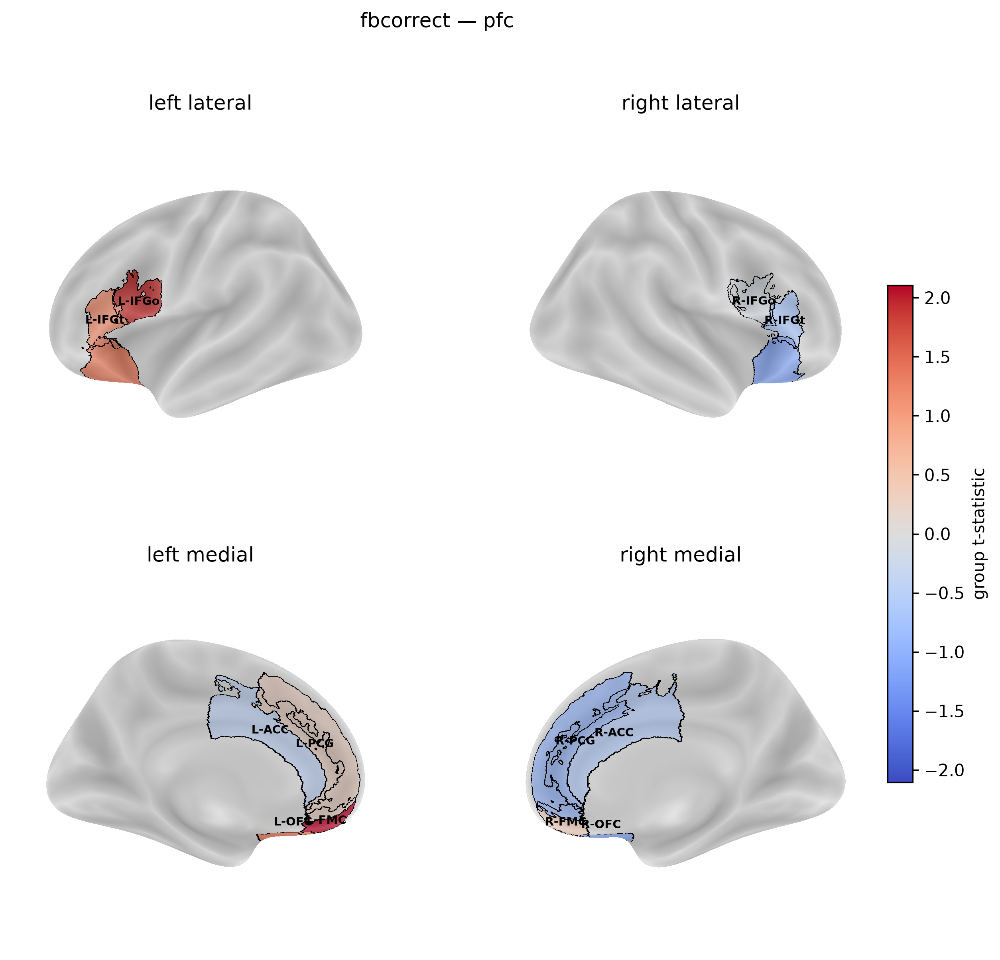

In [295]:
roi_df_collapsed_hemi = group_df.groupby(["participant_id", "region", "hemisphere"],
                                                 as_index=False).agg({"beta": "mean"})

p_values = []
t_stats = []
comparisons = []
for (region, hemi), data in roi_df_collapsed_hemi.groupby(["region", "hemisphere"]):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    p_values.append(p_val)
    comparisons.append((region, hemi, t_stat))
    t_stats.append(t_stat)

stat_dict = {f"{hemi}-{region}": t for (region, hemi, t) in comparisons}
mask_path_dict = build_mask_path_dict(list(stat_dict.keys()), masks_dir, network_name, surf_space_label)

surface_views = ('lateral',) if network_name == 'auditory' else ('lateral', 'medial')
fig = plot_roi_surface_stat(stat_dict, mask_path_dict, title=f'{contrast_label} — {network_name}', views=surface_views, fsaverage=fsaverage)
#fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat.svg'))
fig.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat.png'))


### Cortical surface plot (t-statistic, final vs. early)

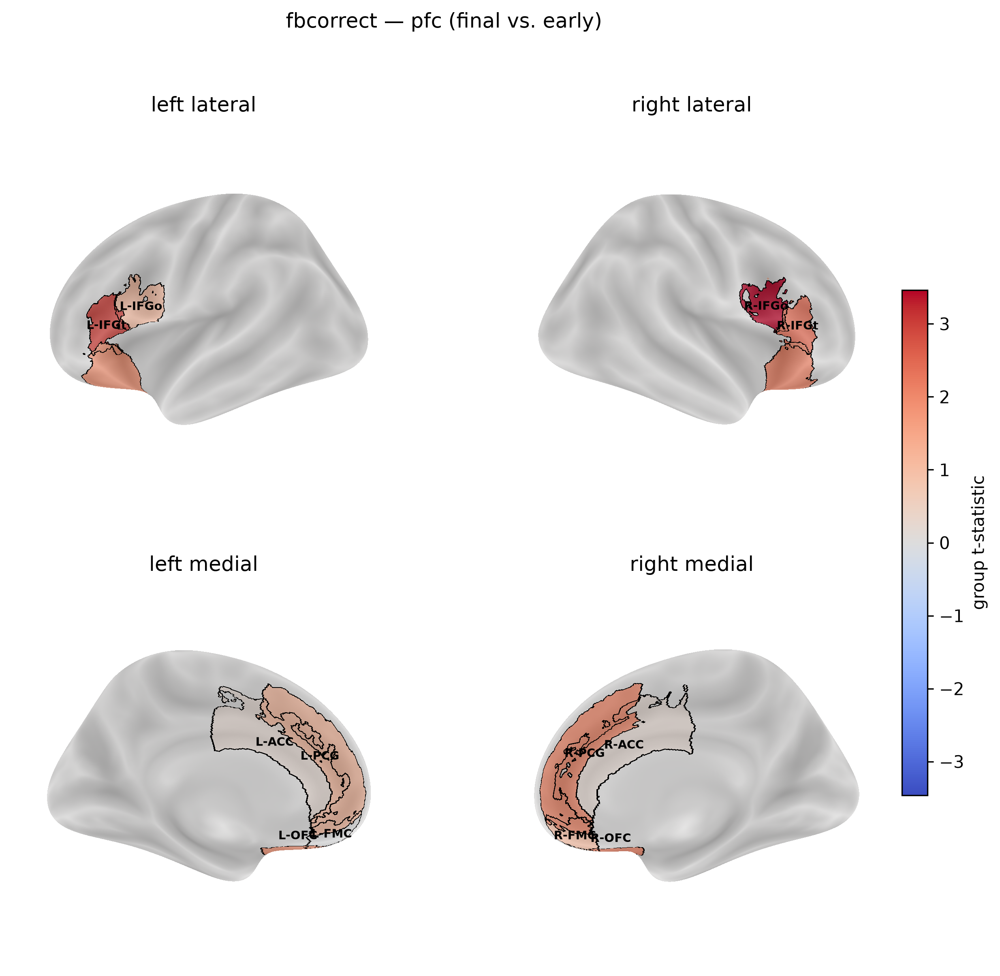

In [296]:
# Learning-stage difference (final vs. early)
_diff_df = (group_df[group_df['learning_stage'].isin(['early', 'final'])]
            .groupby(['participant_id', 'region_hemi', 'learning_stage'], as_index=False)['beta'].mean()
            .pivot(index=['participant_id', 'region_hemi'], columns='learning_stage', values='beta')
            .dropna()
            .reset_index())

diff_stat_dict = {}
for region_hemi, data in _diff_df.groupby('region_hemi'):
    t_stat, _ = ttest_rel(data['final'], data['early'])
    diff_stat_dict[region_hemi] = t_stat

mask_path_dict_diff = build_mask_path_dict(list(diff_stat_dict.keys()), masks_dir, network_name, surf_space_label)
surface_views_diff = ('lateral',) if network_name == 'auditory' else ('lateral', 'medial')
fig_diff = plot_roi_surface_stat(diff_stat_dict, mask_path_dict_diff,
                                  title=f'{contrast_label} — {network_name} (final vs. early)',
                                  views=surface_views_diff, fsaverage=fsaverage)
#fig_diff.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat_diff-final-early.svg'))
fig_diff.savefig(os.path.join(fig_out_dir, f'network-{network_name}_contrast-{contrast_label}_surface-tstat_diff-final-early.png'))


In [297]:
# Collect p-values
p_values = []
t_stats = []
comparisons = []

for region_stage, data in roi_df_collapsed.groupby(["region",'learning_stage']):
    #print(region_stage)
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    p_values.append(p_val)
    comparisons.append((region_stage[0], region_stage[1], t_stat))
    t_stats.append(t_stat)

# Apply FDR correction
_, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Print corrected results
for (region, learning_stage, t_stat), p_val_corr in zip(comparisons, p_corrected):
    print(f"Region: {region}, learning_stage: {learning_stage}, t = {t_stat:.2f}; corrected p = {p_val_corr:.4f}")


Region: ACC, learning_stage: early, t = -0.65; corrected p = 0.7319
Region: ACC, learning_stage: final, t = -0.28; corrected p = 0.8342
Region: ACC, learning_stage: middle, t = -0.13; corrected p = 0.8967
Region: FMC, learning_stage: early, t = 0.74; corrected p = 0.7319
Region: FMC, learning_stage: final, t = 1.16; corrected p = 0.6875
Region: FMC, learning_stage: middle, t = 0.30; corrected p = 0.8342
Region: IFGo, learning_stage: early, t = -0.47; corrected p = 0.7945
Region: IFGo, learning_stage: final, t = 2.36; corrected p = 0.3254
Region: IFGo, learning_stage: middle, t = -1.18; corrected p = 0.6875
Region: IFGt, learning_stage: early, t = -1.72; corrected p = 0.6640
Region: IFGt, learning_stage: final, t = 3.10; corrected p = 0.1642
Region: IFGt, learning_stage: middle, t = -0.71; corrected p = 0.7319
Region: OFC, learning_stage: early, t = -1.52; corrected p = 0.6875
Region: OFC, learning_stage: final, t = 0.67; corrected p = 0.7319
Region: OFC, learning_stage: middle, t = 0.4

In [298]:
_records = [{'region': c[0], 'learning_stage': c[1], 't': c[2], 'df': len(sub_list) - 1, 'p': p}
            for c, p in zip(comparisons, p_values)]
export_ttests(_records, f'{contrast_label}_{network_name}_baseline_by_region_learning-stage', stats_out_dir)

,region,learning_stage,t,df,p,p_fdr,stat_str,stat_str_fdr
0,ACC,early,-0.65,12,p = .529,p = .732,"t(12) = -0.65, p = .529","t(12) = -0.65, q = .732"
1,ACC,final,-0.28,12,p = .788,p = .834,"t(12) = -0.28, p = .788","t(12) = -0.28, q = .834"
2,ACC,middle,-0.13,12,p = .897,p = .897,"t(12) = -0.13, p = .897","t(12) = -0.13, q = .897"
3,FMC,early,0.74,12,p = .472,p = .732,"t(12) = 0.74, p = .472","t(12) = 0.74, q = .732"
4,FMC,final,1.16,12,p = .267,p = .688,"t(12) = 1.16, p = .267","t(12) = 1.16, q = .688"
5,FMC,middle,0.30,12,p = .770,p = .834,"t(12) = 0.30, p = .770","t(12) = 0.30, q = .834"
6,IFGo,early,-0.47,12,p = .646,p = .795,"t(12) = -0.47, p = .646","t(12) = -0.47, q = .795"
7,IFGo,final,2.36,12,p = .036,p = .325,"t(12) = 2.36, p = .036","t(12) = 2.36, q = .325"
8,IFGo,middle,-1.18,12,p = .262,p = .688,"t(12) = -1.18, p = .262","t(12) = -1.18, q = .688"
9,IFGt,early,-1.72,12,p = .111,p = .664,"t(12) = -1.72, p = .111","t(12) = -1.72, q = .664"


In [299]:
# Collect p-values
p_values = []
t_stats = []
comparisons = []

# average within participant first: one value per participant, so n (and df) = number of participants
for learning_stage, data in (roi_df_collapsed.groupby(["participant_id", "learning_stage"], as_index=False)["beta"].mean()
                     .groupby(["learning_stage"])):
    t_stat, p_val = ttest_1samp(data["beta"], 0)
    p_values.append(p_val)
    comparisons.append((learning_stage[0], t_stat))
    t_stats.append(t_stat)

# Apply FDR correction
_, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Print corrected results
for (learning_stage, t_stat), p_val_corr in zip(comparisons, p_corrected):
    print(f"learning_stage: {learning_stage}, t = {t_stat:.2f}; corrected p = {p_val_corr:.4f}")


learning_stage: early, t = -1.15; corrected p = 0.4094
learning_stage: final, t = 1.75; corrected p = 0.3189
learning_stage: middle, t = -0.75; corrected p = 0.4703


In [300]:
_records = [{'learning_stage': c[0], 't': c[1], 'df': len(sub_list) - 1, 'p': p}
            for c, p in zip(comparisons, p_values)]
export_ttests(_records, f'{contrast_label}_{network_name}_baseline_by_region', stats_out_dir)

,learning_stage,t,df,p,p_fdr,stat_str,stat_str_fdr
0,early,-1.15,12,p = .273,p = .409,"t(12) = -1.15, p = .273","t(12) = -1.15, q = .409"
1,final,1.75,12,p = .106,p = .319,"t(12) = 1.75, p = .106","t(12) = 1.75, q = .319"
2,middle,-0.75,12,p = .470,p = .470,"t(12) = -0.75, p = .470","t(12) = -0.75, q = .470"


## Compare contrasts

In [301]:
sound_striatum_df['event_type'] = 'sound'
sound_striatum_df['network'] = 'striatum'

feedback_striatum_df['event_type'] = 'feedback'
feedback_striatum_df['network'] = 'striatum'

sound_cortex_df['event_type'] = 'sound'
sound_cortex_df['network'] = 'cortex'

feedback_cortex_df['event_type'] = 'feedback'
feedback_cortex_df['network'] = 'cortex'

sound_pfc_df['event_type'] = 'sound'
sound_pfc_df['network'] = 'pfc'

feedback_pfc_df['event_type'] = 'feedback'
feedback_pfc_df['network'] = 'pfc'

all_df = pd.concat([sound_striatum_df, feedback_striatum_df,
                    sound_cortex_df, feedback_cortex_df,
                    sound_pfc_df, feedback_pfc_df,])


In [302]:
from statsmodels.stats.anova import AnovaRM

results = []
for roi in all_df['region'].unique():
    sub_df = all_df[all_df['region'] == roi]
    
    aov = AnovaRM(data=sub_df, depvar='beta', subject='participant_id',
                  within=['event_type', 'learning_stage']).fit()
    
    table = aov.anova_table
    
    for effect in ['event_type', 'learning_stage', 'event_type:learning_stage']:
        row = table.loc[effect]
        results.append({
            'roi': roi,
            'effect': effect,
            'F': row['F Value'],
            'df_num': row['Num DF'],
            'df_den': row['Den DF'],
            'p': row['Pr > F'],
            'stat_str': stat_str('F', int(row['Num DF']), int(row['Den DF']),
                                 row['F Value'], row['Pr > F'])
        })

interaction_df = pd.DataFrame(results)


In [303]:
interaction_df.sort_values(by=['effect', 'roi'])

,roi,effect,F,df_num,df_den,p,stat_str
39,ACC,event_type,0.1565,1.0000,12.0000,0.6994,"F(1, 12) = 0.16, p = .699"
42,FMC,event_type,3.6399,1.0000,12.0000,0.0806,"F(1, 12) = 3.64, p = .081"
45,FO,event_type,14.4877,1.0000,12.0000,0.0025,"F(1, 12) = 14.49, p = .003"
48,FP,event_type,8.8414,1.0000,12.0000,0.0116,"F(1, 12) = 8.84, p = .012"
18,HG,event_type,55.5749,1.0000,12.0000,0.0000,"F(1, 12) = 55.57, p < .001"
51,IFGo,event_type,6.3676,1.0000,12.0000,0.0267,"F(1, 12) = 6.37, p = .027"
54,IFGt,event_type,2.2957,1.0000,12.0000,0.1556,"F(1, 12) = 2.30, p = .156"
57,MFG,event_type,0.0084,1.0000,12.0000,0.9287,"F(1, 12) = 0.01, p = .929"
0,NAc-core,event_type,6.4132,1.0000,12.0000,0.0263,"F(1, 12) = 6.41, p = .026"
3,NAc-shell,event_type,6.9221,1.0000,12.0000,0.0219,"F(1, 12) = 6.92, p = .022"


In [304]:
from statsmodels.stats.multitest import multipletests

for effect, grp in interaction_df.groupby('effect'):
    _, q = multipletests(grp['p'], method='fdr_bh')[:2]
    interaction_df.loc[grp.index, 'q'] = q

interaction_df['stat_str_fdr'] = interaction_df.apply(
    lambda r: stat_str_fdr('F', int(r['df_num']), int(r['df_den']), r['F'], r['p'], r['q']), axis=1)

interaction_df.to_csv(os.path.join(stats_out_dir, 'compare_contrasts_anova.tsv'), 
                      sep='\t', index=False, float_format='%.4f')


In [305]:
from statsmodels.stats.anova import AnovaRM

pput_df = all_df[all_df['region'] == 'pPUT']

for event in ['sound', 'feedback']:
    sub_df = pput_df[pput_df['event_type'] == event]
    aov = AnovaRM(data=sub_df, depvar='beta', subject='participant_id',
                  within=['learning_stage']).fit()
    print(f'\n--- pPUT {event} ---')
    print(aov.anova_table)



--- pPUT sound ---
                F Value  Num DF  Den DF  Pr > F
learning_stage   0.6416  2.0000 24.0000  0.5352

--- pPUT feedback ---
                F Value  Num DF  Den DF  Pr > F
learning_stage   0.7068  2.0000 24.0000  0.5032


In [306]:
pput_event_results = []
for event in ['sound', 'feedback']:
    sub_df = pput_df[pput_df['event_type'] == event]
    aov = AnovaRM(data=sub_df, depvar='beta', subject='participant_id',
                  within=['learning_stage']).fit()
    row = aov.anova_table.loc['learning_stage']
    pput_event_results.append({
        'event_type': event,
        'F': row['F Value'], 'df_num': row['Num DF'], 'df_den': row['Den DF'], 'p': row['Pr > F'],
        'stat_str': stat_str('F', int(row['Num DF']), int(row['Den DF']), row['F Value'], row['Pr > F'])
    })
pd.DataFrame(pput_event_results).to_csv(
    os.path.join(stats_out_dir, 'compare_contrasts_pPUT_by_event_anova.tsv'), sep='\t', index=False, float_format='%.4f')


In [307]:
from statsmodels.stats.anova import AnovaRM

pput_df = all_df[all_df['region'] == 'pPUT']

for learning_stage in ['early', 'middle', 'final']:
    sub_df = pput_df[pput_df['learning_stage'] == learning_stage]
    aov = AnovaRM(data=sub_df, depvar='beta', subject='participant_id',
                  within=['event_type']).fit()
    print(f'\n--- pPUT {learning_stage} ---')
    print(aov.anova_table)


--- pPUT early ---
            F Value  Num DF  Den DF  Pr > F
event_type  15.8347  1.0000 12.0000  0.0018

--- pPUT middle ---
            F Value  Num DF  Den DF  Pr > F
event_type   4.4035  1.0000 12.0000  0.0577

--- pPUT final ---
            F Value  Num DF  Den DF  Pr > F
event_type   5.3043  1.0000 12.0000  0.0400


In [308]:
pput_stage_results = []
for stage in ['early', 'middle', 'final']:
    sub_df = pput_df[pput_df['learning_stage'] == stage]
    aov = AnovaRM(data=sub_df, depvar='beta', subject='participant_id',
                  within=['event_type']).fit()
    row = aov.anova_table.loc['event_type']
    pput_stage_results.append({
        'learning_stage': stage,
        'F': row['F Value'], 'df_num': row['Num DF'], 'df_den': row['Den DF'], 'p': row['Pr > F'],
        'stat_str': stat_str('F', int(row['Num DF']), int(row['Den DF']), row['F Value'], row['Pr > F'])
    })
pd.DataFrame(pput_stage_results).to_csv(
    os.path.join(stats_out_dir, 'compare_contrasts_pPUT_by_stage_anova.tsv'), sep='\t', index=False, float_format='%.4f')


In [309]:
from scipy.stats import ttest_rel

stage_pairs = [('early', 'middle'), ('middle', 'final'), ('early', 'final')]

for event in ['sound', 'feedback']:
    print(f'\n--- pPUT {event} ---')
    sub_df = pput_df[pput_df['event_type'] == event]
    
    for s1, s2 in stage_pairs:
        vals1 = sub_df[sub_df['learning_stage'] == s1].set_index('participant_id')['beta']
        vals2 = sub_df[sub_df['learning_stage'] == s2].set_index('participant_id')['beta']
        # align by subject
        vals1, vals2 = vals1.align(vals2)
        t, p = ttest_rel(vals1, vals2)
        print(f"  {s1} vs {s2}: {stat_str('t', len(sub_list) - 1, t, p)}")



--- pPUT sound ---
  early vs middle: t(12) = 0.74, p = .476
  middle vs final: t(12) = 0.50, p = .626
  early vs final: t(12) = 1.03, p = .323

--- pPUT feedback ---
  early vs middle: t(12) = -0.18, p = .858
  middle vs final: t(12) = 1.13, p = .282
  early vs final: t(12) = 0.83, p = .420


In [310]:
records = []
for event in ['sound', 'feedback']:
    sub_df = pput_df[pput_df['event_type'] == event]
    for s1, s2 in stage_pairs:
        vals1 = sub_df[sub_df['learning_stage'] == s1].set_index('participant_id')['beta']
        vals2 = sub_df[sub_df['learning_stage'] == s2].set_index('participant_id')['beta']
        vals1, vals2 = vals1.align(vals2)
        t, p = ttest_rel(vals1, vals2)
        records.append({'event_type': event, 'stage_A': s1, 'stage_B': s2, 
                        't': t, 'df': len(sub_list) - 1, 'p': p})
export_ttests(records, 'pPUT_stage_pairs', stats_out_dir)


,event_type,stage_A,stage_B,t,df,p,p_fdr,stat_str,stat_str_fdr
0,sound,early,middle,0.74,12,p = .476,p = .715,"t(12) = 0.74, p = .476","t(12) = 0.74, q = .715"
1,sound,middle,final,0.50,12,p = .626,p = .751,"t(12) = 0.50, p = .626","t(12) = 0.50, q = .751"
2,sound,early,final,1.03,12,p = .323,p = .715,"t(12) = 1.03, p = .323","t(12) = 1.03, q = .715"
3,feedback,early,middle,-0.18,12,p = .858,p = .858,"t(12) = -0.18, p = .858","t(12) = -0.18, q = .858"
4,feedback,middle,final,1.13,12,p = .282,p = .715,"t(12) = 1.13, p = .282","t(12) = 1.13, q = .715"
5,feedback,early,final,0.83,12,p = .420,p = .715,"t(12) = 0.83, p = .420","t(12) = 0.83, q = .715"


In [311]:
from scipy.stats import ttest_1samp

for event in ['sound', 'feedback']:
    print(f'\n--- pPUT {event} ---')
    sub_df = pput_df[pput_df['event_type'] == event]
    
    for learning_stage in ['early', 'middle', 'final']:
        vals1 = sub_df[sub_df['learning_stage'] == learning_stage].set_index('participant_id')['beta']
        t, p = ttest_1samp(vals1, popmean=0)
        print(f"  {event} vs {0}: {stat_str('t', len(sub_list) - 1, t, p)}")



--- pPUT sound ---
  sound vs 0: t(12) = 4.31, p = .001
  sound vs 0: t(12) = 2.39, p = .034
  sound vs 0: t(12) = 1.95, p = .075

--- pPUT feedback ---
  feedback vs 0: t(12) = 1.28, p = .226
  feedback vs 0: t(12) = 2.71, p = .019
  feedback vs 0: t(12) = 0.01, p = .995


In [312]:
records = []
for event in ['sound', 'feedback']:
    sub_df = pput_df[pput_df['event_type'] == event]
    for stage in ['early', 'middle', 'final']:
        vals = sub_df[sub_df['learning_stage'] == stage].set_index('participant_id')['beta']
        t, p = ttest_1samp(vals, popmean=0)
        records.append({'event_type': event, 'learning_stage': stage, 't': t, 'df': len(sub_list) - 1, 'p': p})
export_ttests(records, 'pPUT_vs_baseline', stats_out_dir)


,event_type,learning_stage,t,df,p,p_fdr,stat_str,stat_str_fdr
0,sound,early,4.31,12,p = .001,p = .006,"t(12) = 4.31, p = .001","t(12) = 4.31, q = .006"
1,sound,middle,2.39,12,p = .034,p = .068,"t(12) = 2.39, p = .034","t(12) = 2.39, q = .068"
2,sound,final,1.95,12,p = .075,p = .113,"t(12) = 1.95, p = .075","t(12) = 1.95, q = .113"
3,feedback,early,1.28,12,p = .226,p = .272,"t(12) = 1.28, p = .226","t(12) = 1.28, q = .272"
4,feedback,middle,2.71,12,p = .019,p = .057,"t(12) = 2.71, p = .019","t(12) = 2.71, q = .057"
5,feedback,final,0.01,12,p = .995,p = .995,"t(12) = 0.01, p = .995","t(12) = 0.01, q = .995"


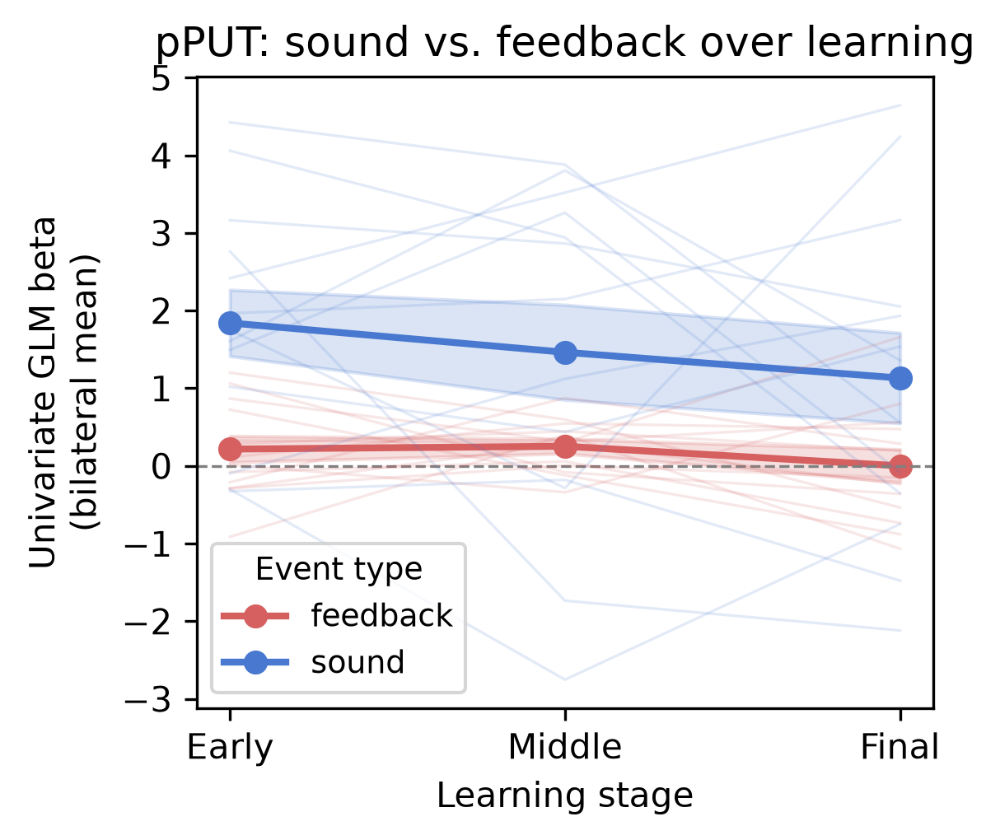

In [313]:
import matplotlib.pyplot as plt
import numpy as np

pput_df = all_df[all_df['region'] == 'pPUT']

# compute means and SEM across subjects
summary = (pput_df.groupby(['event_type', 'learning_stage'])['beta']
           .agg(['mean', 'sem'])
           .reset_index())

stage_order = ['early', 'middle', 'final']
stage_x = {s: i for i, s in enumerate(stage_order)}
event_colors = {'sound': '#4878CF', 'feedback': '#D65F5F'}

fig, ax = plt.subplots(figsize=(4, 3.5), dpi=300)

for event, grp in summary.groupby('event_type'):
    grp = grp.set_index('learning_stage').loc[stage_order].reset_index()
    x = [stage_x[s] for s in grp['learning_stage']]
    color = event_colors[event]
    
    ax.plot(x, grp['mean'], marker='o', color=color, label=event, linewidth=2)
    ax.fill_between(x,
                    grp['mean'] - grp['sem'],
                    grp['mean'] + grp['sem'],
                    alpha=0.2, color=color)

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['Early', 'Middle', 'Final'])
ax.set_xlabel('Learning stage')
ax.set_ylabel('Univariate GLM beta\n(bilateral mean)')
ax.set_title('pPUT: sound vs. feedback over learning')
ax.legend(title='Event type', fontsize=9, title_fontsize=9)
ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')

for event, grp in pput_df.groupby('event_type'):
    grp = grp.set_index('learning_stage').loc[stage_order].reset_index() \
             if False else grp  # reorder not needed here
    color = event_colors[event]
    for sub, sdf in grp.groupby('participant_id'):
        sdf = sdf.set_index('learning_stage').reindex(stage_order).reset_index()
        ax.plot([stage_x[s] for s in sdf['learning_stage']],
                sdf['beta'], color=color, alpha=0.15, linewidth=0.8)


plt.tight_layout()
plt.savefig(os.path.join(fig_out_dir, 'interaction_pPUT.svg'))

In [314]:
# export per-subject feedback learning-stage trends for 09_integration (Phase 1)
from robustness_checks import load_subject_region_stage_means, compute_subject_trends

fb_striatum_fpath = os.path.join(group_out_dir,
    f'univariate-results_network-{network_list[1]}_contrast-{contrast_list[2]}{group_suffix}.tsv')
print(fb_striatum_fpath)

fb_means = load_subject_region_stage_means(fb_striatum_fpath, ['aCAU', 'aPUT'], sep='\t')

trend_df = pd.concat([compute_subject_trends(fb_means, 'aCAU'),
                      compute_subject_trends(fb_means, 'aPUT')], axis=1)
trend_df['aCAU_minus_aPUT_trend'] = trend_df['aCAU_trend'] - trend_df['aPUT_trend']
trend_df.index.name = 'participant_id'

assert len(trend_df) == len(sub_list) and not trend_df.isna().any().any(), trend_df
trend_df.to_csv(os.path.join(group_out_dir, f'roi_trend_scalars{group_suffix}.csv'))
trend_df


/ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn/group_space-T1w_fwhm-0.00/univariate-results_network-tian-S2_contrast-fbcorrect_group-Mandarin.tsv


,aCAU_trend,aPUT_trend,aCAU_minus_aPUT_trend
participant_id,,,
sub-FLT03,-0.7806,-2.3200,1.5395
sub-FLT05,1.7311,0.4251,1.3060
sub-FLT08,0.3591,-0.1982,0.5572
sub-FLT10,-0.7075,-0.6625,-0.0450
sub-FLT15,0.3853,0.9956,-0.6103
sub-FLT17,0.1353,0.0397,0.0956
sub-FLT18,0.1525,0.4740,-0.3215
sub-FLT19,0.6701,1.0973,-0.4273
sub-FLT21,-0.0293,-0.4084,0.3791
